# 📊 Time Series Forecasting — Full Pipeline
> **Luận văn tốt nghiệp** | EDA · Feature Engineering · LightGBM Modeling
> Zero data leakage · RAM-efficient · Reproducible

---
## Mục lục
- **[PHẦN 1: EDA](#eda)** — Phân tích dữ liệu khám phá
- **[PHẦN 2: Feature Engineering](#fe)** — Tạo features không leakage
- **[PHẦN 3: Modeling](#model)** — LightGBM per-horizon + ensemble


---
<a id='config'></a>
## ⚙️ Config Chung (chỉnh sửa tại đây)


In [3]:
# ============================================================
# CONFIG CHUNG — chỉnh sửa đường dẫn nếu cần
# ============================================================
import gc, os, json, math, warnings
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import lightgbm as lgb
from matplotlib.patches import Patch
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.5f}'.format)
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)

# ── Đường dẫn ─────────────────────────────────────────────────
DATA_DIR   = Path('/kaggle/input/competitions/ts-forecasting')  # ← chỉnh nếu cần
OUTPUT_DIR = Path('/kaggle/working')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Schema ────────────────────────────────────────────────────
ID_COL      = 'id'
TIME_COL    = 'ts_index'
TARGET_COL  = 'y_target'
WEIGHT_COL  = 'weight'
GROUP_COLS  = ['code', 'sub_code', 'sub_category', 'horizon']
HORIZONS    = [1, 3, 10, 25]
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ── EDA limits ────────────────────────────────────────────────
MAX_ROWS_FOR_HEAVY_PLOTS   = 400_000
MAX_ROWS_FOR_CORR          = 120_000
MAX_GROUPS_FOR_SERIES_PLOT = 24
MAX_GROUPS_FOR_LAG_ROLL    = 150
MAX_CORR_FEATURES          = 86
FIGSIZE_WIDE = (14, 4)
FIGSIZE_MED  = (10, 4)

# ── Feature Engineering config ────────────────────────────────
LAG_WINDOWS   = [1, 2, 3, 5, 7, 14, 28]
ROLL_WINDOWS  = [3, 7, 14, 28]
PHASE_PERIODS = [2, 3, 5, 7, 12, 14, 28]
FLOAT_DTYPE   = np.float32
INT_DTYPE     = np.int16

# ── Training config ───────────────────────────────────────────
SEEDS         = [42, 2024, 777, 1337, 999]
VAL_THRESHOLD = 3000    # ts_index > threshold → validation set
APPLY_CALIB   = True    # Weighted linear calibration

print('✅ Config loaded.')
print(f'   DATA_DIR      : {DATA_DIR}')
print(f'   OUTPUT_DIR    : {OUTPUT_DIR}')
print(f'   GROUP_COLS    : {GROUP_COLS}')
print(f'   HORIZONS      : {HORIZONS}')
print(f'   VAL_THRESHOLD : ts_index > {VAL_THRESHOLD}')
print(f'   SEEDS         : {SEEDS}')


✅ Config loaded.
   DATA_DIR      : /kaggle/input/competitions/ts-forecasting
   OUTPUT_DIR    : /kaggle/working
   GROUP_COLS    : ['code', 'sub_code', 'sub_category', 'horizon']
   HORIZONS      : [1, 3, 10, 25]
   VAL_THRESHOLD : ts_index > 3000
   SEEDS         : [42, 2024, 777, 1337, 999]


---
<a id='eda'></a>
# 📊 PHẦN 1: Exploratory Data Analysis


---
<a id='2'></a>
## 2. Load Dữ Liệu

In [4]:
# =============================================================
# 2. LOAD DỮ LIỆU
# =============================================================
train = pd.read_parquet(DATA_DIR / 'train.parquet')
test  = pd.read_parquet(DATA_DIR / 'test.parquet')

# ── Kích thước tổng quan ──────────────────────────────────────
def memory_mb(df):
    return df.memory_usage(deep=True).sum() / 1024**2

print('=' * 55)
print(f'  TRAIN : {train.shape[0]:>10,} rows × {train.shape[1]:>4} cols  |  {memory_mb(train):.1f} MB')
print(f'  TEST  : {test.shape[0]:>10,} rows × {test.shape[1]:>4} cols  |  {memory_mb(test):.1f} MB')
print('=' * 55)

# ── Xác nhận cột mục tiêu chỉ có trong train ─────────────────
train_only = [c for c in train.columns if c not in test.columns]
test_only  = [c for c in test.columns  if c not in train.columns]
print(f'\n  Cột chỉ có trong train (kỳ vọng = target + weight): {train_only}')
print(f'  Cột chỉ có trong test : {test_only}')

# ── Snapshot 5 dòng đầu ──────────────────────────────────────
print('\n  ── Snapshot TRAIN (5 dòng) ──')
display(train.head())

print('\n  ── Snapshot TEST (5 dòng) ──')
display(test.head())

  TRAIN :  5,337,414 rows ×   94 cols  |  4913.3 MB
  TEST  :  1,447,107 rows ×   92 cols  |  1310.3 MB

  Cột chỉ có trong train (kỳ vọng = target + weight): ['y_target', 'weight']
  Cột chỉ có trong test : []

  ── Snapshot TRAIN (5 dòng) ──


,id,code,sub_code,sub_category,horizon,ts_index,feature_a,feature_b,feature_c,feature_d,feature_e,feature_f,feature_g,feature_h,feature_i,feature_j,feature_k,feature_l,feature_m,feature_n,feature_o,feature_p,feature_q,feature_r,feature_s,feature_t,feature_u,feature_v,feature_w,feature_x,feature_y,feature_z,feature_aa,feature_ab,feature_ac,feature_ad,feature_ae,feature_af,feature_ag,feature_ah,feature_ai,feature_aj,feature_ak,feature_al,feature_am,feature_an,feature_ao,feature_ap,feature_aq,feature_ar,feature_as,feature_at,feature_au,feature_av,feature_aw,feature_ax,feature_ay,feature_az,feature_ba,feature_bb,feature_bc,feature_bd,feature_be,feature_bf,feature_bg,feature_bh,feature_bi,feature_bj,feature_bk,feature_bl,feature_bm,feature_bn,feature_bo,feature_bp,feature_bq,feature_br,feature_bs,feature_bt,feature_bu,feature_bv,feature_bw,feature_bx,feature_by,feature_bz,feature_ca,feature_cb,feature_cc,feature_cd,feature_ce,feature_cf,feature_cg,feature_ch,y_target,weight
0,W2MW3G2L__J0G2B0KU__PZ9S1Z4V__25__89,W2MW3G2L,J0G2B0KU,PZ9S1Z4V,25,89,29,16.36409,7.46402,5.96693,1.62218,10.26136,4.91437,0.00047,0.02369,0.00641,0.00019,0.74424,2.00101,-0.01687,0.00989,0.01316,0.02150,0.90197,0.40213,0.03857,0.17795,0.09114,-84.96873,-1.76531,10.10964,145.32040,0.08958,0.86870,0.08009,0.10163,0.02655,0.09278,0.00400,1.29897,7.32165,3.62826,0.45303,-0.08021,0.19218,0.51073,17.13663,0.26786,7.74572,4.03785,4.85679,NaN,5.18900,79.42347,244.47119,13.84877,NaN,0.01707,0.70929,21.80395,0.12097,26999.43048,34126.26944,791.70956,0.15467,9499.74225,1.26607,429.31870,2540.88981,0.00893,1.12246,23.81592,0.54985,0.06794,0.07603,0.02759,-0.47269,-0.20294,-3.76991,0.10453,3.04030,4.49955,NaN,-0.05854,-0.00169,-0.10533,-0.00505,NaN,-0.13370,2.84982,0.11207,1,-0.55132,40.98257
1,W2MW3G2L__J0G2B0KU__PZ9S1Z4V__1__89,W2MW3G2L,J0G2B0KU,PZ9S1Z4V,1,89,53,2.85881,5.05062,15.90665,10.87945,3.07215,4.09103,0.00047,0.02369,0.00641,0.00019,0.74424,2.00101,-0.01687,0.00989,0.01316,0.02150,0.90197,0.40213,0.03857,0.17795,0.09114,-84.96873,-1.76531,10.10964,145.32040,0.08958,0.86870,0.08009,0.10163,0.02655,0.09278,0.00400,1.29897,7.32165,3.62826,0.45303,0.00148,0.19218,0.51073,17.13663,0.26786,7.74572,4.03785,4.85679,NaN,5.18900,79.42347,244.47119,13.84877,NaN,0.01707,0.70929,21.80395,0.12097,26999.43048,34126.26944,791.70956,0.15467,9499.74225,1.26607,429.31870,2540.88981,0.00893,1.12246,23.81592,0.54985,0.06794,0.07603,0.02759,-0.47269,-0.20294,-3.76991,0.10453,3.04030,4.49955,NaN,-0.05854,-0.00169,-0.10533,-0.00505,NaN,-0.13370,2.84982,0.11207,1,-0.31558,150.07541
2,W2MW3G2L__J0G2B0KU__PZ9S1Z4V__3__89,W2MW3G2L,J0G2B0KU,PZ9S1Z4V,3,89,51,9.58545,1.07627,9.00415,16.74049,15.16690,11.42798,0.00047,0.02369,0.00641,0.00019,0.74424,2.00101,-0.01687,0.00989,0.01316,0.02150,0.90197,0.40213,0.03857,0.17795,0.09114,-84.96873,-1.76531,10.10964,145.32040,0.08958,0.86870,0.08009,0.10163,0.02655,0.09278,0.00400,1.29897,7.32165,3.62826,0.45303,-0.04549,0.19218,0.51073,17.13663,0.26786,7.74572,4.03785,4.85679,NaN,5.18900,79.42347,244.47119,13.84877,NaN,0.01707,0.70929,21.80395,0.12097,26999.43048,34126.26944,791.70956,0.15467,9499.74225,1.26607,429.31870,2540.88981,0.00893,1.12246,23.81592,0.54985,0.06794,0.07603,0.02759,-0.47269,-0.20294,-3.76991,0.10453,3.04030,4.49955,NaN,-0.05854,-0.00169,-0.10533,-0.00505,NaN,-0.13370,2.84982,0.11207,1,-0.36289,115.95355
3,W2MW3G2L__J0G2B0KU__PZ9S1Z4V__10__89,W2MW3G2L,J0G2B0KU,PZ9S1Z4V,10,89,44,8.84059,15.03463,4.17078,1.58443,5.38346,3.09943,0.00047,0.02369,0.00641,0.00019,0.74424,2.00101,-0.01687,0.00989,0.01316,0.02150,0.90197,0.40213,0.03857,0.17795,0.09114,-84.96873,-1.76531,10.10964,145.32040,0.08958,0.86870,0.08009,0.10163,0.02655,0.09278,0.00400,1.29897,7.32165,3.62826,0.45303,-0.08872,0.19218,0.51073,17.13663,0.26786,7.74572,4.03785,4.85679,NaN,5.18900,79.42347,244.47119,13.84877,NaN,0.01707,0.70929,21.80395,0.12097,26999.43048,34126.26944,791.70956,0.15467,9499.74225,1.26607,429.31870,2540.88981,0.00893,1.12246,23.81592,0.54985,0.06794


  ── Snapshot TEST (5 dòng) ──


,id,code,sub_code,sub_category,horizon,ts_index,feature_a,feature_b,feature_c,feature_d,feature_e,feature_f,feature_g,feature_h,feature_i,feature_j,feature_k,feature_l,feature_m,feature_n,feature_o,feature_p,feature_q,feature_r,feature_s,feature_t,feature_u,feature_v,feature_w,feature_x,feature_y,feature_z,feature_aa,feature_ab,feature_ac,feature_ad,feature_ae,feature_af,feature_ag,feature_ah,feature_ai,feature_aj,feature_ak,feature_al,feature_am,feature_an,feature_ao,feature_ap,feature_aq,feature_ar,feature_as,feature_at,feature_au,feature_av,feature_aw,feature_ax,feature_ay,feature_az,feature_ba,feature_bb,feature_bc,feature_bd,feature_be,feature_bf,feature_bg,feature_bh,feature_bi,feature_bj,feature_bk,feature_bl,feature_bm,feature_bn,feature_bo,feature_bp,feature_bq,feature_br,feature_bs,feature_bt,feature_bu,feature_bv,feature_bw,feature_bx,feature_by,feature_bz,feature_ca,feature_cb,feature_cc,feature_cd,feature_ce,feature_cf,feature_cg,feature_ch
0,W2MW3G2L__495MGHFJ__PZ9S1Z4V__3__3647,W2MW3G2L,495MGHFJ,PZ9S1Z4V,3,3647,95,10.36527,3.20932,8.10934,9.04347,10.12304,15.72212,0.00024,0.02182,0.00142,0.00007,0.57212,1.26587,1.34119,0.00556,0.01199,0.03524,0.83392,1.79128,0.02054,0.21888,0.08066,-50.98124,-4.85459,-8.08771,119.23725,0.04044,0.63501,0.10535,0.07542,0.03444,0.09455,0.00673,1.98690,4.41110,3.05075,0.48475,0.02025,0.18658,0.52846,15.39541,0.21948,4.83955,2.42042,2.65201,0.00000,4.15120,1012.64929,425.85304,197.34499,209.25318,0.01637,0.55214,108.85986,2.36999,66589.81489,34282.22100,1316.73801,0.04801,11660.96110,0.11637,11.12225,716.15813,0.00856,1.77226,38.45208,0.87295,0.06611,0.07886,0.03089,-0.48074,-0.19775,-3.65978,0.10030,3.13140,4.55426,-0.00083,-0.03224,-0.00083,-0.05896,-0.00277,-0.00148,-0.25646,1.66553,0.07132,2
1,W2MW3G2L__495MGHFJ__PZ9S1Z4V__10__3647,W2MW3G2L,495MGHFJ,PZ9S1Z4V,10,3647,88,2.57148,15.23485,16.50570,0.23043,10.14538,10.15964,0.00024,0.02182,0.00142,0.00007,0.57212,1.26587,1.34119,0.00556,0.01199,0.03524,0.83392,1.79128,0.02054,0.21888,0.08066,-50.98124,-4.85459,-8.08771,119.23725,0.04044,0.63501,0.10535,0.07542,0.03444,0.09455,0.00673,1.98690,4.41110,3.05075,0.48475,0.05262,0.18658,0.52846,15.39541,0.21948,4.83955,2.42042,2.65201,0.00000,4.15120,1012.64929,425.85304,197.34499,209.25318,0.01637,0.55214,108.85986,2.36999,66589.81489,34282.22100,1316.73801,0.04801,11660.96110,0.11637,11.12225,716.15813,0.00856,1.77226,38.45208,0.87295,0.06611,0.07886,0.03089,-0.48074,-0.19775,-3.65978,0.10030,3.13140,4.55426,-0.00083,-0.03224,-0.00083,-0.05896,-0.00277,-0.00148,-0.25646,1.66553,0.07132,2
2,W2MW3G2L__495MGHFJ__PZ9S1Z4V__25__3647,W2MW3G2L,495MGHFJ,PZ9S1Z4V,25,3647,71,5.52471,6.93166,8.93954,0.66819,16.57870,3.15069,0.00024,0.02182,0.00142,0.00007,0.57212,1.26587,1.34119,0.00556,0.01199,0.03524,0.83392,1.79128,0.02054,0.21888,0.08066,-50.98124,-4.85459,-8.08771,119.23725,0.04044,0.63501,0.10535,0.07542,0.03444,0.09455,0.00673,1.98690,4.41110,3.05075,0.48475,0.04167,0.18658,0.52846,15.39541,0.21948,4.83955,2.42042,2.65201,0.00000,4.15120,1012.64929,425.85304,197.34499,209.25318,0.01637,0.55214,108.85986,2.36999,66589.81489,34282.22100,1316.73801,0.04801,11660.96110,0.11637,11.12225,716.15813,0.00856,1.77226,38.45208,0.87295,0.06611,0.07886,0.03089,-0.48074,-0.19775,-3.65978,0.10030,3.13140,4.55426,-0.00083,-0.03224,-0.00083,-0.05896,-0.00277,-0.00148,-0.25646,1.66553,0.07132,2
3,W2MW3G2L__495MGHFJ__PZ9S1Z4V__1__3647,W2MW3G2L,495MGHFJ,PZ9S1Z4V,1,3647,97,10.29376,14.89366,9.43554,2.33538,3.47796,15.68060,0.00024,0.02182,0.00142,0.00007,0.57212,1.26587,1.34119,0.00556,0.01199,0.03524,0.83392,1.79128,0.02054,0.21888,0.08066,-50.98124,-4.85459,-8.08771,119.23725,0.04044,0.63501,0.10535,0.07542,0.03444,0.09455,0.00673,1.98690,4.41110,3.05075,0.48475,-0.01416,0.18658,0.52846,15.39541,0.21948,4.83955,2.42042,2.65201,0.00000,4.15120,1012.64929,425.85304,197.34499,209.25318,0.01637,0.55214,108.85986,2.36999,66589.81489,34282.22100,1316.73801,0.04801,11660.96110,0.11637,11.12225,716.15813,0.00856,1.772

---
<a id='3'></a>
## 3. Phân Tích Schema & Cấu Trúc Cột

In [5]:
# =============================================================
# 3. PHÂN TÍCH SCHEMA
# =============================================================

# ── 3.1 So sánh schema train vs test ─────────────────────────
all_cols = sorted(set(train.columns).union(set(test.columns)))
schema_df = pd.DataFrame({
    'column'     : all_cols,
    'in_train'   : [c in train.columns for c in all_cols],
    'in_test'    : [c in test.columns  for c in all_cols],
    'train_dtype': [str(train[c].dtype) if c in train.columns else '—' for c in all_cols],
    'test_dtype' : [str(test[c].dtype)  if c in test.columns  else '—' for c in all_cols],
})
schema_df['dtype_match'] = schema_df.apply(
    lambda r: r['train_dtype'] == r['test_dtype'] if (r['in_train'] and r['in_test']) else None, axis=1
)

print('── Schema tổng thể ──')
display(schema_df)

# ── 3.2 Phân loại cột ─────────────────────────────────────────
feature_cols = [c for c in train.columns
                if c not in [ID_COL, TIME_COL, TARGET_COL, WEIGHT_COL] + GROUP_COLS]

print(f'\n  Số cột feature   : {len(feature_cols)}')
print(f'  Ví dụ 10 đầu     : {feature_cols[:10]}')

dtypes_summary = pd.DataFrame({
    'nhóm'        : ['Định danh', 'Thời gian', 'Nhóm / Categorical', 'Target', 'Weight', 'Features ẩn danh'],
    'tên cột'     : [ID_COL, TIME_COL, ', '.join(GROUP_COLS), TARGET_COL, WEIGHT_COL, f'{len(feature_cols)} cột (feature_a ... feature_ch)'],
    'dtype train' : [
        str(train[ID_COL].dtype) if ID_COL in train else '—',
        str(train[TIME_COL].dtype),
        str(train[GROUP_COLS[0]].dtype),
        str(train[TARGET_COL].dtype),
        str(train[WEIGHT_COL].dtype),
        str(train[feature_cols[0]].dtype) if feature_cols else '—',
    ]
})
print('\n── Phân loại cột ──')
display(dtypes_summary)

── Schema tổng thể ──


,column,in_train,in_test,train_dtype,test_dtype,dtype_match
0,code,True,True,object,object,True
1,feature_a,True,True,int32,int32,True
2,feature_aa,True,True,float64,float64,True
3,feature_ab,True,True,float64,float64,True
4,feature_ac,True,True,float64,float64,True
5,feature_ad,True,True,float64,float64,True
6,feature_ae,True,True,float64,float64,True
7,feature_af,True,True,float64,float64,True
8,feature_ag,True,True,float64,float64,True
9,feature_ah,True,True,float64,float64,True



  Số cột feature   : 86
  Ví dụ 10 đầu     : ['feature_a', 'feature_b', 'feature_c', 'feature_d', 'feature_e', 'feature_f', 'feature_g', 'feature_h', 'feature_i', 'feature_j']

── Phân loại cột ──


,nhóm,tên cột,dtype train
0,Định danh,id,object
1,Thời gian,ts_index,int32
2,Nhóm / Categorical,"code, sub_code, sub_category, horizon",object
3,Target,y_target,float64
4,Weight,weight,float64
5,Features ẩn danh,86 cột (feature_a ... feature_ch),int32


---
<a id='4'></a>
## 4. Kiểm Tra Chất Lượng Dữ Liệu

── 4.1 Missing Values ──

  TRAIN: 48 cột có missing values


,missing_count,missing_pct
feature_at,665676,12.47200
feature_by,588140,11.01900
feature_ay,455920,8.54200
feature_cd,400114,7.49600
feature_ce,275829,5.16800
feature_cf,236389,4.42900
feature_al,225416,4.22300
feature_aw,205194,3.84400
feature_bz,151722,2.84300
feature_bi,147432,2.76200



  TEST: 58 cột có missing values


,missing_count,missing_pct
feature_y,558243,38.57600
feature_z,558243,38.57600
feature_x,558243,38.57600
feature_w,558243,38.57600
feature_at,133629,9.23400
feature_by,133196,9.20400
feature_ay,83915,5.79900
feature_cd,83887,5.79700
feature_aw,55028,3.80300
feature_bz,54635,3.77500



── 4.2 Tỷ lệ missing của 86 features ──


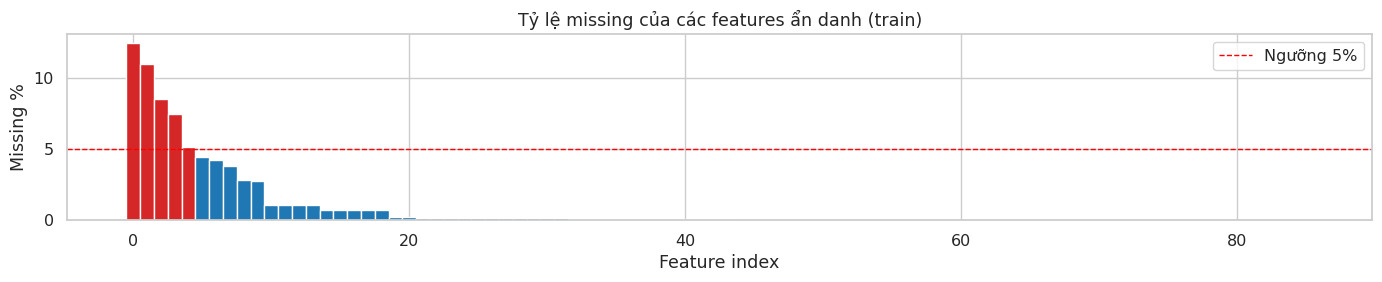

  Số features không có missing: 38
  Số features >5% missing     : 5
  Số features >20% missing    : 0


In [6]:
# =============================================================
# 4. CHẤT LƯỢNG DỮ LIỆU
# =============================================================

# ── 4.1 Missing values tổng quan ─────────────────────────────
print('── 4.1 Missing Values ──')
for df_name, df in [('TRAIN', train), ('TEST', test)]:
    miss = df.isnull().sum()
    miss_pct = (miss / len(df) * 100).round(3)
    miss_df = pd.DataFrame({'missing_count': miss, 'missing_pct': miss_pct})
    miss_df = miss_df[miss_df['missing_count'] > 0].sort_values('missing_pct', ascending=False)
    print(f'\n  {df_name}: {len(miss_df)} cột có missing values')
    if len(miss_df):
        display(miss_df.head(20))
    else:
        print('  ✅ Không có missing values.')

# ── 4.2 Heatmap missing cho features ─────────────────────────
print('\n── 4.2 Tỷ lệ missing của 86 features ──')
feat_miss = (train[feature_cols].isnull().mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(14, 3))
colors = ['#d62728' if v > 5 else '#1f77b4' for v in feat_miss.values]
plt.bar(range(len(feat_miss)), feat_miss.values, color=colors, width=1.0)
plt.axhline(5, color='red', linestyle='--', linewidth=1, label='Ngưỡng 5%')
plt.xlabel('Feature index')
plt.ylabel('Missing %')
plt.title('Tỷ lệ missing của các features ẩn danh (train)')
plt.legend()
plt.tight_layout()
plt.show()

print(f'  Số features không có missing: {(feat_miss == 0).sum()}')
print(f'  Số features >5% missing     : {(feat_miss > 5).sum()}')
print(f'  Số features >20% missing    : {(feat_miss > 20).sum()}')

In [7]:
# ── 4.3 Duplicate check ───────────────────────────────────────
print('── 4.3 Duplicate Check ──')
print(f'  Duplicate rows (train)    : {train.duplicated().sum():,}')
print(f'  Duplicate rows (test)     : {test.duplicated().sum():,}')

key_cols = GROUP_COLS + [TIME_COL]
dup_train_key = train.duplicated(subset=key_cols).sum()
dup_test_key  = test.duplicated(subset=key_cols).sum()
print(f'  Duplicate (group+time) train: {dup_train_key:,}')
print(f'  Duplicate (group+time) test : {dup_test_key:,}')

if ID_COL in train.columns:
    print(f'  Duplicate id (train)        : {train[ID_COL].duplicated().sum():,}')
if ID_COL in test.columns:
    print(f'  Duplicate id (test)         : {test[ID_COL].duplicated().sum():,}')

# ── 4.4 Near-constant features ────────────────────────────────
print('\n── 4.4 Near-Constant Features (dominant value > 99.5%) ──')
near_const = []
for c in feature_cols:
    vc = train[c].value_counts(dropna=False, normalize=True)
    if len(vc) > 0 and vc.iloc[0] > 0.995:
        near_const.append({'column': c, 'top_value': vc.index[0], 'top_share_pct': round(vc.iloc[0]*100, 3)})

if near_const:
    display(pd.DataFrame(near_const))
else:
    print('  ✅ Không có near-constant features.')

── 4.3 Duplicate Check ──
  Duplicate rows (train)    : 0
  Duplicate rows (test)     : 0
  Duplicate (group+time) train: 0
  Duplicate (group+time) test : 0
  Duplicate id (train)        : 0
  Duplicate id (test)         : 0

── 4.4 Near-Constant Features (dominant value > 99.5%) ──
  ✅ Không có near-constant features.


---
<a id='5'></a>
## 5. Phân Tích Nhóm (Group Analysis)

  Số nhóm (code×sub_code×sub_category×horizon) trong TRAIN: 36,923
  Số nhóm trong TEST : 11,039

── 5.1 Phân phối kích thước nhóm ──


,train_count,test_count
count,46087.00000,46087.00000
mean,115.81170,31.39946
std,76.88247,63.26699
min,0.00000,0.00000
1%,0.00000,0.00000
5%,0.00000,0.00000
25%,42.00000,0.00000
50%,137.00000,0.00000
75%,186.00000,0.00000
95%,204.00000,193.00000


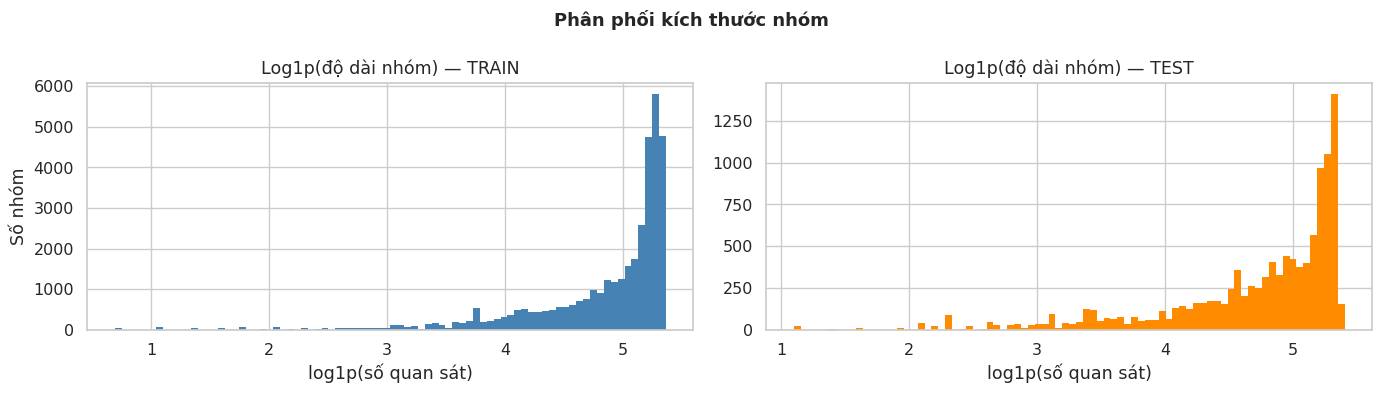

  Nhóm có ≤5 quan sát (train): 0.63% — nguy cơ lag/rolling bị NaN nhiều!


In [8]:
# =============================================================
# 5. GROUP ANALYSIS
# =============================================================

def group_key(df, cols):
    return df[cols].astype(str).agg('__'.join, axis=1)

train['__gid__'] = group_key(train, GROUP_COLS)
test['__gid__']  = group_key(test,  GROUP_COLS)

n_train_groups = train['__gid__'].nunique()
n_test_groups  = test['__gid__'].nunique()

print(f'  Số nhóm (code×sub_code×sub_category×horizon) trong TRAIN: {n_train_groups:,}')
print(f'  Số nhóm trong TEST : {n_test_groups:,}')

# ── 5.1 Phân phối kích thước nhóm ────────────────────────────
train_gsize = train['__gid__'].value_counts().rename('train_count')
test_gsize  = test['__gid__'].value_counts().rename('test_count')

gsize_df = pd.concat([train_gsize, test_gsize], axis=1).fillna(0)

print('\n── 5.1 Phân phối kích thước nhóm ──')
display(gsize_df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(np.log1p(train_gsize.values), bins=80, color='steelblue', edgecolor='none')
axes[0].set_title('Log1p(độ dài nhóm) — TRAIN')
axes[0].set_xlabel('log1p(số quan sát)')
axes[0].set_ylabel('Số nhóm')

axes[1].hist(np.log1p(test_gsize.values), bins=80, color='darkorange', edgecolor='none')
axes[1].set_title('Log1p(độ dài nhóm) — TEST')
axes[1].set_xlabel('log1p(số quan sát)')

plt.suptitle('Phân phối kích thước nhóm', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

short_pct = (train_gsize <= 5).mean() * 100
print(f'  Nhóm có ≤5 quan sát (train): {short_pct:.2f}% — nguy cơ lag/rolling bị NaN nhiều!')

In [9]:
# ── 5.2 Nhóm mới trong test chưa thấy trong train ────────────
new_groups = sorted(set(test['__gid__']) - set(train['__gid__']))
print(f'  Nhóm mới trong TEST (chưa thấy trong TRAIN): {len(new_groups):,}')
if new_groups:
    print('  → Các nhóm này sẽ không có lịch sử lag/rolling từ train!')
    display(pd.DataFrame({'new_group_in_test': new_groups[:20]}))
else:
    print('  ✅ Tất cả nhóm test đều xuất hiện trong train.')

# ── 5.3 Value counts từng GROUP_COL ──────────────────────────
print('\n── 5.3 Value counts từng biến nhóm ──')
for c in GROUP_COLS:
    vc = train[c].value_counts(dropna=False)
    print(f'\n  [{c}]  nunique={vc.shape[0]:,}')
    display(vc.head(10).rename('count').reset_index().rename(columns={'index': c}))

  Nhóm mới trong TEST (chưa thấy trong TRAIN): 9,164
  → Các nhóm này sẽ không có lịch sử lag/rolling từ train!


,new_group_in_test
0,10BAVIDU__07YQ9WA4__DPPUO5X2__1
1,10BAVIDU__07YQ9WA4__DPPUO5X2__10
2,10BAVIDU__07YQ9WA4__DPPUO5X2__25
3,10BAVIDU__07YQ9WA4__DPPUO5X2__3
4,10BAVIDU__07YQ9WA4__NQ58FVQM__1
5,10BAVIDU__07YQ9WA4__NQ58FVQM__10
6,10BAVIDU__07YQ9WA4__NQ58FVQM__25
7,10BAVIDU__07YQ9WA4__NQ58FVQM__3
8,10BAVIDU__07YQ9WA4__PHHHVYZI__1
9,10BAVIDU__07YQ9WA4__PHHHVYZI__10



── 5.3 Value counts từng biến nhóm ──

  [code]  nunique=23


,code,count
0,OSJL3A7Y,564790
1,6LB028J8,484082
2,K7Y1TTAH,324479
3,VFWIFJPS,318517
4,W2MW3G2L,305116
5,1HEMHZK2,293024
6,660DZME0,264071
7,4KUR2ZOZ,263685
8,SJZP0OVU,237283
9,84J8BJFZ,234375



  [sub_code]  nunique=180


,sub_code,count
0,69SD4Y3A,69521
1,OYJGNSQK,69390
2,TI04KMOC,68844
3,XT8JWYHT,68515
4,PCXKOBIH,68383
5,J7UUOGYG,66946
6,9G2OWCRE,65507
7,DYJUJX3J,64163
8,CUXV51HW,60184
9,FECMBC0A,59645



  [sub_category]  nunique=5


,sub_category,count
0,PZ9S1Z4V,1074239
1,DPPUO5X2,1072705
2,NQ58FVQM,1067164
3,PHHHVYZI,1067164
4,V8BKY1IV,1056142



  [horizon]  nunique=4


,horizon,count
0,1,1394653
1,3,1385816
2,10,1337236
3,25,1219709


---
<a id='6'></a>
## 6. Phân Tích Cấu Trúc Thời Gian

── 6.1 Phạm vi ts_index ──
  TRAIN: 1 → 3601  (3,601 điểm duy nhất)
  TEST : 3602  → 4376  (775 điểm duy nhất)
  Overlap (chung cả hai): 0 time steps
  Test nằm ngoài train  : 775 time steps

── 6.2 Phân phối bước thời gian (diff) ──
  TRAIN time diffs:


count   3600.00000
mean       1.00000
std        0.00000
min        1.00000
25%        1.00000
50%        1.00000
75%        1.00000
max        1.00000
dtype: float64

  TEST time diffs:


count   774.00000
mean      1.00000
std       0.00000
min       1.00000
25%       1.00000
50%       1.00000
75%       1.00000
max       1.00000
dtype: float64

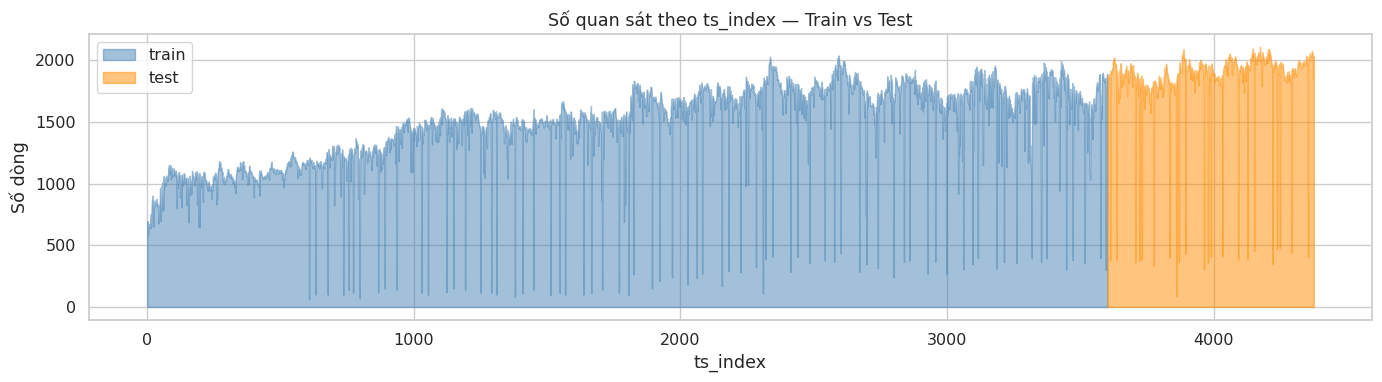

In [10]:
# =============================================================
# 6. CẤU TRÚC THỜI GIAN
# =============================================================

train_times = np.sort(train[TIME_COL].unique())
test_times  = np.sort(test[TIME_COL].unique())

print('── 6.1 Phạm vi ts_index ──')
print(f'  TRAIN: {train[TIME_COL].min()} → {train[TIME_COL].max()}  ({len(train_times):,} điểm duy nhất)')
print(f'  TEST : {test[TIME_COL].min()}  → {test[TIME_COL].max()}  ({len(test_times):,} điểm duy nhất)')

overlap = set(train_times) & set(test_times)
print(f'  Overlap (chung cả hai): {len(overlap):,} time steps')
print(f'  Test nằm ngoài train  : {(set(test_times) - set(train_times)).__len__():,} time steps')

# ── 6.2 Bước thời gian ───────────────────────────────────────
print('\n── 6.2 Phân phối bước thời gian (diff) ──')
train_diffs = pd.Series(np.diff(train_times))
test_diffs  = pd.Series(np.diff(test_times))
print('  TRAIN time diffs:')
display(train_diffs.describe())
print('  TEST time diffs:')
display(test_diffs.describe())

# ── 6.3 Record count theo thời gian ──────────────────────────
time_cnt_train = train[TIME_COL].value_counts().sort_index()
time_cnt_test  = test[TIME_COL].value_counts().sort_index()

plt.figure(figsize=FIGSIZE_WIDE)
plt.fill_between(time_cnt_train.index, time_cnt_train.values, alpha=0.5, label='train', color='steelblue')
plt.fill_between(time_cnt_test.index,  time_cnt_test.values,  alpha=0.5, label='test',  color='darkorange')
plt.title('Số quan sát theo ts_index — Train vs Test')
plt.xlabel('ts_index')
plt.ylabel('Số dòng')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# ── 6.4 Khoảng cách thời gian trong từng nhóm ─────────────────
print('── 6.4 Within-group time gaps ──')
tmp = train[GROUP_COLS + [TIME_COL]].sort_values(GROUP_COLS + [TIME_COL]).copy()
tmp['time_diff'] = tmp.groupby(GROUP_COLS)[TIME_COL].diff()

gap_sum = tmp['time_diff'].dropna()
print(f'  Bước thời gian trung bình trong nhóm : {gap_sum.mean():.3f}')
print(f'  Bước thời gian median               : {gap_sum.median():.3f}')
print(f'  Bước thời gian max                  : {gap_sum.max():.3f}')

threshold_99 = gap_sum.quantile(0.99)
large_gaps = tmp[tmp['time_diff'] > threshold_99]
print(f'\n  Số khoảng cách bất thường (>P99={threshold_99:.1f}): {len(large_gaps):,}')
if len(large_gaps):
    print('  ⚠️  Cảnh báo: Có gaps lớn trong chuỗi — lag features sẽ bị ảnh hưởng!')
    display(large_gaps.head(10))

── 6.4 Within-group time gaps ──
  Bước thời gian trung bình trong nhóm : 1.057
  Bước thời gian median               : 1.000
  Bước thời gian max                  : 142.000

  Số khoảng cách bất thường (>P99=2.0): 25,680
  ⚠️  Cảnh báo: Có gaps lớn trong chuỗi — lag features sẽ bị ảnh hưởng!


,code,sub_code,sub_category,horizon,ts_index,time_diff
1735044,10BAVIDU,236HB58W,NQ58FVQM,1,3544,3.00000
1735046,10BAVIDU,236HB58W,NQ58FVQM,3,3544,3.00000
1735047,10BAVIDU,236HB58W,NQ58FVQM,10,3544,3.00000
1735045,10BAVIDU,236HB58W,NQ58FVQM,25,3544,3.00000
1762018,10BAVIDU,236HB58W,PHHHVYZI,1,3544,3.00000
1762015,10BAVIDU,236HB58W,PHHHVYZI,3,3544,3.00000
1762017,10BAVIDU,236HB58W,PHHHVYZI,10,3544,3.00000
1762016,10BAVIDU,236HB58W,PHHHVYZI,25,3544,3.00000
1654165,10BAVIDU,236HB58W,PZ9S1Z4V,1,3544,3.00000
1654162,10BAVIDU,236HB58W,PZ9S1Z4V,3,3544,3.00000


---
<a id='7'></a>
## 7. Phân Phối Biến Mục Tiêu (Target)

── 7.1 Thống kê mô tả Target ──


count   5337414.00000
mean         -0.66590
std          32.52764
min       -2201.88158
0.1%       -337.47323
1%          -82.79722
5%           -7.60681
25%          -0.12908
50%          -0.00058
75%           0.05107
95%           4.50475
99%          62.92342
99.9%       320.93700
max        2314.41115
Name: y_target, dtype: float64

  Missing pct  : 0.0000%
  Zero pct     : 0.0305%
  Negative pct : 54.3098%
  Skewness     : 1.1886
  Kurtosis     : 289.7651


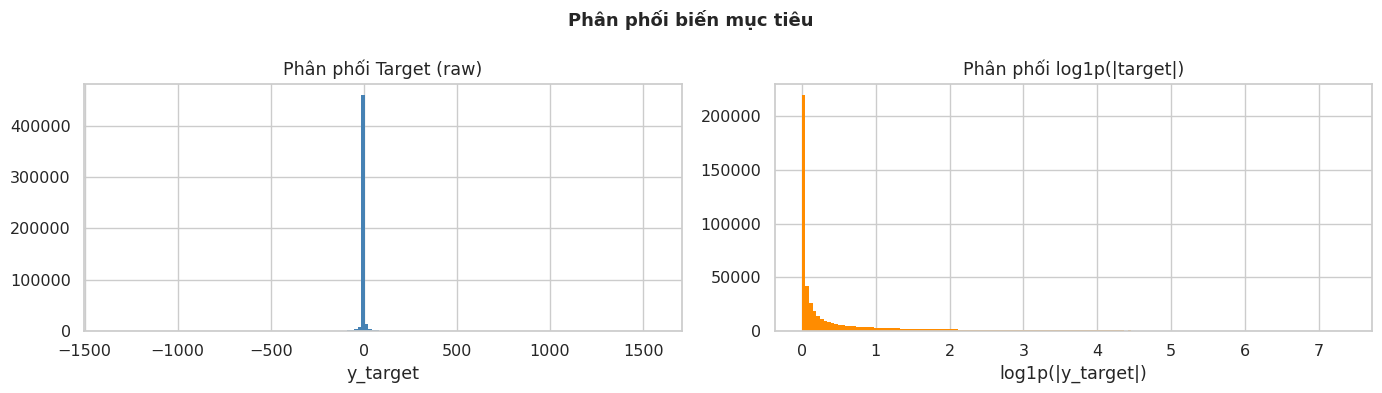

In [12]:
# =============================================================
# 7. PHÂN PHỐI TARGET
# =============================================================

target = train[TARGET_COL]

# ── 7.1 Thống kê mô tả ───────────────────────────────────────
print('── 7.1 Thống kê mô tả Target ──')
display(target.describe(percentiles=[0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]))

print(f'  Missing pct  : {target.isna().mean()*100:.4f}%')
print(f'  Zero pct     : {(target == 0).mean()*100:.4f}%')
print(f'  Negative pct : {(target < 0).mean()*100:.4f}%')
print(f'  Skewness     : {target.dropna().skew():.4f}')
print(f'  Kurtosis     : {target.dropna().kurt():.4f}')

# ── 7.2 Histogram target gốc & log-abs ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sample_t = target.dropna().sample(min(len(target.dropna()), 500_000), random_state=RANDOM_SEED)

axes[0].hist(sample_t, bins=150, color='steelblue', edgecolor='none')
axes[0].set_title('Phân phối Target (raw)')
axes[0].set_xlabel(TARGET_COL)

axes[1].hist(np.log1p(np.abs(sample_t)), bins=150, color='darkorange', edgecolor='none')
axes[1].set_title('Phân phối log1p(|target|)')
axes[1].set_xlabel('log1p(|y_target|)')

plt.suptitle('Phân phối biến mục tiêu', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

── 7.3 Target stats theo horizon ──


,count,mean,std,median,q1,q3
horizon,,,,,,
1,1394653,-0.08270,11.69970,-0.00020,-0.05070,0.02350
3,1385816,-0.25240,19.36120,-0.00040,-0.09150,0.04440
10,1337236,-0.77600,33.84210,-0.00090,-0.18400,0.07520
25,1219709,-1.68190,52.82330,-0.00190,-0.31890,0.11400


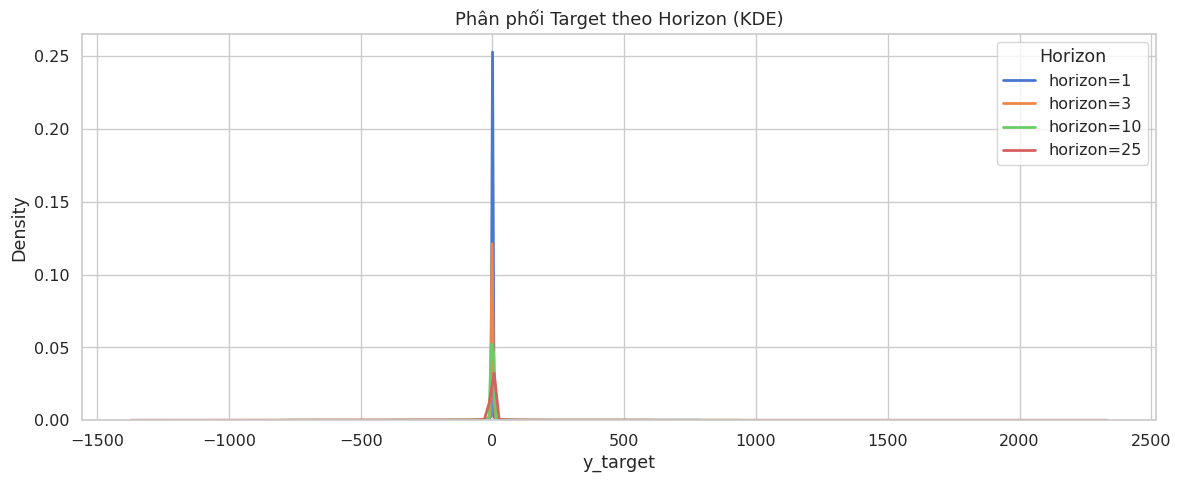


── 7.4 Xu hướng Target theo ts_index ──


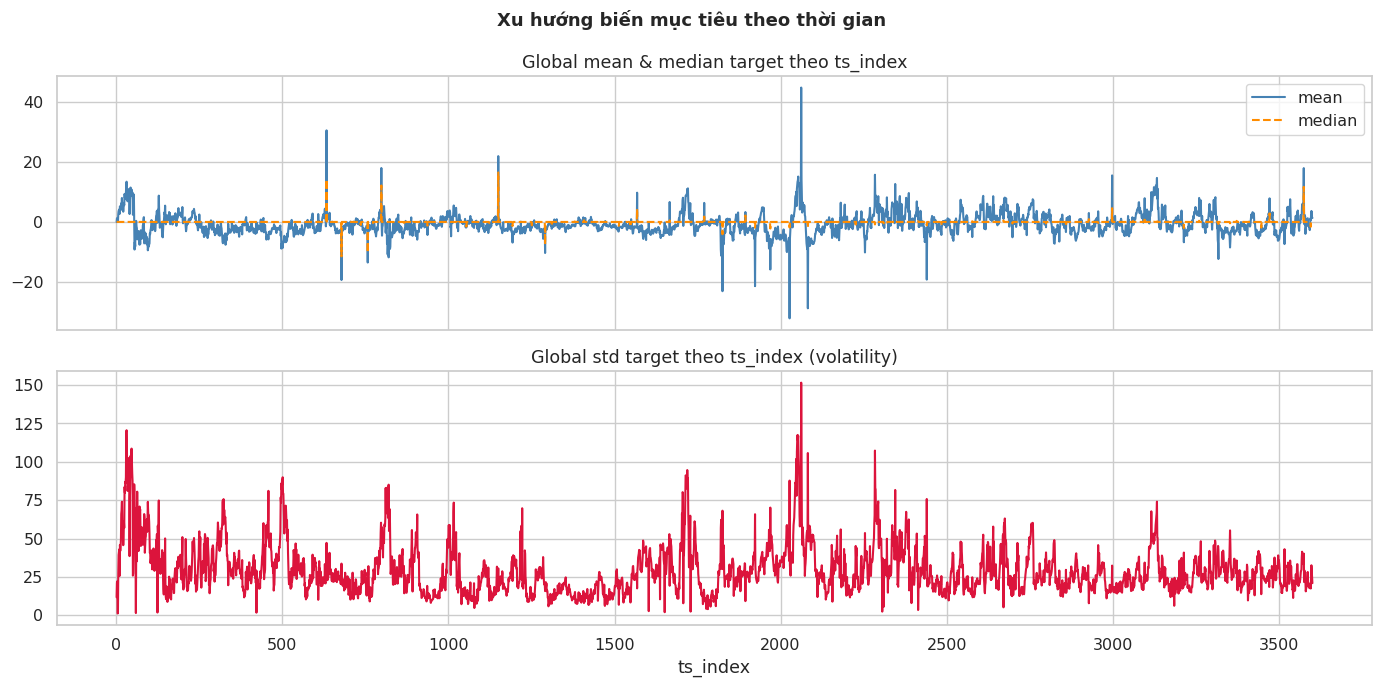

In [13]:
# ── 7.3 Target theo từng horizon ─────────────────────────────
print('── 7.3 Target stats theo horizon ──')
horizon_stats = train.groupby('horizon')[TARGET_COL].agg(
    count='count', mean='mean', std='std', median='median',
    q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75)
).round(4)
display(horizon_stats)

# KDE plot per horizon
plt.figure(figsize=(12, 5))
colors_h = {'1': '#1f77b4', '3': '#ff7f0e', '10': '#2ca02c', '25': '#d62728'}
for h in HORIZONS:
    vals = train.loc[train['horizon'] == h, TARGET_COL].dropna()
    vals = vals.sample(min(len(vals), 50_000), random_state=RANDOM_SEED)
    sns.kdeplot(vals, label=f'horizon={h}', linewidth=2)

plt.title('Phân phối Target theo Horizon (KDE)', fontsize=13)
plt.xlabel(TARGET_COL)
plt.legend(title='Horizon')
plt.tight_layout()
plt.show()

# ── 7.4 Trend của target theo thời gian ──────────────────────
print('\n── 7.4 Xu hướng Target theo ts_index ──')
global_time = train.groupby(TIME_COL)[TARGET_COL].agg(
    mean='mean', median='median', std='std', count='count'
).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(global_time[TIME_COL], global_time['mean'],   color='steelblue', label='mean',   linewidth=1.5)
axes[0].plot(global_time[TIME_COL], global_time['median'], color='darkorange', label='median', linewidth=1.5, linestyle='--')
axes[0].set_title('Global mean & median target theo ts_index')
axes[0].legend()

axes[1].plot(global_time[TIME_COL], global_time['std'], color='crimson', linewidth=1.5)
axes[1].set_title('Global std target theo ts_index (volatility)')
axes[1].set_xlabel('ts_index')

plt.suptitle('Xu hướng biến mục tiêu theo thời gian', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

── 7.5 Chuỗi thời gian của các nhóm đại diện ──


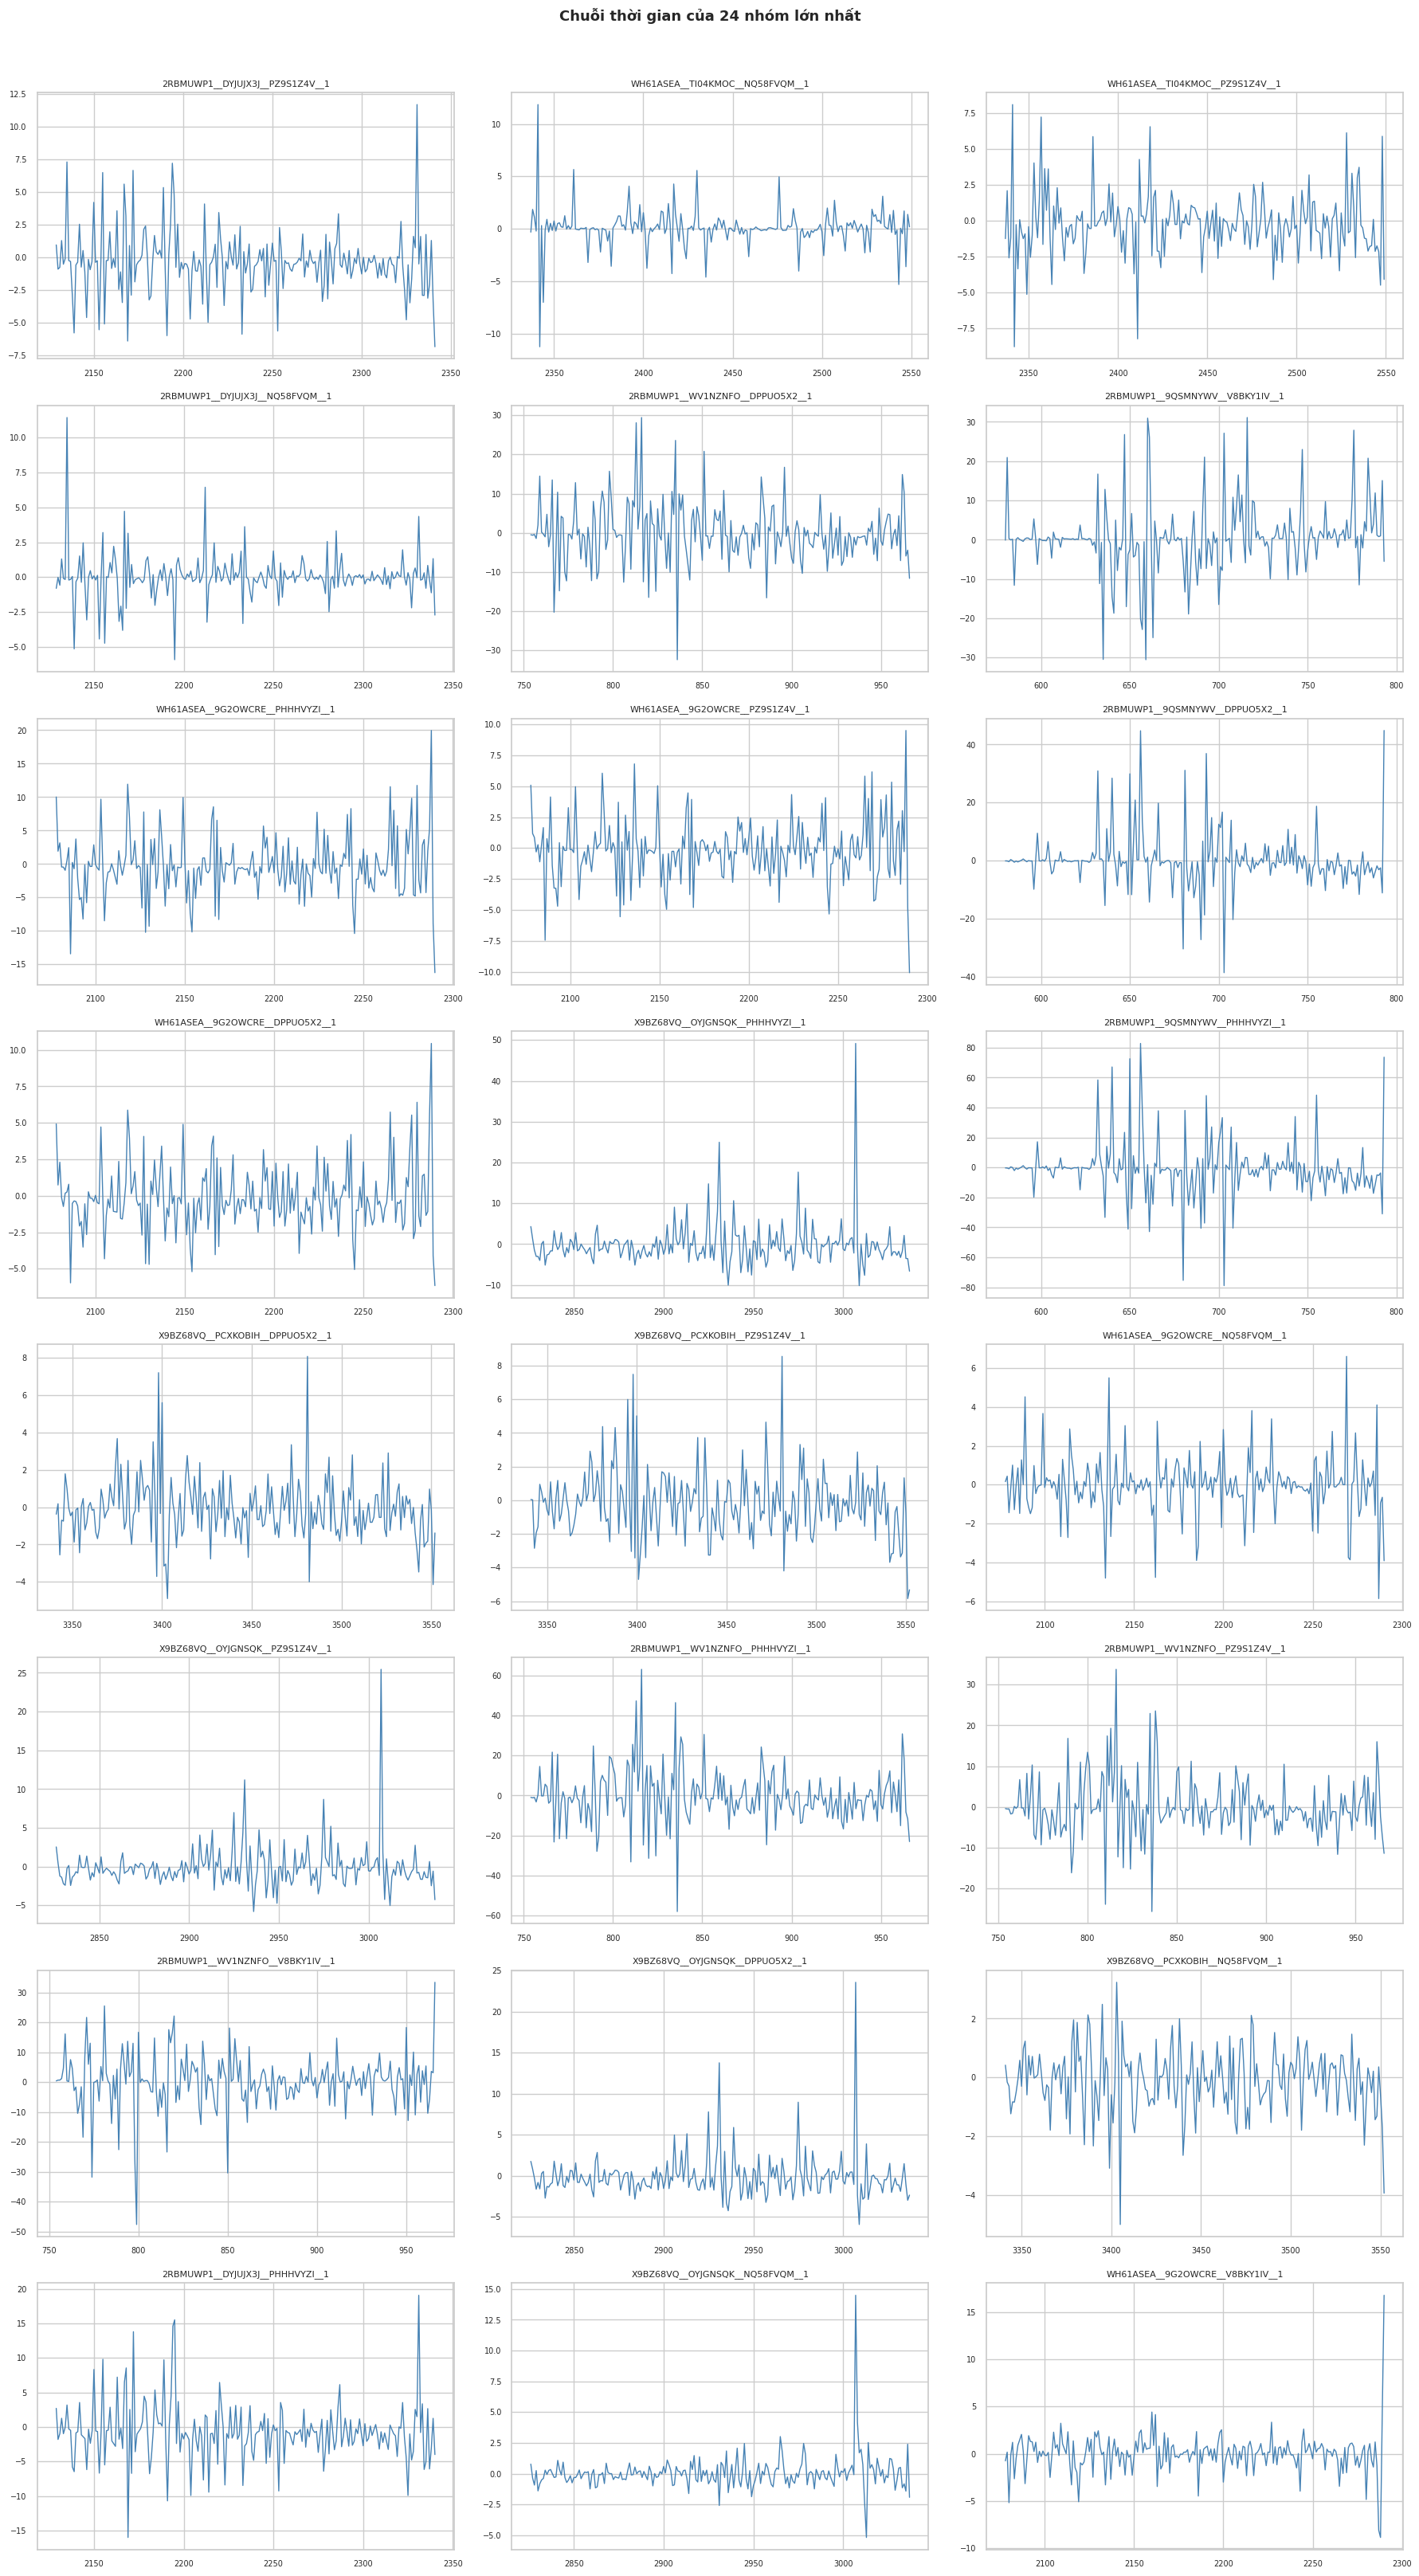

In [14]:
# ── 7.5 Biểu đồ chuỗi thời gian của các nhóm đại diện ────────
print('── 7.5 Chuỗi thời gian của các nhóm đại diện ──')
group_sizes = train['__gid__'].value_counts()
top_groups  = group_sizes.head(MAX_GROUPS_FOR_SERIES_PLOT).index.tolist()

ncols = 3
nrows = math.ceil(len(top_groups) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows), squeeze=False)

for ax, grp in zip(axes.flatten(), top_groups):
    s = train.loc[train['__gid__'] == grp, [TIME_COL, TARGET_COL]].sort_values(TIME_COL)
    ax.plot(s[TIME_COL], s[TARGET_COL], linewidth=1, color='steelblue')
    ax.set_title(str(grp)[:55], fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes.flatten()[len(top_groups):]:
    ax.axis('off')

fig.suptitle(f'Chuỗi thời gian của {len(top_groups)} nhóm lớn nhất', y=1.01, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
<a id='8'></a>
## 8. Phân Tích Features Số

── 8.1 Thống kê mô tả 86 features (sample) ──


,feature,dtype,missing_pct,nunique,mean,std,min,p01,p50,p99,max,skew
45,feature_at,float64,12.47200,32098,3298.81428,13786.68991,0.00000,0.00000,13.74325,60364.21350,550471.41265,10.31873
76,feature_by,float64,11.01900,255087,-0.08121,0.31712,-30.22303,-1.31246,-0.00507,-0.00002,-0.00000,-16.24430
50,feature_ay,float64,8.54200,37895,4322.41259,15601.96771,0.00000,0.00000,96.57839,72800.40388,600894.65541,8.88671
81,feature_cd,float64,7.49600,264690,-0.82394,3.24358,-247.59014,-15.02089,-0.00157,-0.00006,0.00005,-10.44290
82,feature_ce,float64,5.16800,90979,-0.02288,0.17290,-7.68457,-0.51583,-0.00189,0.36321,2.64211,-8.38337
83,feature_cf,float64,4.42900,77448,1.47268,1.49199,0.00613,0.02245,1.19716,5.63540,13.63492,0.89811
37,feature_al,float64,4.22300,5101308,-0.10203,10.60807,-343.12231,-26.32762,-0.00020,25.95998,614.78983,4.43916
48,feature_aw,float64,3.84400,62381,7069.56743,20798.28824,0.00000,0.00000,725.52740,91394.43879,787294.40542,9.48150
77,feature_bz,float64,2.84300,277562,-0.16449,0.73690,-55.48603,-3.55396,-0.01131,-0.00002,-0.00001,-11.50545
60,feature_bi,float64,2.76200,214836,22.20847,378.65054,0.00000,0.00000,0.58755,217.06485,66063.21557,77.86655



── 8.2 Pearson correlation với target ──


,feature,pearson_corr,abs_corr
77,feature_bz,0.07975,0.07975
81,feature_cd,0.07525,0.07525
31,feature_af,-0.06745,0.06745
20,feature_u,-0.06418,0.06418
66,feature_bo,-0.05731,0.05731
64,feature_bm,-0.05357,0.05357
18,feature_s,-0.05076,0.05076
19,feature_t,-0.03438,0.03438
38,feature_am,-0.03386,0.03386
14,feature_o,-0.03098,0.03098


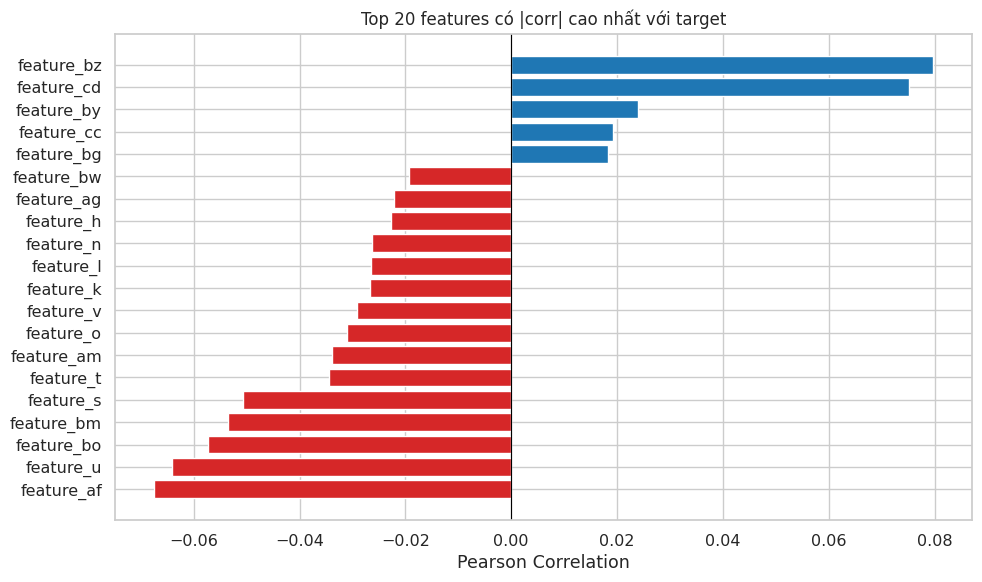

In [15]:
# =============================================================
# 8. PHÂN TÍCH FEATURES SỐ
# =============================================================

# ── 8.1 Thống kê mô tả các feature ───────────────────────────
print('── 8.1 Thống kê mô tả 86 features (sample) ──')

feat_stats = []
for c in feature_cols:
    s = train[c]
    feat_stats.append({
        'feature'     : c,
        'dtype'       : str(s.dtype),
        'missing_pct' : round(s.isna().mean()*100, 3),
        'nunique'     : int(s.nunique(dropna=True)),
        'mean'        : s.mean(),
        'std'         : s.std(),
        'min'         : s.min(),
        'p01'         : s.quantile(0.01),
        'p50'         : s.quantile(0.50),
        'p99'         : s.quantile(0.99),
        'max'         : s.max(),
        'skew'        : s.skew(),
    })

feat_stats_df = pd.DataFrame(feat_stats)
display(feat_stats_df.sort_values('missing_pct', ascending=False).head(40))

# ── 8.2 Correlation với target (sample để tránh OOM) ─────────
print('\n── 8.2 Pearson correlation với target ──')
corr_sample = train.sample(min(MAX_ROWS_FOR_CORR, len(train)), random_state=RANDOM_SEED)

corr_rows = []
for c in feature_cols:
    try:
        x = pd.to_numeric(corr_sample[c], errors='coerce')
        y = pd.to_numeric(corr_sample[TARGET_COL], errors='coerce')
        r = x.corr(y)
    except Exception:
        r = np.nan
    corr_rows.append({'feature': c, 'pearson_corr': r, 'abs_corr': abs(r) if pd.notna(r) else np.nan})

corr_df = pd.DataFrame(corr_rows).sort_values('abs_corr', ascending=False)
display(corr_df.head(30))

# ── 8.3 Bar chart top correlations ───────────────────────────
top_corr = corr_df.dropna().head(20).sort_values('pearson_corr')
colors_bar = ['#d62728' if v < 0 else '#1f77b4' for v in top_corr['pearson_corr']]

plt.figure(figsize=(10, 6))
plt.barh(top_corr['feature'], top_corr['pearson_corr'], color=colors_bar)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 20 features có |corr| cao nhất với target', fontsize=12)
plt.xlabel('Pearson Correlation')
plt.tight_layout()
plt.show()

── 8.4 Correlation matrix (top 20 features theo abs_corr) ──


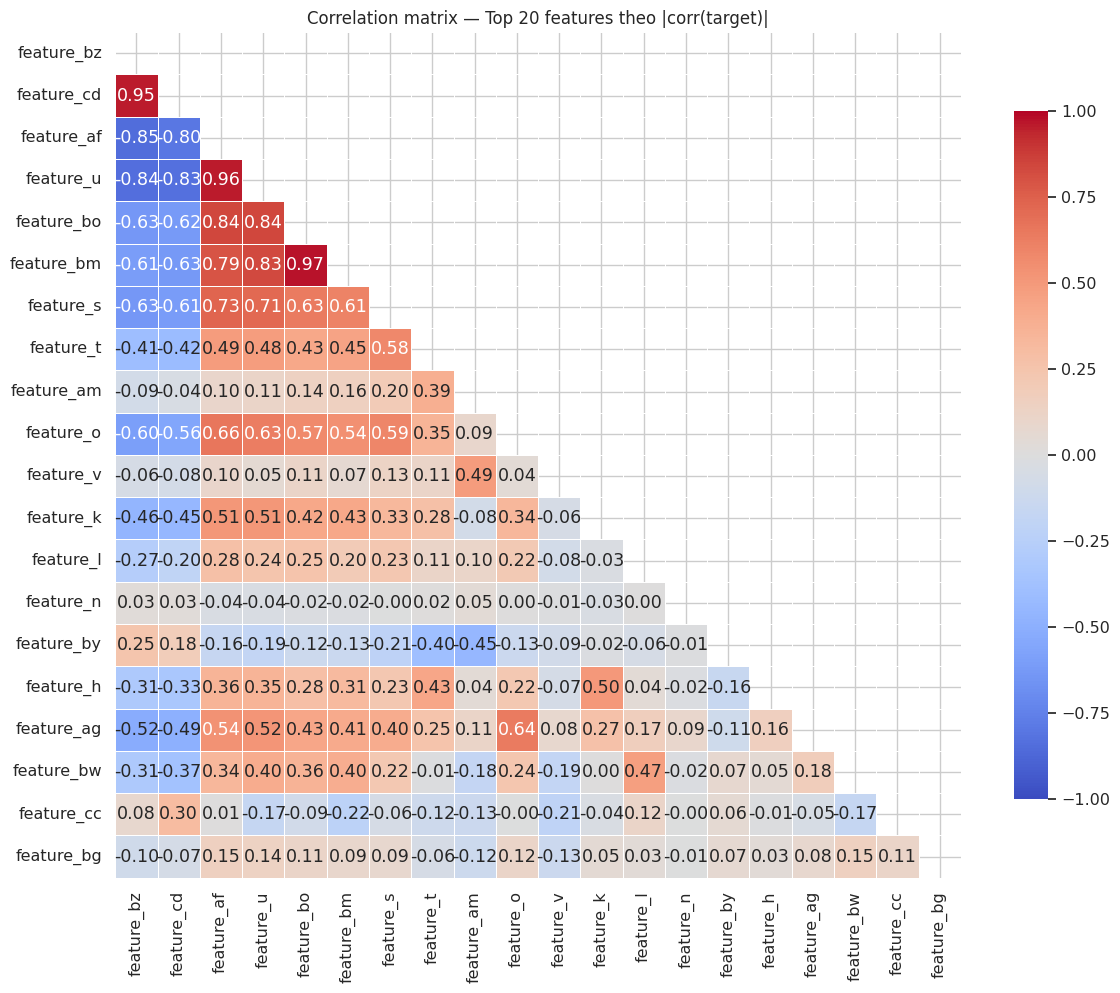


  ⚠️ Có 3 cặp feature có |corr| > 0.95 (nguy cơ multicollinearity):


,feature_1,feature_2,corr
0,feature_bz,feature_cd,0.95350
1,feature_af,feature_u,0.95680
2,feature_bo,feature_bm,0.97130


In [16]:
# ── 8.4 Correlation matrix giữa top features ─────────────────
print('── 8.4 Correlation matrix (top 20 features theo abs_corr) ──')
top20_feats = corr_df.dropna().head(20)['feature'].tolist()

corr_matrix_sample = train.sample(min(50_000, len(train)), random_state=RANDOM_SEED)
corr_matrix = corr_matrix_sample[top20_feats].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f',
    cmap='coolwarm', center=0, vmin=-1, vmax=1,
    linewidths=0.5, square=True, cbar_kws={'shrink': 0.8}
)
plt.title('Correlation matrix — Top 20 features theo |corr(target)|', fontsize=12)
plt.tight_layout()
plt.show()

# Cảnh báo multicollinearity
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        v = corr_matrix.iloc[i, j]
        if abs(v) > 0.95:
            high_corr_pairs.append({
                'feature_1': corr_matrix.columns[i],
                'feature_2': corr_matrix.columns[j],
                'corr': round(v, 4)
            })

if high_corr_pairs:
    print(f'\n  ⚠️ Có {len(high_corr_pairs)} cặp feature có |corr| > 0.95 (nguy cơ multicollinearity):')
    display(pd.DataFrame(high_corr_pairs))
else:
    print('\n  ✅ Không phát hiện multicollinearity cao (>0.95) trong top 20 features.')

---
<a id='9'></a>
## 9. Phân Tích Seasonality & Time Phase

── 9.1 Phase Analysis — tìm chu kỳ mạnh nhất ──


,period,std_of_phase_means,n_bins
9,20,0.22018,20
13,52,0.20131,52
12,30,0.18563,30
10,24,0.13101,24
11,28,0.12144,28
6,10,0.08666,10
7,12,0.08208,12
8,14,0.07530,14
4,6,0.07041,6
3,5,0.06866,5


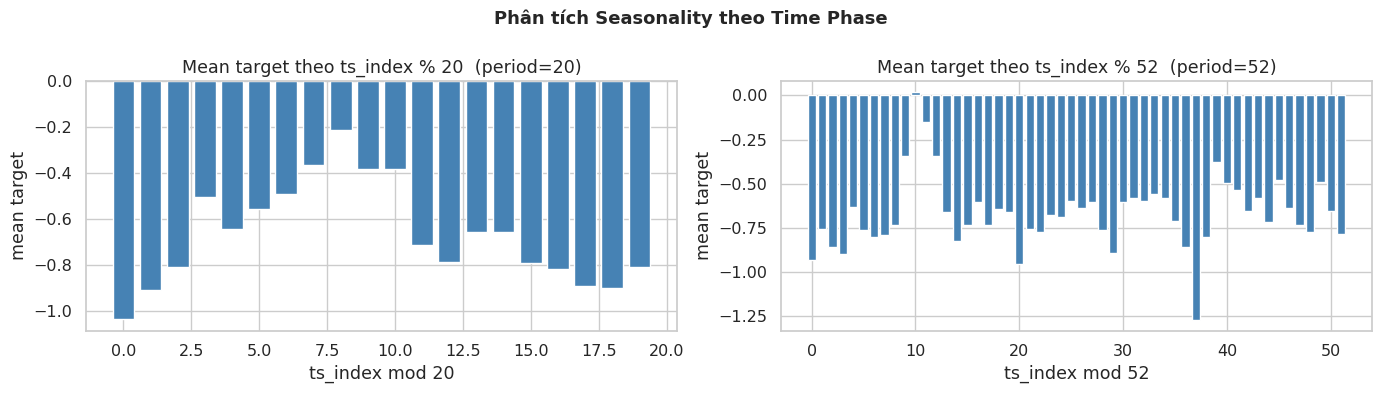

In [17]:
# =============================================================
# 9. SEASONALITY & TIME PHASE
# =============================================================
# Kiểm tra chu kỳ bằng cách tính phương sai của mean target
# theo các period modulo khác nhau

print('── 9.1 Phase Analysis — tìm chu kỳ mạnh nhất ──')

phase_df = train[[TIME_COL, TARGET_COL]].copy()
PERIODS  = [2, 3, 4, 5, 6, 7, 10, 12, 14, 20, 24, 28, 30, 52]

phase_stats = []
for p in PERIODS:
    phase_df[f'mod_{p}'] = phase_df[TIME_COL] % p
    grp = phase_df.groupby(f'mod_{p}')[TARGET_COL].agg(['mean', 'median', 'count'])
    dispersion = grp['mean'].std()
    phase_stats.append({
        'period'             : p,
        'std_of_phase_means' : round(dispersion, 5),
        'n_bins'             : len(grp),
    })

phase_stats_df = pd.DataFrame(phase_stats).sort_values('std_of_phase_means', ascending=False)
display(phase_stats_df)

# ── Vẽ top 2 chu kỳ mạnh nhất ─────────────────────────────────
top_periods = phase_stats_df.head(2)['period'].tolist()

fig, axes = plt.subplots(1, len(top_periods), figsize=(14, 4))
if len(top_periods) == 1:
    axes = [axes]

for ax, p in zip(axes, top_periods):
    grp = phase_df.groupby(f'mod_{p}')[TARGET_COL].mean().reset_index()
    ax.bar(grp[f'mod_{p}'], grp[TARGET_COL], color='steelblue', width=0.8)
    ax.set_title(f'Mean target theo ts_index % {p}  (period={p})')
    ax.set_xlabel(f'ts_index mod {p}')
    ax.set_ylabel('mean target')

plt.suptitle('Phân tích Seasonality theo Time Phase', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
<a id='10'></a>
## 10. Lag & Rolling Diagnostics

── 10.1 Tính toán lag & rolling trên subset nhóm ──
  ── Correlation của lag/rolling features với target ──


,feature,pearson_corr,abs_corr
0,lag_1,0.24341,0.24341
7,roll_mean_3,0.16236,0.16236
9,roll_mean_7,0.12619,0.12619
11,roll_mean_14,0.12074,0.12074
1,lag_2,0.11266,0.11266
13,roll_mean_28,0.09977,0.09977
14,roll_std_28,-0.03505,0.03505
8,roll_std_3,0.03475,0.03475
3,lag_5,0.02914,0.02914
6,lag_28,-0.02349,0.02349


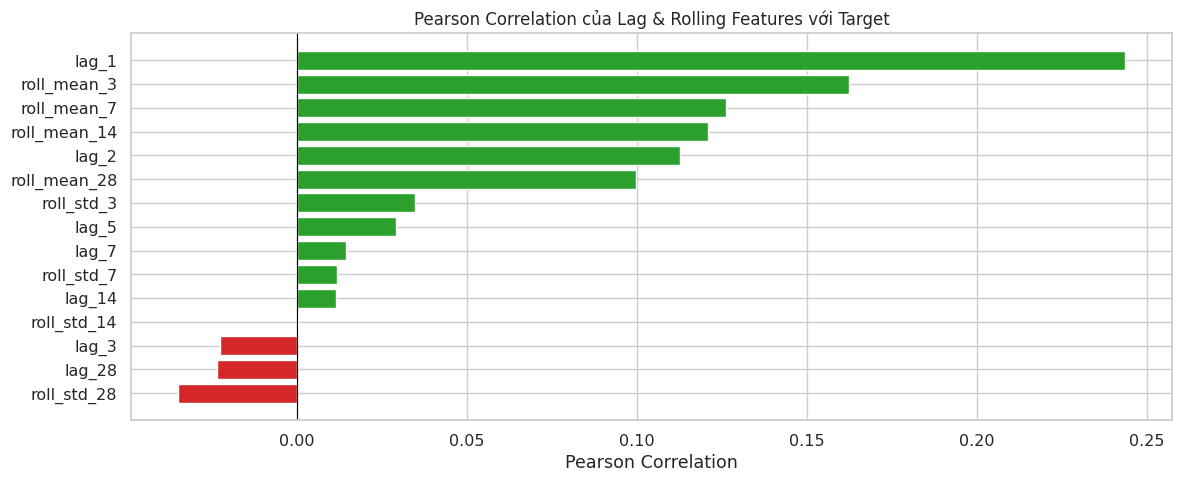

In [18]:
# =============================================================
# 10. LAG & ROLLING DIAGNOSTICS
# =============================================================
# Chọn subset nhóm đủ lịch sử để tính lag/rolling

print('── 10.1 Tính toán lag & rolling trên subset nhóm ──')

eligible = group_sizes[group_sizes >= 40].index
sample_gs = list(eligible[:min(MAX_GROUPS_FOR_LAG_ROLL, len(eligible))])
eda_sub = train[train['__gid__'].isin(sample_gs)].copy()
eda_sub = eda_sub.sort_values(GROUP_COLS + [TIME_COL]).reset_index(drop=True)

LAGS    = [1, 2, 3, 5, 7, 14, 28]
WINDOWS = [3, 7, 14, 28]

# Lag features — causal (shift trong nhóm)
for lag in LAGS:
    eda_sub[f'lag_{lag}'] = eda_sub.groupby(GROUP_COLS)[TARGET_COL].shift(lag)

# Rolling features — shift(1) trước để tránh data leakage
grouped_t = eda_sub.groupby(GROUP_COLS)[TARGET_COL]
for w in WINDOWS:
    eda_sub[f'roll_mean_{w}'] = grouped_t.transform(
        lambda s: s.shift(1).rolling(w, min_periods=max(2, w//2)).mean()
    )
    eda_sub[f'roll_std_{w}'] = grouped_t.transform(
        lambda s: s.shift(1).rolling(w, min_periods=max(2, w//2)).std()
    )

lag_roll_cols = [c for c in eda_sub.columns if c.startswith('lag_') or c.startswith('roll_')]

# Correlation với target
lr_corr_rows = []
sub_lr = eda_sub[[TARGET_COL] + lag_roll_cols].dropna(subset=[TARGET_COL])
for c in lag_roll_cols:
    r = pd.to_numeric(sub_lr[c], errors='coerce').corr(sub_lr[TARGET_COL])
    lr_corr_rows.append({'feature': c, 'pearson_corr': r, 'abs_corr': abs(r) if pd.notna(r) else np.nan})

lr_corr_df = pd.DataFrame(lr_corr_rows).sort_values('abs_corr', ascending=False)

print('  ── Correlation của lag/rolling features với target ──')
display(lr_corr_df)

# Bar chart
plt.figure(figsize=(12, 5))
top_lr = lr_corr_df.dropna().head(15).sort_values('pearson_corr')
colors_lr = ['#d62728' if v < 0 else '#2ca02c' for v in top_lr['pearson_corr']]
plt.barh(top_lr['feature'], top_lr['pearson_corr'], color=colors_lr)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Pearson Correlation của Lag & Rolling Features với Target', fontsize=12)
plt.xlabel('Pearson Correlation')
plt.tight_layout()
plt.show()

── 10.2 Missing rate của lag/rolling features ──


,feature,missing_pct
0,lag_1,0.47000
1,lag_2,0.95000
7,roll_mean_3,0.95000
8,roll_std_3,0.95000
9,roll_mean_7,1.42000
10,roll_std_7,1.42000
2,lag_3,1.42000
3,lag_5,2.37000
12,roll_std_14,3.32000
11,roll_mean_14,3.32000


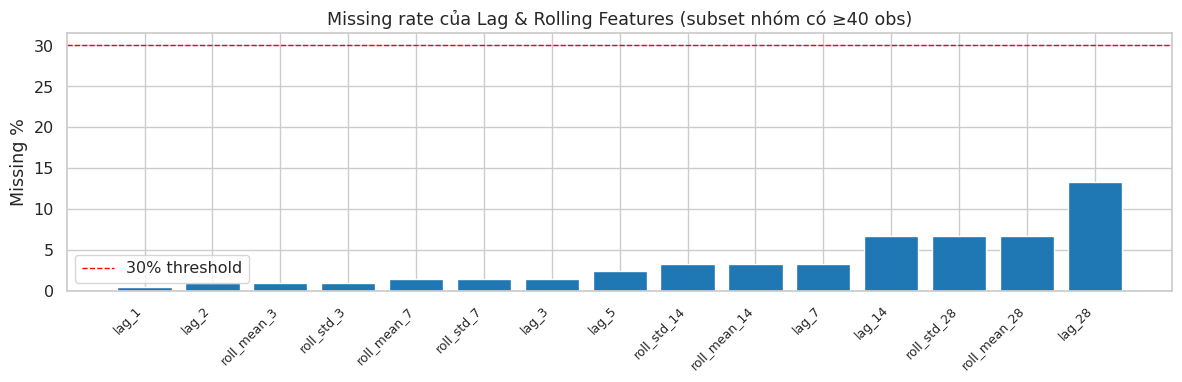


  💡 Lưu ý: Lag dài (lag_28) có missing rate cao hơn trên các nhóm chuỗi ngắn.


In [19]:
# ── 10.2 Missing rate của lag/rolling features ────────────────
print('── 10.2 Missing rate của lag/rolling features ──')
lag_miss_df = pd.DataFrame({
    'feature'     : lag_roll_cols,
    'missing_pct' : [round(eda_sub[c].isna().mean()*100, 2) for c in lag_roll_cols]
}).sort_values('missing_pct')

display(lag_miss_df)

plt.figure(figsize=(12, 4))
plt.bar(lag_miss_df['feature'], lag_miss_df['missing_pct'],
        color=['#d62728' if v > 30 else '#1f77b4' for v in lag_miss_df['missing_pct']])
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.axhline(30, color='red', linestyle='--', linewidth=1, label='30% threshold')
plt.title('Missing rate của Lag & Rolling Features (subset nhóm có ≥40 obs)')
plt.ylabel('Missing %')
plt.legend()
plt.tight_layout()
plt.show()

print('\n  💡 Lưu ý: Lag dài (lag_28) có missing rate cao hơn trên các nhóm chuỗi ngắn.')

---
<a id='11'></a>
## 11. Kiểm Tra Data Leakage

In [20]:
# =============================================================
# 11. DATA LEAKAGE CHECKS
# =============================================================

# ── 11.1 Feature nào có abs_corr > 0.995 với target? ─────────
print('── 11.1 Suspicious features (|corr| ≥ 0.995) ──')
suspicious = corr_df[corr_df['abs_corr'] >= 0.995]
if len(suspicious):
    print('  ⚠️  CẢNH BÁO: Các features sau có tương quan cực cao với target!')
    print('  → Có thể là data leakage hoặc feature đã được tính từ target.')
    display(suspicious)
else:
    print('  ✅ Không tìm thấy feature nghi ngờ leakage (|corr| < 0.995).')

# ── 11.2 Kiểm tra tương quan với FUTURE target ────────────────
print('\n── 11.2 Future Target Correlation Test ──')
print('  (Nếu feature_x tương quan cao với future target → khả năng leakage)\n')

future_diag = train[GROUP_COLS + [TIME_COL, TARGET_COL]].copy().sort_values(GROUP_COLS + [TIME_COL])
for f in [1, 2, 3]:
    future_diag[f'future_y_{f}'] = future_diag.groupby(GROUP_COLS)[TARGET_COL].shift(-f)

# Lấy sample + top features
top_feats_check = corr_df.dropna().head(30)['feature'].tolist()
key_cols = GROUP_COLS + [TIME_COL]
fd_merge = future_diag.merge(train[key_cols + top_feats_check], on=key_cols, how='left')
fd_sample = fd_merge.sample(min(80_000, len(fd_merge)), random_state=RANDOM_SEED)

future_corr_rows = []
for c in top_feats_check:
    x = pd.to_numeric(fd_sample[c], errors='coerce')
    for f in [1, 2, 3]:
        y = pd.to_numeric(fd_sample[f'future_y_{f}'], errors='coerce')
        r = x.corr(y)
        future_corr_rows.append({
            'feature'              : c,
            'future_hop'           : f,
            'corr_with_future_y'   : round(r, 4) if pd.notna(r) else np.nan,
            'abs_corr_future'      : round(abs(r), 4) if pd.notna(r) else np.nan,
        })

future_corr_df = pd.DataFrame(future_corr_rows).sort_values('abs_corr_future', ascending=False)
display(future_corr_df.head(30))

high_future = future_corr_df[future_corr_df['abs_corr_future'] >= 0.5]
if len(high_future):
    print(f'\n  ⚠️  {len(high_future)} cặp (feature, hop) có |corr with future target| ≥ 0.5!')
else:
    print('\n  ✅ Không phát hiện future leakage rõ ràng.')

── 11.1 Suspicious features (|corr| ≥ 0.995) ──
  ✅ Không tìm thấy feature nghi ngờ leakage (|corr| < 0.995).

── 11.2 Future Target Correlation Test ──
  (Nếu feature_x tương quan cao với future target → khả năng leakage)



,feature,future_hop,corr_with_future_y,abs_corr_future
0,feature_bz,1,0.08830,0.08830
3,feature_cd,1,0.08500,0.08500
1,feature_bz,2,0.07430,0.07430
6,feature_af,1,-0.07150,0.07150
4,feature_cd,2,0.07050,0.07050
2,feature_bz,3,0.06830,0.06830
9,feature_u,1,-0.06630,0.06630
5,feature_cd,3,0.06500,0.06500
8,feature_af,3,-0.05950,0.05950
7,feature_af,2,-0.05870,0.05870



  ✅ Không phát hiện future leakage rõ ràng.


---
<a id='12'></a>
## 12. Phân Tích Drift Train vs Test

── 12.1 Mean & Std drift của numeric features ──


,feature,train_mean,test_mean,mean_shift_abs,mean_shift_pct,train_std,test_std,train_miss_pct,test_miss_pct
15,feature_n,0.00299,0.72048,0.71750,24009.73500,1.40377,12.25295,0.16700,0.00000
34,feature_ag,1.23368,101.23942,100.00574,8106.29500,9.85643,1257.41818,0.15200,0.00000
39,feature_al,-0.10203,2.17118,2.27321,2227.96400,10.60807,96.87347,4.22300,3.25900
26,feature_y,-15.78598,98.95753,114.74351,726.87000,125.39236,322.92116,0.11600,38.57600
25,feature_x,-3.08907,19.34870,22.43777,726.36000,55.53752,140.03353,0.11600,38.57600
24,feature_w,-1.51026,9.45218,10.96244,725.86400,42.20387,111.98443,0.11600,38.57600
27,feature_z,-26.80834,135.01911,161.82745,603.64600,156.56167,346.19993,0.11600,38.57600
60,feature_bg,0.02939,0.20108,0.17169,584.22600,0.06250,0.23697,0.00000,0.06100
16,feature_o,1.05675,6.93125,5.87450,555.90100,7.29322,76.60743,0.11700,0.00000
32,feature_ae,1.20191,6.11591,4.91399,408.84700,5.25123,43.63428,0.15200,0.00000


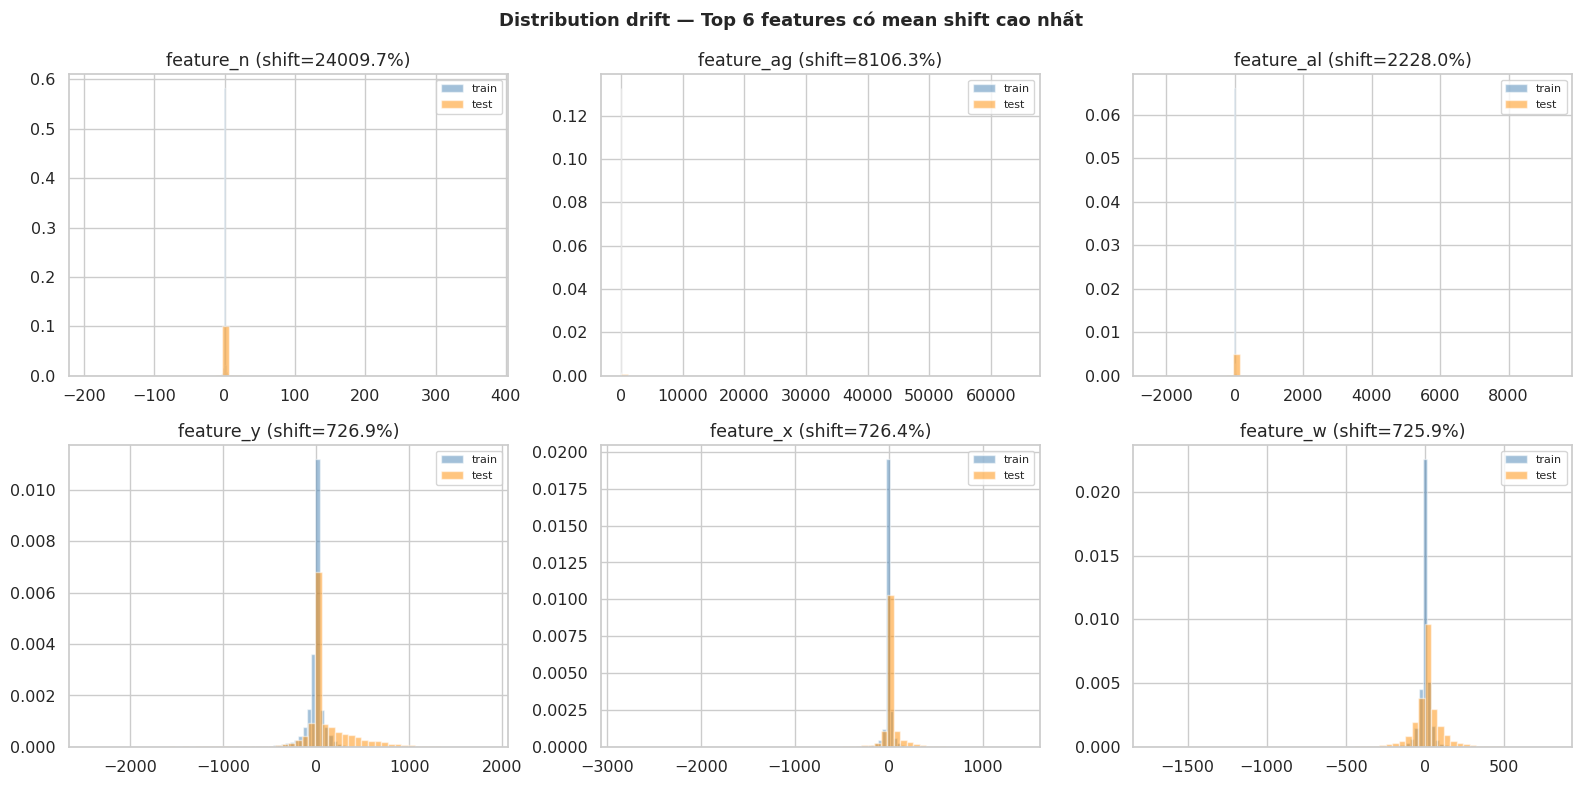

In [21]:
# =============================================================
# 12. TRAIN-TEST DRIFT ANALYSIS
# =============================================================

print('── 12.1 Mean & Std drift của numeric features ──')
common_cols = [c for c in train.columns if c in test.columns and c != '__gid__']
num_common  = [c for c in common_cols if pd.api.types.is_numeric_dtype(train[c])]

drift_rows = []
for c in num_common:
    tr = train[c].dropna()
    te = test[c].dropna()
    tr_mean, te_mean = tr.mean(), te.mean()
    drift_rows.append({
        'feature'        : c,
        'train_mean'     : round(tr_mean, 5),
        'test_mean'      : round(te_mean, 5),
        'mean_shift_abs' : round(abs(tr_mean - te_mean), 5),
        'mean_shift_pct' : round(abs(tr_mean - te_mean) / (abs(tr_mean) + 1e-9) * 100, 3),
        'train_std'      : round(tr.std(), 5),
        'test_std'       : round(te.std(), 5),
        'train_miss_pct' : round(train[c].isna().mean()*100, 3),
        'test_miss_pct'  : round(test[c].isna().mean()*100, 3),
    })

drift_df = pd.DataFrame(drift_rows).sort_values('mean_shift_pct', ascending=False)
display(drift_df.head(40))

# ── 12.2 Histogram drift của top features ────────────────────
top_drift_feats = drift_df.head(6)['feature'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, feat in zip(axes.flatten(), top_drift_feats):
    tr_vals = train[feat].dropna().sample(min(50_000, len(train[feat].dropna())), random_state=RANDOM_SEED)
    te_vals = test[feat].dropna().sample(min(50_000, len(test[feat].dropna())), random_state=RANDOM_SEED)
    ax.hist(tr_vals, bins=60, alpha=0.5, color='steelblue', label='train', density=True)
    ax.hist(te_vals, bins=60, alpha=0.5, color='darkorange', label='test',  density=True)
    ax.set_title(f'{feat} (shift={drift_df.loc[drift_df.feature==feat,"mean_shift_pct"].values[0]:.1f}%)')
    ax.legend(fontsize=8)

plt.suptitle('Distribution drift — Top 6 features có mean shift cao nhất', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
<a id='13'></a>
## 13. Chiến Lược Cross-Validation

── CV Splits (Rolling Window, gap=2) ──


,fold,train_t_min,train_t_max,valid_t_min,valid_t_max,n_train_rows,n_valid_rows,n_train_groups,n_valid_groups,pct_valid_groups_in_train_%
0,0,1,1543,1546,2059,1909105,794864,14046,6805,15.53000
1,1,1,2057,2060,2573,2703627,879220,19341,7522,15.03000
2,2,1,2571,2574,3087,3582414,879656,25163,7706,17.00000
3,3,1,3085,3088,3601,4462248,871584,30973,7755,16.09000


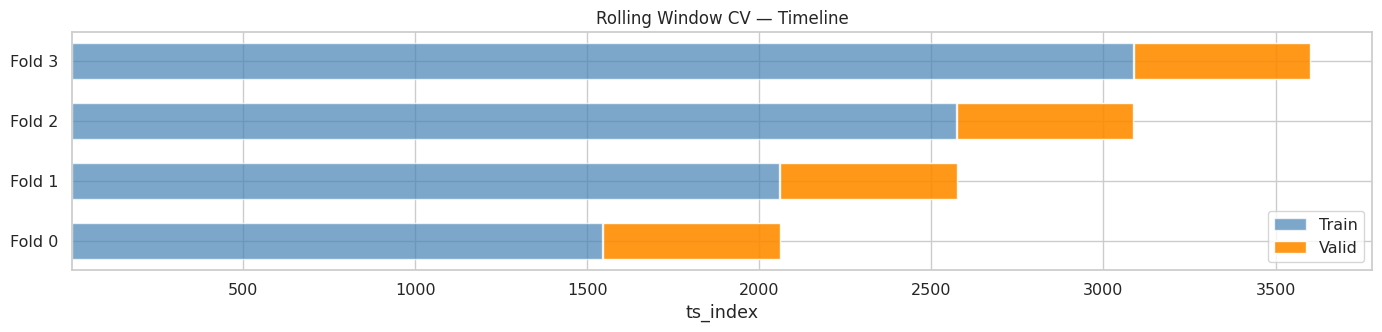


  💡 Khuyến nghị: Sử dụng Rolling Window CV với gap ≥ max(horizon)


In [22]:
# =============================================================
# 13. TIME SERIES CROSS-VALIDATION STRATEGY
# =============================================================

def rolling_cv_splits(unique_times, n_splits=4, val_size=None, gap=2):
    """
    Tạo các fold CV theo kiểu rolling / expanding window.
    gap: số time steps bỏ qua giữa train và valid để tránh leakage.
    """
    times = np.array(sorted(unique_times))
    T = len(times)
    if val_size is None:
        val_size = max(1, T // (n_splits + 3))
    splits = []
    for i in range(n_splits):
        val_end   = T - (n_splits - i - 1) * val_size
        val_start = max(val_size, val_end - val_size)
        train_end = max(0, val_start - gap)
        tr_times  = times[:train_end]
        va_times  = times[val_start:val_end]
        if len(tr_times) == 0 or len(va_times) == 0:
            continue
        splits.append((tr_times, va_times))
    return splits

unique_times = np.sort(train[TIME_COL].unique())
splits = rolling_cv_splits(unique_times, n_splits=4, gap=2)

cv_rows = []
for i, (tr_times, va_times) in enumerate(splits):
    tr_mask = train[TIME_COL].isin(tr_times)
    va_mask = train[TIME_COL].isin(va_times)
    cv_rows.append({
        'fold'                        : i,
        'train_t_min'                 : int(tr_times.min()),
        'train_t_max'                 : int(tr_times.max()),
        'valid_t_min'                 : int(va_times.min()),
        'valid_t_max'                 : int(va_times.max()),
        'n_train_rows'                : int(tr_mask.sum()),
        'n_valid_rows'                : int(va_mask.sum()),
        'n_train_groups'              : int(train.loc[tr_mask, '__gid__'].nunique()),
        'n_valid_groups'              : int(train.loc[va_mask, '__gid__'].nunique()),
        'pct_valid_groups_in_train_%' : round(
            100 * train.loc[va_mask, '__gid__'].isin(set(train.loc[tr_mask, '__gid__'])).mean(), 2
        )
    })

cv_df = pd.DataFrame(cv_rows)
print('── CV Splits (Rolling Window, gap=2) ──')
display(cv_df)

# ── Visualize CV timeline ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 3.5))

for i, (tr_times, va_times) in enumerate(splits):
    ax.barh(i, tr_times.max() - tr_times.min(), left=tr_times.min(),
            color='steelblue', alpha=0.7, height=0.6, label='Train' if i == 0 else '')
    ax.barh(i, va_times.max() - va_times.min(), left=va_times.min(),
            color='darkorange', alpha=0.9, height=0.6, label='Valid' if i == 0 else '')

ax.set_yticks(range(len(splits)))
ax.set_yticklabels([f'Fold {i}' for i in range(len(splits))])
ax.set_xlabel('ts_index')
ax.set_title('Rolling Window CV — Timeline', fontsize=12)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print('\n  💡 Khuyến nghị: Sử dụng Rolling Window CV với gap ≥ max(horizon)')

---
<a id='14'></a>
## 14. Tổng Hợp & Khuyến Nghị Feature Engineering

In [23]:
# =============================================================
# 14. TỔNG HỢP EDA & KHUYẾN NGHỊ
# =============================================================

# ── Feature Recommendation Table ─────────────────────────────
rec = [
    # MUST
    ('MUST',         'Group identifiers',   'code, sub_code, sub_category, horizon — mã hóa categorical'),
    ('MUST',         'Time index raw',      'ts_index + relative position (obs_idx_in_group, time_since_start)'),
    ('MUST',         'Safe Lag features',   'lag_1, lag_2, lag_3, lag_5, lag_7, lag_14, lag_28 (shift trong group)'),
    ('MUST',         'Safe Rolling stats',  'rolling mean/std/min/max sau khi shift(1) — tránh leakage'),
    ('MUST',         'Series lifecycle',    'obs_idx_in_group, warmup indicator, group series length so far'),
    # STRONG
    ('STRONG',       'Top raw features',    f'Top 10 features theo |corr(target)|: {corr_df.dropna().head(10)["feature"].tolist()}'),
    ('STRONG',       'Seasonality phase',   f'Best phase features: {phase_stats_df.head(3)["period"].tolist()} (mod N)'),
    ('STRONG',       'Momentum features',   'lag_1 - lag_7, lag_1 / rolling_mean_7, velocity'),
    ('STRONG',       'Volatility regime',   'rolling_std_28 / rolling_mean_28 (coefficient of variation)'),
    ('STRONG',       'Horizon interaction', 'horizon × lag_1, horizon × rolling_mean_7'),
    # CONDITIONAL
    ('CONDITIONAL',  'Normalized context',  'lag_1 / rolling_std hay (lag_1 - rolling_mean) / rolling_std'),
    ('CONDITIONAL',  'Cross-sectional',     'rank pct của feature theo ts_index (market rank features)'),
    ('CONDITIONAL',  'Time encoding',       'sin/cos encoding nếu tìm thấy chu kỳ rõ'),
    # AVOID
    ('AVOID',        'Future-derived',      'shift(-k), centered rolling, normalization dùng toàn bộ dữ liệu'),
    ('AVOID',        'Random CV tuned',     'Feature chỉ tốt dưới random split nhưng sẽ collapse với time split'),
    ('AVOID',        'Weight column',       'WEIGHT_COL không được dùng làm feature — chỉ dùng trong loss'),
]

rec_df = pd.DataFrame(rec, columns=['priority', 'feature_family', 'detail'])

print('── Feature Engineering Roadmap ──')
display(rec_df.style.apply(
    lambda col: [
        'background-color: #c8f7c5' if v == 'MUST' else
        'background-color: #d4e6f1' if v == 'STRONG' else
        'background-color: #fef9e7' if v == 'CONDITIONAL' else
        'background-color: #fadbd8' for v in col
    ], subset=['priority']
))

── Feature Engineering Roadmap ──


,priority,feature_family,detail
0,MUST,Group identifiers,"code, sub_code, sub_category, horizon — mã hóa categorical"
1,MUST,Time index raw,"ts_index + relative position (obs_idx_in_group, time_since_start)"
2,MUST,Safe Lag features,"lag_1, lag_2, lag_3, lag_5, lag_7, lag_14, lag_28 (shift trong group)"
3,MUST,Safe Rolling stats,rolling mean/std/min/max sau khi shift(1) — tránh leakage
4,MUST,Series lifecycle,"obs_idx_in_group, warmup indicator, group series length so far"
5,STRONG,Top raw features,"Top 10 features theo |corr(target)|: ['feature_bz', 'feature_cd', 'feature_af', 'feature_u', 'feature_bo', 'feature_bm', 'feature_s', 'feature_t', 'feature_am', 'feature_o']"
6,STRONG,Seasonality phase,"Best phase features: [20, 52, 30] (mod N)"
7,STRONG,Momentum features,"lag_1 - lag_7, lag_1 / rolling_mean_7, velocity"
8,STRONG,Volatility regime,rolling_std_28 / rolling_mean_28 (coefficient of variation)
9,STRONG,Horizon interaction,"horizon × lag_1, horizon × rolling_mean_7"


In [24]:
# ── Summary Markdown ──────────────────────────────────────────
top5_lag_roll = lr_corr_df.dropna().head(5)['feature'].tolist()
top3_phase    = phase_stats_df.head(3)['period'].tolist()
top5_raw      = corr_df.dropna().head(5)['feature'].tolist()

summary = f"""
## 📋 Kết Luận EDA — Time Series Forecasting

### Dataset
- **Train**: `{len(train):,}` dòng × `{train.shape[1]}` cột  |  **Test**: `{len(test):,}` dòng × `{test.shape[1]}` cột
- **Target**: `{TARGET_COL}` — phân phối có thể lệch (kiểm tra skewness khi chọn loss function)
- **Số nhóm train**: `{n_train_groups:,}`  |  **Nhóm mới trong test**: `{len(new_groups):,}`
- **86 features ẩn danh** — không có missing hoặc ít missing (kiểm tra bước 4)

### Cấu trúc thời gian
- Train: `ts_index` = `{int(train[TIME_COL].min())}` → `{int(train[TIME_COL].max())}`
- Test : `ts_index` = `{int(test[TIME_COL].min())}` → `{int(test[TIME_COL].max())}`
- Bước thời gian đều đặn trong phần lớn các nhóm

### Insights quan trọng
- **Top raw features (|corr|)**: {', '.join(top5_raw)}
- **Top lag/rolling features**: {', '.join(top5_lag_roll)}
- **Chu kỳ tiềm năng**: period = {top3_phase}
- **4 horizons** (1, 3, 10, 25) có phân phối target khác nhau → nên train riêng hoặc thêm horizon interaction

### Chiến lược mô hình
- ✅ **CV**: Rolling window (expanding train), gap ≥ 2
- ✅ **Model đề xuất**: LightGBM / CatBoost với lag+rolling features leakage-safe
- ✅ **Calibration**: Weighted linear calibration trên valid set theo từng horizon
- ⚠️ **Rủi ro chính**: Drift train→test + overfitting public leaderboard (chỉ 25% test)
- ⚠️ **Không dùng**: weight làm feature, future-derived features, random CV
"""

display(Markdown(summary))


## 📋 Kết Luận EDA — Time Series Forecasting

### Dataset
- **Train**: `5,337,414` dòng × `95` cột  |  **Test**: `1,447,107` dòng × `93` cột
- **Target**: `y_target` — phân phối có thể lệch (kiểm tra skewness khi chọn loss function)
- **Số nhóm train**: `36,923`  |  **Nhóm mới trong test**: `9,164`
- **86 features ẩn danh** — không có missing hoặc ít missing (kiểm tra bước 4)

### Cấu trúc thời gian
- Train: `ts_index` = `1` → `3601`
- Test : `ts_index` = `3602` → `4376`
- Bước thời gian đều đặn trong phần lớn các nhóm

### Insights quan trọng
- **Top raw features (|corr|)**: feature_bz, feature_cd, feature_af, feature_u, feature_bo
- **Top lag/rolling features**: lag_1, roll_mean_3, roll_mean_7, roll_mean_14, lag_2
- **Chu kỳ tiềm năng**: period = [20, 52, 30]
- **4 horizons** (1, 3, 10, 25) có phân phối target khác nhau → nên train riêng hoặc thêm horizon interaction

### Chiến lược mô hình
- ✅ **CV**: Rolling window (expanding train), gap ≥ 2
- ✅ **Model đề xuất**: LightGBM / CatBoost với lag+rolling features leakage-safe
- ✅ **Calibration**: Weighted linear calibration trên valid set theo từng horizon
- ⚠️ **Rủi ro chính**: Drift train→test + overfitting public leaderboard (chỉ 25% test)
- ⚠️ **Không dùng**: weight làm feature, future-derived features, random CV


In [25]:
# Cleanup EDA objects không cần thiết
for _obj in ['eda_sub', 'fd_merge', 'future_diag', 'phase_df',
             'corr_sample', 'fd_sample', 'tmp', 'global_time']:
    if _obj in dir():
        try: del globals()[_obj]
        except: pass
gc.collect()
print('✅ EDA hoàn tất. Tiếp tục phần Feature Engineering...')


✅ EDA hoàn tất. Tiếp tục phần Feature Engineering...


---
<a id='fe'></a>
# 🔧 PHẦN 2: Feature Engineering


In [26]:
# ============================================================
# UTILITY FUNCTIONS
# ============================================================

def memory_mb(df: pd.DataFrame) -> float:
    """Tính bộ nhớ sử dụng (MB)."""
    return df.memory_usage(deep=True).sum() / 1024**2


def reduce_mem_usage(df: pd.DataFrame, verbose: bool = True) -> pd.DataFrame:
    """
    Ép kiểu dữ liệu về dtype nhỏ nhất có thể mà không làm mất dữ liệu.
    float64 → float32, int64 → int32/int16/int8 tuỳ range.
    """
    start_mem = memory_mb(df)
    for col in df.columns:
        col_type = df[col].dtype

        if col_type == object:
            df[col] = df[col].astype('category')

        elif col_type.kind == 'f':          # float
            df[col] = df[col].astype(np.float32)

        elif col_type.kind in ('i', 'u'):   # int / uint
            c_min, c_max = df[col].min(), df[col].max()
            if c_min >= np.iinfo(np.int8).min and c_max <= np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min >= np.iinfo(np.int16).min and c_max <= np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min >= np.iinfo(np.int32).min and c_max <= np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)

    end_mem = memory_mb(df)
    if verbose:
        print(f'  RAM: {start_mem:.1f} MB → {end_mem:.1f} MB '
              f'(giảm {100*(start_mem-end_mem)/start_mem:.1f}%)')
    return df


def safe_div(a: pd.Series, b: pd.Series, fill: float = 0.0) -> pd.Series:
    """Chia an toàn, tránh inf/nan khi mẫu = 0."""
    return np.where(b.abs() > 1e-9, a / b, fill).astype(np.float32)


def log1p_signed(s: pd.Series) -> pd.Series:
    """log1p cho cả giá trị âm: sign(x) * log1p(|x|)."""
    return (np.sign(s) * np.log1p(np.abs(s))).astype(np.float32)


def check_leakage(df: pd.DataFrame, group_cols: List[str],
                  time_col: str, target_col: str,
                  feat_cols: List[str]) -> pd.DataFrame:
    """
    Kiểm tra data leakage: mỗi feature không được có corr với
    future_target cao bất thường.
    Trả về DataFrame report.
    """
    sample = df.sort_values(group_cols + [time_col]).copy()
    sample['_future_1'] = sample.groupby(group_cols)[target_col].shift(-1)
    sample = sample.dropna(subset=[target_col, '_future_1'])
    sample = sample.sample(min(80_000, len(sample)), random_state=RANDOM_SEED)

    rows = []
    for c in feat_cols:
        if c not in sample.columns:
            continue
        x = pd.to_numeric(sample[c], errors='coerce')
        r_curr   = x.corr(sample[target_col])
        r_future = x.corr(sample['_future_1'])
        rows.append({
            'feature'          : c,
            'corr_current_y'   : round(r_curr, 4)   if pd.notna(r_curr)   else np.nan,
            'corr_future_y+1'  : round(r_future, 4) if pd.notna(r_future) else np.nan,
            'suspicious'       : abs(r_future) > abs(r_curr) * 1.05 if (pd.notna(r_curr) and pd.notna(r_future)) else False,
        })
    return pd.DataFrame(rows).sort_values('corr_future_y+1', ascending=False, key=abs)


print('✅ Utility functions defined.')

✅ Utility functions defined.


In [27]:
# ── Data đã được load trong phần EDA ────────────────────────
# train, test đã có sẵn từ phần EDA
# Xác định feature columns (86 features ẩn danh)
NON_FEATURE_COLS = set([ID_COL, TIME_COL, TARGET_COL, WEIGHT_COL] + GROUP_COLS)
RAW_FEATURE_COLS = [c for c in train.columns if c not in NON_FEATURE_COLS]

# Đổi tên để FE pipeline dùng (train_raw / test_raw)
train_raw = train.copy()
test_raw  = test.copy()

print(f'  train_raw: {train_raw.shape} | RAM: {memory_mb(train_raw):.1f} MB')
print(f'  test_raw : {test_raw.shape}  | RAM: {memory_mb(test_raw):.1f} MB')
print(f'  # raw features: {len(RAW_FEATURE_COLS)}')

# Giảm RAM
train_raw = reduce_mem_usage(train_raw, verbose=False)
test_raw  = reduce_mem_usage(test_raw,  verbose=False)
print('  reduce_mem_usage: ✅')


  train_raw: (5337414, 95) | RAM: 5322.9 MB
  test_raw : (1447107, 93)  | RAM: 1421.4 MB
  # raw features: 87
  reduce_mem_usage: ✅


---
<a id='3'></a>
## 3. Frequency Encoding (không leakage)

**Ý tưởng**: Mã hoá số lần xuất hiện của mỗi giá trị categorical trong **tập train** rồi map vào cả train và test.  
**Tại sao không leakage?** Frequency được tính hoàn toàn từ train, không dùng bất kỳ thông tin nào từ test hay từ target.

In [28]:
# ============================================================
# 3. FREQUENCY ENCODING
# ============================================================

class FrequencyEncoder:
    """
    Tính tần suất xuất hiện của mỗi giá trị trong cột.
    Fit chỉ trên train, transform cho cả train và test.
    RAM-efficient: lưu dict thay vì DataFrame.
    """
    def __init__(self, cols: List[str], log_scale: bool = True):
        self.cols      = cols
        self.log_scale = log_scale
        self.maps_: Dict[str, dict] = {}

    def fit(self, df: pd.DataFrame) -> 'FrequencyEncoder':
        for c in self.cols:
            freq = df[c].value_counts(dropna=False)
            self.maps_[c] = freq.to_dict()
        return self

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        df = df.copy()
        for c in self.cols:
            col_name = f'{c}_freq'
            # Convert về object trước khi map để tránh lỗi với dtype 'category'
            # (reduce_mem_usage() có thể đã ép cột sang category)
            src = df[c].astype(object)
            mapped = src.map(self.maps_[c])          # NaN nếu key không tồn tại
            df[col_name] = mapped.fillna(1).astype(np.float32)
            if self.log_scale:
                df[f'{c}_log_freq'] = np.log1p(df[col_name]).astype(np.float32)
        return df

    def fit_transform(self, df: pd.DataFrame) -> pd.DataFrame:
        return self.fit(df).transform(df)


# ── Áp dụng ───────────────────────────────────────────────────
# Chỉ fit trên TRAIN để tránh leakage
FREQ_COLS = ['code', 'sub_code', 'sub_category']  # không encode horizon vì đã là số

freq_enc = FrequencyEncoder(cols=FREQ_COLS, log_scale=True)
freq_enc.fit(train_raw)  # fit CHỈ trên train

# Danh sách features tạo ra
FREQ_FEATURES = [f'{c}_freq'     for c in FREQ_COLS] + \
                [f'{c}_log_freq' for c in FREQ_COLS]

print('✅ FrequencyEncoder fitted trên train.')
print(f'   Features tạo ra: {FREQ_FEATURES}')

# Kiểm tra phân phối
tmp = freq_enc.transform(train_raw.head(100_000))
print('\nPhân phối sub_code_freq (sample):')
print(tmp['sub_code_freq'].describe())

✅ FrequencyEncoder fitted trên train.
   Features tạo ra: ['code_freq', 'sub_code_freq', 'sub_category_freq', 'code_log_freq', 'sub_code_log_freq', 'sub_category_log_freq']

Phân phối sub_code_freq (sample):
count   100000.00000
mean     36476.58594
std      15982.14062
min        140.00000
25%      18914.00000
50%      38694.00000
75%      50594.00000
max      64163.00000
Name: sub_code_freq, dtype: float64


---
<a id='4'></a>
## 4. Lag Features (causal, trong nhóm)

**Nguyên tắc an toàn**:  
- Luôn `groupby(GROUP_COLS).shift(lag)` — shift **trong từng nhóm**, không shift global  
- `lag_k` tại `ts_index=t` = giá trị target tại `ts_index = t-k` của **cùng nhóm**  
- Không bao giờ dùng `shift(-k)` (future leakage)

In [29]:
# ============================================================
# 4. LAG FEATURES
# ============================================================

def add_lag_features(
    df: pd.DataFrame,
    group_cols: List[str],
    time_col: str,
    target_col: str,
    lags: List[int] = LAG_WINDOWS,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Tạo lag features của target theo từng nhóm.

    Parameters
    ----------
    df         : DataFrame đã sắp xếp theo group + time
    group_cols : các cột định nghĩa nhóm
    time_col   : cột thời gian
    target_col : cột target
    lags       : danh sách bước lag

    Returns
    -------
    df_new     : DataFrame với lag features thêm vào
    feat_names : tên các features mới

    Leakage-safe: shift(lag) đảm bảo lag_k tại t chỉ dùng thông tin t-k.
    """
    # Bắt buộc sort trước khi shift
    df = df.sort_values(group_cols + [time_col]).copy()

    grouped = df.groupby(group_cols, sort=False)[target_col]
    feat_names = []

    for lag in lags:
        col_name = f'lag_{lag}'
        # shift(lag) trong nhóm → giá trị tại t = y(t - lag)
        df[col_name] = grouped.shift(lag).astype(FLOAT_DTYPE)
        feat_names.append(col_name)

    return df, feat_names


---
<a id='5'></a>
## 5. Rolling Statistics (shift-first)

**Pattern bắt buộc**:  
```
rolling_mean_w tại t = mean(y[t-w], ..., y[t-1])
```
Thực hiện bằng: `shift(1).rolling(w).mean()` — **shift trước, rolling sau**.

**Tuyệt đối KHÔNG dùng**: `rolling(w).mean()` không shift → sẽ bao gồm `y[t]` (leakage!).

In [30]:
# ============================================================
# 5. ROLLING STATISTICS
# ============================================================

def add_rolling_features(
    df: pd.DataFrame,
    group_cols: List[str],
    time_col: str,
    target_col: str,
    windows: List[int] = ROLL_WINDOWS,
    stats: List[str] = ['mean', 'std', 'min', 'max'],
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Tạo rolling features của target theo từng nhóm.
    Dùng pattern shift(1) trước rolling để đảm bảo causal.

    stats hỗ trợ: 'mean', 'std', 'min', 'max', 'median', 'skew'
    """
    df = df.sort_values(group_cols + [time_col]).copy()

    # Tính shifted series 1 lần, tái sử dụng cho tất cả windows
    # (tiết kiệm CPU so với tính lại nhiều lần)
    grouped_target = df.groupby(group_cols, sort=False)[target_col]
    # Series đã shift — đây là chuỗi y[t-1], y[t-2], ... nhìn từ mỗi điểm t
    shifted = grouped_target.shift(1)

    feat_names = []

    for w in windows:
        min_p = max(2, w // 2)  # min_periods linh hoạt, giảm NaN cho chuỗi ngắn
        # Group shifted series để roll trong từng nhóm
        shifted_grp = shifted.groupby(df[group_cols].apply(tuple, axis=1), sort=False)

        # ── Dùng transform trực tiếp thay vì groupby lồng (RAM hiệu quả hơn) ──
        def _roll_stat(s, func_name, w=w, min_p=min_p):
            r = s.rolling(w, min_periods=min_p)
            if func_name == 'mean'  : return r.mean()
            if func_name == 'std'   : return r.std()
            if func_name == 'min'   : return r.min()
            if func_name == 'max'   : return r.max()
            if func_name == 'median': return r.median()
            if func_name == 'skew'  : return r.skew()

        for stat in stats:
            col_name = f'roll_{stat}_{w}'
            # Transform: shift(1) → rolling → stat (trong từng nhóm)
            df[col_name] = grouped_target.transform(
                lambda s, stat=stat, w=w, min_p=min_p:
                    _roll_stat(s.shift(1), stat, w, min_p)
            ).astype(FLOAT_DTYPE)
            feat_names.append(col_name)

    return df, feat_names


---
<a id='6'></a>
## 6. Momentum & Volatility Features

Các features đo **tốc độ thay đổi** và **mức độ biến động** của chuỗi.  
Tất cả đều được xây dựng từ lag/rolling đã tính, không tạo thêm shift mới.

In [31]:
# ============================================================
# 6. MOMENTUM & VOLATILITY FEATURES
# ============================================================

def add_momentum_features(
    df: pd.DataFrame,
    group_cols: List[str],
    time_col: str,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Tạo các features đo momentum và volatility từ lag/rolling đã có.
    Giả sử df đã có: lag_1, lag_2, lag_3, lag_7, lag_14,
                      roll_mean_3, roll_mean_7, roll_mean_14, roll_mean_28,
                      roll_std_7, roll_std_14, roll_std_28
    """
    df = df.copy()
    feat_names = []

    # ── 6.1 Momentum: tốc độ thay đổi giữa 2 thời điểm ──────
    pairs = [(1, 2), (1, 3), (1, 7), (1, 14), (2, 7), (3, 14), (7, 28)]
    for a, b in pairs:
        ca, cb = f'lag_{a}', f'lag_{b}'
        if ca in df.columns and cb in df.columns:
            name = f'mom_{a}_{b}'
            df[name] = (df[ca] - df[cb]).astype(FLOAT_DTYPE)
            feat_names.append(name)

    # ── 6.2 Relative momentum (tỷ lệ thay đổi, tránh chia 0) ─
    for a, b in [(1, 7), (1, 14), (7, 28)]:
        ca, cb = f'lag_{a}', f'lag_{b}'
        if ca in df.columns and cb in df.columns:
            name = f'rel_mom_{a}_{b}'
            df[name] = safe_div(df[ca] - df[cb], df[cb].abs() + 1e-8)
            feat_names.append(name)

    # ── 6.3 Deviation from rolling mean (lag_1 vs rolling) ───
    for w in [3, 7, 14, 28]:
        rc = f'roll_mean_{w}'
        if 'lag_1' in df.columns and rc in df.columns:
            name = f'dev_from_roll_{w}'
            df[name] = (df['lag_1'] - df[rc]).astype(FLOAT_DTYPE)
            feat_names.append(name)

    # ── 6.4 Normalised deviation (z-score của lag_1 trong cửa sổ) ─
    for w in [7, 14, 28]:
        rm, rs = f'roll_mean_{w}', f'roll_std_{w}'
        if all(c in df.columns for c in ['lag_1', rm, rs]):
            name = f'zscore_{w}'
            df[name] = safe_div(df['lag_1'] - df[rm], df[rs] + 1e-8)
            feat_names.append(name)

    # ── 6.5 Coefficient of variation (CV = std / |mean|) ─────
    for w in [7, 14, 28]:
        rm, rs = f'roll_mean_{w}', f'roll_std_{w}'
        if all(c in df.columns for c in [rm, rs]):
            name = f'cv_{w}'
            df[name] = safe_div(df[rs], df[rm].abs() + 1e-8)
            feat_names.append(name)

    # ── 6.6 Short vs long rolling mean ratio ─────────────────
    short_long_pairs = [(3, 14), (3, 28), (7, 28)]
    for s, l in short_long_pairs:
        rs_col, rl_col = f'roll_mean_{s}', f'roll_mean_{l}'
        if rs_col in df.columns and rl_col in df.columns:
            name = f'ratio_roll_{s}_{l}'
            df[name] = safe_div(df[rs_col], df[rl_col].abs() + 1e-8)
            feat_names.append(name)

    # ── 6.7 Range (max - min) trong cửa sổ ───────────────────
    for w in [7, 14, 28]:
        rmax, rmin = f'roll_max_{w}', f'roll_min_{w}'
        if rmax in df.columns and rmin in df.columns:
            name = f'roll_range_{w}'
            df[name] = (df[rmax] - df[rmin]).astype(FLOAT_DTYPE)
            feat_names.append(name)

    return df, feat_names


print('✅ add_momentum_features() defined.')
print('  Momentum features sẽ bao gồm:')
for desc in [
    'mom_a_b      : lag_a - lag_b (tốc độ thay đổi tuyệt đối)',
    'rel_mom_a_b  : (lag_a - lag_b) / |lag_b| (tỷ lệ thay đổi)',
    'dev_from_roll_w : lag_1 - roll_mean_w (độ lệch so với trung bình)',
    'zscore_w     : (lag_1 - roll_mean_w) / roll_std_w (z-score)',
    'cv_w         : roll_std_w / roll_mean_w (hệ số biến thiên)',
    'ratio_roll_s_l: roll_mean_s / roll_mean_l (golden cross)',
    'roll_range_w : roll_max_w - roll_min_w (biên độ dao động)',
]:
    print(f'    {desc}')

✅ add_momentum_features() defined.
  Momentum features sẽ bao gồm:
    mom_a_b      : lag_a - lag_b (tốc độ thay đổi tuyệt đối)
    rel_mom_a_b  : (lag_a - lag_b) / |lag_b| (tỷ lệ thay đổi)
    dev_from_roll_w : lag_1 - roll_mean_w (độ lệch so với trung bình)
    zscore_w     : (lag_1 - roll_mean_w) / roll_std_w (z-score)
    cv_w         : roll_std_w / roll_mean_w (hệ số biến thiên)
    ratio_roll_s_l: roll_mean_s / roll_mean_l (golden cross)
    roll_range_w : roll_max_w - roll_min_w (biên độ dao động)


---
<a id='7'></a>
## 7. Time Phase / Seasonality Features

Mã hoá chu kỳ thời gian bằng **modulo** và **sin/cos encoding**.  
Chọn period từ kết quả EDA (phase_stats).

In [32]:
# ============================================================
# 7. TIME PHASE / SEASONALITY FEATURES
# ============================================================

def add_time_features(
    df: pd.DataFrame,
    time_col: str,
    periods: List[int] = PHASE_PERIODS,
    sincos: bool = True,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Tạo features từ ts_index:
    - Modulo features: ts_index % period → nắm bắt chu kỳ thô
    - Sin/cos features: mã hoá chu kỳ liên tục, tránh discontinuity

    Sin/cos encoding quan trọng vì:
      mod_7 = 0 và mod_7 = 6 thực ra kế tiếp nhau,
      nhưng model tree không biết điều này nếu chỉ dùng raw modulo.
    """
    df = df.copy()
    feat_names = []
    t = df[time_col]

    for p in periods:
        # ── Raw modulo ──────────────────────────────────────────
        name_mod = f't_mod_{p}'
        df[name_mod] = (t % p).astype(np.int16)
        feat_names.append(name_mod)

        # ── Sin/cos encoding ────────────────────────────────────
        if sincos:
            angle = 2 * np.pi * t / p
            df[f't_sin_{p}'] = np.sin(angle).astype(FLOAT_DTYPE)
            df[f't_cos_{p}'] = np.cos(angle).astype(FLOAT_DTYPE)
            feat_names += [f't_sin_{p}', f't_cos_{p}']

    # ── Global rank (vị trí tương đối trong toàn bộ timeline) ──
    # Đây là monotone feature, an toàn với mọi loại model
    uniq_t = np.sort(df[time_col].unique())
    rank_map = {t: i for i, t in enumerate(uniq_t)}
    df['t_global_rank'] = df[time_col].map(rank_map).astype(np.int32)
    feat_names.append('t_global_rank')

    return df, feat_names


print('✅ add_time_features() defined.')
print('  Time features bao gồm:')
print('    t_mod_P      : ts_index % P (raw periodic encoding)')
print('    t_sin_P      : sin(2π × ts_index / P)')
print('    t_cos_P      : cos(2π × ts_index / P)')
print('    t_global_rank: rank vị trí trong timeline (monotone)')


✅ add_time_features() defined.
  Time features bao gồm:
    t_mod_P      : ts_index % P (raw periodic encoding)
    t_sin_P      : sin(2π × ts_index / P)
    t_cos_P      : cos(2π × ts_index / P)
    t_global_rank: rank vị trí trong timeline (monotone)


---
<a id='8'></a>
## 8. Group Lifecycle Features

Các features mô tả **trạng thái hiện tại của nhóm** trong chuỗi thời gian: đã quan sát bao nhiêu điểm, nhóm đang ở giai đoạn nào, v.v.

In [33]:
# ============================================================
# 8. GROUP LIFECYCLE FEATURES
# ============================================================

def add_lifecycle_features(
    df: pd.DataFrame,
    group_cols: List[str],
    time_col: str,
    warmup_threshold: int = 5,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Tạo features mô tả vòng đời của nhóm tại mỗi thời điểm.

    Tất cả đều dựa trên cumcount/cummin/cummax → causal (chỉ dùng quá khứ).
    """
    df = df.sort_values(group_cols + [time_col]).copy()
    feat_names = []

    # ── 8.1 Số quan sát đã thấy trong nhóm (0-indexed) ────────
    df['obs_count']  = df.groupby(group_cols, sort=False).cumcount()  # 0, 1, 2, ...
    df['obs_count']  = df['obs_count'].astype(np.int32)
    feat_names.append('obs_count')

    # ── 8.2 Warmup indicator: nhóm còn "lạnh" (ít dữ liệu lịch sử) ─
    df['is_warmup']  = (df['obs_count'] < warmup_threshold).astype(np.int8)
    feat_names.append('is_warmup')

    # ── 8.3 Thời gian kể từ khi nhóm bắt đầu ──────────────────
    first_t = df.groupby(group_cols, sort=False)[time_col].transform('min')
    df['age_in_group'] = (df[time_col] - first_t).astype(np.int32)
    feat_names.append('age_in_group')

    # ── 8.4 Khoảng cách thời gian từ quan sát trước ────────────
    df['time_since_prev'] = df.groupby(group_cols, sort=False)[time_col].diff().fillna(0).astype(np.float32)
    feat_names.append('time_since_prev')

    # ── 8.5 Cumulative min/max target (biết từ quá khứ) ────────
    grouped_target = df.groupby(group_cols, sort=False)['lag_1'] \
        if 'lag_1' in df.columns \
        else None

    # Dùng expanding trên lag_1 (đã an toàn vì lag_1 = y[t-1])
    if 'lag_1' in df.columns:
        df['expanding_mean'] = (
            df.groupby(group_cols, sort=False)['lag_1']
              .transform(lambda s: s.expanding().mean())
              .astype(FLOAT_DTYPE)
        )
        df['expanding_std'] = (
            df.groupby(group_cols, sort=False)['lag_1']
              .transform(lambda s: s.expanding().std())
              .astype(FLOAT_DTYPE)
        )
        feat_names += ['expanding_mean', 'expanding_std']

    return df, feat_names


print('✅ add_lifecycle_features() defined.')
print('  Lifecycle features:')
print('    obs_count      : số quan sát đã thấy trong nhóm (cumcount)')
print('    is_warmup      : = 1 nếu obs_count < threshold (chuỗi còn ngắn)')
print('    age_in_group   : ts_index - ts_index đầu tiên của nhóm')
print('    time_since_prev: khoảng cách từ quan sát trước (phát hiện gaps)')
print('    expanding_mean : expanding mean của lag_1 (lịch sử toàn bộ nhóm)')
print('    expanding_std  : expanding std của lag_1')

✅ add_lifecycle_features() defined.
  Lifecycle features:
    obs_count      : số quan sát đã thấy trong nhóm (cumcount)
    is_warmup      : = 1 nếu obs_count < threshold (chuỗi còn ngắn)
    age_in_group   : ts_index - ts_index đầu tiên của nhóm
    time_since_prev: khoảng cách từ quan sát trước (phát hiện gaps)
    expanding_mean : expanding mean của lag_1 (lịch sử toàn bộ nhóm)
    expanding_std  : expanding std của lag_1


---
<a id='9'></a>
## 9. Horizon Interaction Features

**Lý do**: Horizon 1 (short-term) và Horizon 25 (extra long-term) có phân phối target rất khác nhau (thấy từ EDA). Tạo interaction giúp model học được sự khác biệt này.

In [34]:
# ============================================================
# 9. HORIZON INTERACTION FEATURES
# ============================================================

def add_horizon_interactions(
    df: pd.DataFrame,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Tạo interaction features giữa horizon và các lag/rolling features.
    Model tree có thể tự học interaction nhưng explicit interaction
    giúp tăng tốc độ hội tụ và giảm số lượng cây cần thiết.
    """
    df = df.copy()
    feat_names = []

    if 'horizon' not in df.columns:
        return df, feat_names

    h = df['horizon'].astype(FLOAT_DTYPE)

    # ── 9.1 horizon × lag features ────────────────────────────
    for lag_col in ['lag_1', 'lag_3', 'lag_7']:
        if lag_col in df.columns:
            name = f'h_x_{lag_col}'
            df[name] = (h * df[lag_col]).astype(FLOAT_DTYPE)
            feat_names.append(name)

    # ── 9.2 horizon × rolling mean ────────────────────────────
    for roll_col in ['roll_mean_7', 'roll_mean_14', 'roll_mean_28']:
        if roll_col in df.columns:
            name = f'h_x_{roll_col}'
            df[name] = (h * df[roll_col]).astype(FLOAT_DTYPE)
            feat_names.append(name)

    # ── 9.3 horizon × volatility ──────────────────────────────
    for vol_col in ['roll_std_7', 'roll_std_28', 'cv_7', 'cv_28']:
        if vol_col in df.columns:
            name = f'h_x_{vol_col}'
            df[name] = (h * df[vol_col]).astype(FLOAT_DTYPE)
            feat_names.append(name)

    # ── 9.4 log(horizon) — horizon không tuyến tính với target ─
    df['log_horizon'] = np.log1p(h).astype(FLOAT_DTYPE)
    feat_names.append('log_horizon')

    # ── 9.5 horizon category (one-hot style, dùng int) ─────────
    # Giữ horizon gốc làm categorical, thêm binary flag mỗi horizon
    for h_val in HORIZONS:
        name = f'is_h{h_val}'
        df[name] = (df['horizon'] == h_val).astype(np.int8)
        feat_names.append(name)

    return df, feat_names


print('✅ add_horizon_interactions() defined.')
print('  Horizon interaction features:')
print('    h_x_lag_k     : horizon × lag_k (khác nhau theo tầm nhìn)')
print('    h_x_roll_w    : horizon × rolling_mean_w')
print('    h_x_vol       : horizon × volatility measure')
print('    log_horizon   : log(1 + horizon) (phi tuyến hoá horizon)')
print('    is_h{H}       : binary flag cho từng horizon value')

✅ add_horizon_interactions() defined.
  Horizon interaction features:
    h_x_lag_k     : horizon × lag_k (khác nhau theo tầm nhìn)
    h_x_roll_w    : horizon × rolling_mean_w
    h_x_vol       : horizon × volatility measure
    log_horizon   : log(1 + horizon) (phi tuyến hoá horizon)
    is_h{H}       : binary flag cho từng horizon value


---
<a id='10'></a>
## 10. Cross-sectional Rank Features (RAM-safe)

**Ý tưởng**: Tại mỗi `ts_index`, rank percentile của một entity trong toàn bộ entities cùng thời điểm.  
**RAM-safe**: Tính theo từng `ts_index` (chunk), không load toàn bộ vào memory.

In [35]:
# ============================================================
# 10. CROSS-SECTIONAL RANK FEATURES (RAM-SAFE)
# ============================================================

def add_crosssectional_rank(
    df: pd.DataFrame,
    time_col: str,
    rank_cols: List[str],
    groupby_for_rank: Optional[str] = 'horizon',
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Tính rank percentile của mỗi entity so với toàn bộ entities tại cùng ts_index.
    Rank được tính theo từng horizon (nếu groupby_for_rank='horizon').

    RAM-safe: dùng groupby.transform('rank') thay vì loop từng ts_index.
    Leakage-safe: rank dựa trên LAG features, không dùng target trực tiếp.
    """
    df = df.copy()
    feat_names = []

    rank_group = [time_col]
    if groupby_for_rank and groupby_for_rank in df.columns:
        rank_group.append(groupby_for_rank)

    for col in rank_cols:
        if col not in df.columns:
            continue
        name = f'{col}_cs_rank'
        # pct=True → rank từ 0 đến 1 (percentile)
        df[name] = (
            df.groupby(rank_group, sort=False)[col]
              .transform(lambda s: s.rank(pct=True, na_option='keep'))
              .astype(FLOAT_DTYPE)
        )
        feat_names.append(name)

    return df, feat_names


# Chỉ rank lag_1 và roll_mean_7 để tiết kiệm RAM
RANK_COLS_TO_USE = ['lag_1', 'roll_mean_7']

print('✅ add_crosssectional_rank() defined.')
print('  Cross-sectional rank features:')
print('    {col}_cs_rank: percentile rank của col trong cùng ts_index & horizon')
print(f'  Áp dụng cho: {RANK_COLS_TO_USE}')
print('  Lưu ý: rank dựa trên lag_1 (đã safe), KHÔNG rank target trực tiếp')

✅ add_crosssectional_rank() defined.
  Cross-sectional rank features:
    {col}_cs_rank: percentile rank của col trong cùng ts_index & horizon
  Áp dụng cho: ['lag_1', 'roll_mean_7']
  Lưu ý: rank dựa trên lag_1 (đã safe), KHÔNG rank target trực tiếp


---
<a id='11'></a>
## 11. Raw Feature Transformations

Biến đổi 86 raw features để giúp model học tốt hơn với các phân phối lệch.

In [36]:
# ============================================================
# 11. RAW FEATURE TRANSFORMATIONS
# ============================================================

def add_raw_feature_transforms(
    df: pd.DataFrame,
    raw_feature_cols: List[str],
    top_k_by_corr: Optional[List[str]] = None,
    add_spread: bool = True,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Biến đổi raw features:
    - Log-signed transform cho features lệch (skew)
    - Spread features (hiệu giữa 2 features liên quan)
    - Lag của top raw features (lag_1 của feature quan trọng nhất)

    RAM-efficient: chỉ transform top_k features thay vì tất cả 86.
    """
    df = df.copy()
    feat_names = []

    # Chọn top_k features để transform (giảm số lượng cột)
    cols_to_transform = top_k_by_corr if top_k_by_corr else raw_feature_cols[:20]

    # ── 11.1 Log-signed transform ──────────────────────────────
    # Giúp giảm skewness, phù hợp hơn cho gradient-based models
    for c in cols_to_transform:
        if c not in df.columns:
            continue
        s = df[c]
        skewness = float(s.skew()) if len(s.dropna()) > 10 else 0.0
        # Chỉ transform nếu |skewness| đủ lớn (> 1.5)
        if abs(skewness) > 1.5:
            name = f'{c}_log'
            df[name] = log1p_signed(s)
            feat_names.append(name)

    # ── 11.2 Spread features (hiệu giữa cặp features) ─────────
    # Ví dụ: feature_al - feature_am (nếu chúng liên quan về nghĩa)
    if add_spread and len(cols_to_transform) >= 2:
        # Tự động tạo spread cho 3 cặp đầu
        spread_pairs = [
            (cols_to_transform[0], cols_to_transform[1]),
            (cols_to_transform[0], cols_to_transform[2]) if len(cols_to_transform) > 2 else None,
        ]
        for pair in spread_pairs:
            if pair is None:
                continue
            ca, cb = pair
            if ca in df.columns and cb in df.columns:
                name = f'spread_{ca}_{cb}'
                df[name] = (df[ca] - df[cb]).astype(FLOAT_DTYPE)
                feat_names.append(name)

    # ── 11.3 Product features (tích giữa 2 features quan trọng) ─
    if len(cols_to_transform) >= 2:
        ca, cb = cols_to_transform[0], cols_to_transform[1]
        if ca in df.columns and cb in df.columns:
            name = f'product_{ca}_{cb}'
            df[name] = (df[ca] * df[cb]).astype(FLOAT_DTYPE)
            feat_names.append(name)

    return df, feat_names


print('✅ add_raw_feature_transforms() defined.')
print('  Raw feature transforms:')
print('    {col}_log   : sign(x) * log1p(|x|) cho features có |skewness| > 1.5')
print('    spread_a_b  : feature_a - feature_b')
print('    product_a_b : feature_a × feature_b')
print('  Chú ý: chỉ áp dụng cho top_k features theo |corr(target)| để tiết kiệm RAM')

✅ add_raw_feature_transforms() defined.
  Raw feature transforms:
    {col}_log   : sign(x) * log1p(|x|) cho features có |skewness| > 1.5
    spread_a_b  : feature_a - feature_b
    product_a_b : feature_a × feature_b
  Chú ý: chỉ áp dụng cho top_k features theo |corr(target)| để tiết kiệm RAM


---
<a id='12'></a>
## 12. Pipeline Tổng Hợp: `build_features()`

Đây là hàm duy nhất cần gọi trong quá trình training và inference.  
Toàn bộ logic đã được tích hợp, đảm bảo **thứ tự thực hiện đúng** và **không leakage**.

In [37]:
# ============================================================
# 12. PIPELINE TỔNG HỢP
# ============================================================
# Chiến lược RAM: xử lý TỪNG HORIZON một
# - Mỗi horizon ~1.7M dòng thay vì 6.7M → tiết kiệm 75% RAM peak
# - Sau khi build 1 horizon: lưu ra disk → giải phóng RAM → làm tiếp
# - Cuối cùng ghép lại từ disk
# ============================================================

def _build_one_horizon(
    df_h: pd.DataFrame,
    freq_encoder: 'FrequencyEncoder',
    group_cols: List[str],
    time_col: str,
    target_col: str,
    raw_feature_cols: List[str],
    top_corr_features: List[str],
    lags: List[int],
    roll_windows: List[int],
    phase_periods: List[int],
    horizon_val,
    verbose: bool,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Build features cho 1 horizon duy nhất.
    Hàm nội bộ — gọi từ build_features_by_horizon().
    Thứ tự các bước đảm bảo causal (không leakage):
      0→Sort · 1→FreqEnc · 2→Lag · 3→Roll · 4→Momentum
      5→Lifecycle · 6→Time · 7→HorizonInteract · 8→CSRank
      9→RawTransform · 10→ReduceMem
    """
    all_feat_names = []
    EXCLUDE = {ID_COL, TIME_COL, TARGET_COL, WEIGHT_COL,
               '__gid__', '_is_test', '_split'}

    # ── 0. Sort ───────────────────────────────────────────────
    df_h = df_h.sort_values(group_cols + [time_col]).reset_index(drop=True)

    # ── 1. Frequency encoding ─────────────────────────────────
    df_h = freq_encoder.transform(df_h)
    all_feat_names += [f'{c}_freq'     for c in freq_encoder.cols]
    all_feat_names += [f'{c}_log_freq' for c in freq_encoder.cols]

    # ── 2. Lag features ───────────────────────────────────────
    has_target = target_col in df_h.columns and df_h[target_col].notna().any()
    if has_target:
        df_h, lag_feats = add_lag_features(
            df_h, group_cols, time_col, target_col, lags)
        all_feat_names += lag_feats

    # ── 3. Rolling statistics ─────────────────────────────────
    if has_target:
        df_h, roll_feats = add_rolling_features(
            df_h, group_cols, time_col, target_col, roll_windows,
            stats=['mean', 'std', 'min', 'max'])
        all_feat_names += roll_feats

    # ── 4. Momentum & Volatility ──────────────────────────────
    df_h, mom_feats = add_momentum_features(df_h, group_cols, time_col)
    all_feat_names += mom_feats

    # ── 5. Group lifecycle ────────────────────────────────────
    df_h, life_feats = add_lifecycle_features(df_h, group_cols, time_col)
    all_feat_names += life_feats

    # ── 6. Time phase ─────────────────────────────────────────
    df_h, time_feats = add_time_features(df_h, time_col, phase_periods)
    all_feat_names += time_feats

    # ── 7. Horizon interactions ───────────────────────────────
    df_h, h_feats = add_horizon_interactions(df_h)
    all_feat_names += h_feats

    # ── 8. Cross-sectional rank ───────────────────────────────
    df_h, cs_feats = add_crosssectional_rank(
        df_h, time_col, RANK_COLS_TO_USE, groupby_for_rank=None)
    all_feat_names += cs_feats

    # ── 9. Raw feature transforms ─────────────────────────────
    if raw_feature_cols:
        top_k = top_corr_features if top_corr_features else raw_feature_cols[:20]
        df_h, raw_feats = add_raw_feature_transforms(
            df_h, raw_feature_cols, top_k)
        all_feat_names += raw_feats

    # Thêm raw features gốc
    all_feat_names += [c for c in (raw_feature_cols or []) if c in df_h.columns]
    if 'horizon' in df_h.columns:
        all_feat_names.append('horizon')

    # ── 10. Reduce memory ─────────────────────────────────────
    df_h = reduce_mem_usage(df_h, verbose=False)

    # Build feat_cols (dedup, loại meta)
    feat_cols = list(dict.fromkeys(
        [f for f in all_feat_names if f in df_h.columns and f not in EXCLUDE]
    ))

    if verbose:
        print(f'    horizon={horizon_val}: {df_h.shape} | '
              f'{len(feat_cols)} feats | RAM={memory_mb(df_h):.0f}MB ✅')

    return df_h, feat_cols


def build_features_by_horizon(
    df: pd.DataFrame,
    freq_encoder: 'FrequencyEncoder',
    output_dir: Path,
    horizons: List[int]         = HORIZONS,
    group_cols: List[str]       = GROUP_COLS,
    time_col: str               = TIME_COL,
    target_col: str             = TARGET_COL,
    raw_feature_cols: List[str] = None,
    top_corr_features: List[str]= None,
    lags: List[int]             = LAG_WINDOWS,
    roll_windows: List[int]     = ROLL_WINDOWS,
    phase_periods: List[int]    = PHASE_PERIODS,
    verbose: bool               = True,
) -> Tuple[List[Path], List[str]]:
    """
    Pipeline RAM-efficient: build features TỪNG HORIZON một.

    Sau mỗi horizon:
      ✅ Lưu kết quả ra disk (parquet)
      ✅ Xoá DataFrame khỏi RAM
      ✅ gc.collect() để giải phóng thực sự

    Returns
    -------
    saved_paths : danh sách đường dẫn file parquet đã lưu
    feat_cols   : danh sách feature columns (nhất quán mọi horizon)
    """
    saved_paths = []
    feat_cols_all = None
    tmp_dir = output_dir / '_horizon_chunks'
    tmp_dir.mkdir(parents=True, exist_ok=True)

    if verbose:
        print(f'Tổng input: {df.shape} | RAM: {memory_mb(df):.1f} MB')
        print(f'Xử lý {len(horizons)} horizons: {horizons}')
        print(f'Lưu chunks vào: {tmp_dir}')
        print('─' * 55)

    for h in horizons:
        # ── Slice 1 horizon ───────────────────────────────────
        df_h = df[df['horizon'] == h].copy()

        if len(df_h) == 0:
            print(f'  ⚠️  horizon={h}: không có dữ liệu, bỏ qua.')
            continue

        if verbose:
            print(f'  [horizon={h}] Input: {df_h.shape} | RAM={memory_mb(df_h):.0f}MB')

        # ── Build features cho horizon này ────────────────────
        df_h_feat, feat_cols = _build_one_horizon(
            df_h             = df_h,
            freq_encoder     = freq_encoder,
            group_cols       = group_cols,
            time_col         = time_col,
            target_col       = target_col,
            raw_feature_cols = raw_feature_cols,
            top_corr_features= top_corr_features,
            lags             = lags,
            roll_windows     = roll_windows,
            phase_periods    = phase_periods,
            horizon_val      = h,
            verbose          = verbose,
        )

        # feat_cols nhất quán giữa các horizons
        if feat_cols_all is None:
            feat_cols_all = feat_cols

        # ── Lưu ra disk ───────────────────────────────────────
        KEEP = [ID_COL, TIME_COL, TARGET_COL, WEIGHT_COL, '_split'] \
             + group_cols \
             + [c for c in feat_cols_all if c in df_h_feat.columns]
        KEEP = list(dict.fromkeys(KEEP))   # dedup, giữ thứ tự

        out_path = tmp_dir / f'horizon_{h}.parquet'
        df_h_feat[KEEP].to_parquet(out_path, index=False)
        saved_paths.append(out_path)

        if verbose:
            print(f'    → Saved: {out_path.name} '
                  f'({out_path.stat().st_size / 1024**2:.1f} MB on disk)')

        # ── Giải phóng RAM ngay lập tức ───────────────────────
        del df_h, df_h_feat
        gc.collect()
        if verbose:
            print(f'    → RAM sau gc: {memory_mb(df):.0f} MB (df gốc)')
            print()

    if verbose:
        print('─' * 55)
        print(f'✅ Hoàn tất {len(saved_paths)} horizons.')
        print(f'   Tổng feature columns: {len(feat_cols_all)}')

    return saved_paths, feat_cols_all


print('✅ build_features_by_horizon() pipeline defined.')
print('   Chiến lược: mỗi horizon ~1/4 RAM · lưu disk · gc → horizon tiếp theo')

✅ build_features_by_horizon() pipeline defined.
   Chiến lược: mỗi horizon ~1/4 RAM · lưu disk · gc → horizon tiếp theo


---
<a id='13'></a>
## 13. Kiểm Tra Leakage Tự Động

In [38]:
# ============================================================
# 13. KIỂM TRA LEAKAGE TỰ ĐỘNG
# ============================================================

def run_leakage_audit(
    df: pd.DataFrame,
    feat_cols: List[str],
    group_cols: List[str],
    time_col: str,
    target_col: str,
    suspicious_threshold: float = 0.95,
) -> None:
    """
    Audit leakage:
    1. Feature có abs_corr với future_y cao hơn với current_y → nghi ngờ leakage
    2. Feature có abs_corr > threshold → nghi ngờ là target hoặc derived từ target
    """
    print('=' * 60)
    print('  LEAKAGE AUDIT')
    print('=' * 60)

    # Lấy sample nhỏ để kiểm tra nhanh
    sample = df.sort_values(group_cols + [time_col]).copy()
    sample['_curr_y']   = sample[target_col]
    sample['_future_y'] = sample.groupby(group_cols)[target_col].shift(-1)
    sample = sample.dropna(subset=[target_col, '_future_y'])
    sample = sample.sample(min(60_000, len(sample)), random_state=RANDOM_SEED)

    numeric_feats = [c for c in feat_cols
                     if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]

    suspicious_list = []
    high_corr_list  = []

    for c in numeric_feats:
        x         = pd.to_numeric(sample[c], errors='coerce')
        r_curr    = x.corr(sample['_curr_y'])
        r_future  = x.corr(sample['_future_y'])

        if pd.notna(r_curr) and pd.notna(r_future):
            # Nếu tương quan với future > current → dấu hiệu leakage
            if abs(r_future) > abs(r_curr) * 1.05:
                suspicious_list.append({
                    'feature'         : c,
                    'corr_current_y'  : round(r_curr, 4),
                    'corr_future_y+1' : round(r_future, 4),
                    'ratio'           : round(abs(r_future) / (abs(r_curr) + 1e-9), 3),
                })
            # Tương quan cực cao với current target
            if abs(r_curr) >= suspicious_threshold:
                high_corr_list.append({'feature': c, 'abs_corr_current': round(abs(r_curr), 4)})

    # ── Report ────────────────────────────────────────────────
    if suspicious_list:
        print(f'\n  ⚠️  {len(suspicious_list)} features có corr(future) > corr(current):')
        display(pd.DataFrame(suspicious_list).sort_values('ratio', ascending=False))
    else:
        print('\n  ✅ Không có feature nào có corr(future_y) > corr(current_y).')

    if high_corr_list:
        print(f'\n  ⚠️  {len(high_corr_list)} features có |corr(current_y)| ≥ {suspicious_threshold}:')
        display(pd.DataFrame(high_corr_list).sort_values('abs_corr_current', ascending=False))
    else:
        print(f'  ✅ Không có feature nào có |corr(current_y)| ≥ {suspicious_threshold}.')

    print('=' * 60)


print('✅ run_leakage_audit() defined.')

✅ run_leakage_audit() defined.


---
<a id='14'></a>
## 14. Chạy Pipeline & Lưu Kết Quả

In [39]:
# ============================================================
# 14.1 CHUẨN BỊ
# ============================================================
# Lấy top features theo |corr(target)| từ kết quả EDA
# Thay danh sách này bằng kết quả thực tế từ EDA notebook
# (corr_df.dropna().head(20)['feature'].tolist())

TOP_CORR_FEATURES = [
    # ← THAY THẾ bằng top 20 features từ EDA notebook của bạn
    # Ví dụ: 'feature_al', 'feature_am', 'feature_bk', ...
]
if not TOP_CORR_FEATURES:
    print('⚠️  TOP_CORR_FEATURES chưa được set. Dùng 20 features đầu.')
    TOP_CORR_FEATURES = RAW_FEATURE_COLS[:20]
else:
    print(f'✅ TOP_CORR_FEATURES: {TOP_CORR_FEATURES}')

⚠️  TOP_CORR_FEATURES chưa được set. Dùng 20 features đầu.


In [40]:
# ============================================================
# 14.2 CHUẨN BỊ df_all & FrequencyEncoder
# ============================================================
# Gộp train + test để lag/rolling của test kế thừa lịch sử train.
# Nhưng KHÔNG build tất cả cùng lúc — sẽ xử lý từng horizon.

print('Chuẩn bị dữ liệu...')

# Fit FrequencyEncoder CHỈ trên train (không leakage)
freq_enc = FrequencyEncoder(cols=['code', 'sub_code', 'sub_category'], log_scale=True)
freq_enc.fit(train_raw)
print('  FrequencyEncoder fitted ✅')

# Tạo split flag
train_raw['_split'] = 'train'
test_raw['_split']  = 'test'

# Test không có target → điền NaN
if TARGET_COL not in test_raw.columns:
    test_raw[TARGET_COL] = np.nan
if WEIGHT_COL not in test_raw.columns:
    test_raw[WEIGHT_COL] = np.nan

# Gộp theo thứ tự thời gian (QUAN TRỌNG để lag/rolling đúng)
df_all = pd.concat([train_raw, test_raw], ignore_index=True)
df_all = df_all.sort_values(GROUP_COLS + [TIME_COL]).reset_index(drop=True)

print(f'  df_all: {df_all.shape} | RAM: {memory_mb(df_all):.1f} MB')

# Giải phóng bản gốc để tiết kiệm RAM
del train_raw, test_raw
gc.collect()
print('  Raw DataFrames giải phóng ✅')
print(f'  RAM còn lại: {memory_mb(df_all):.1f} MB (chỉ df_all)')

Chuẩn bị dữ liệu...
  FrequencyEncoder fitted ✅
  df_all: (6784521, 96) | RAM: 4073.4 MB
  Raw DataFrames giải phóng ✅
  RAM còn lại: 4073.4 MB (chỉ df_all)


In [41]:
# ============================================================
# 14.3 BUILD FEATURES — TỪNG HORIZON MỘT (RAM-SAFE)
# ============================================================
# Tại sao chunk theo horizon?
#   df_all = 6.7M dòng × ~95 cột → ~3.5GB RAM
#   Mỗi bước feature eng tạo thêm copy nội bộ → peak RAM vượt giới hạn
#   Chunk theo horizon: mỗi lần chỉ xử lý ~1.7M dòng → peak ~900MB/horizon
#   Tổng peak RAM = max(1 horizon) thay vì tổng tất cả horizons

print('Bắt đầu build features theo từng horizon...')
print('=' * 55)

saved_paths, FEATURE_COLS = build_features_by_horizon(
    df               = df_all,
    freq_encoder     = freq_enc,
    output_dir       = OUTPUT_DIR,
    horizons         = HORIZONS,
    group_cols       = GROUP_COLS,
    time_col         = TIME_COL,
    target_col       = TARGET_COL,
    raw_feature_cols = RAW_FEATURE_COLS,
    top_corr_features= TOP_CORR_FEATURES,
    lags             = LAG_WINDOWS,
    roll_windows     = ROLL_WINDOWS,
    phase_periods    = PHASE_PERIODS,
    verbose          = True,
)

# Giải phóng df_all — không cần nữa, chunks đã trên disk
del df_all
gc.collect()

print(f'\n✅ Build features hoàn tất!')
print(f'   {len(saved_paths)} horizon chunks đã lưu.')
print(f'   Total features: {len(FEATURE_COLS)}')

Bắt đầu build features theo từng horizon...
Tổng input: (6784521, 96) | RAM: 4073.4 MB
Xử lý 4 horizons: [1, 3, 10, 25]
Lưu chunks vào: /kaggle/working/_horizon_chunks
───────────────────────────────────────────────────────
  [horizon=1] Input: (1774270, 96) | RAM=1077MB
    horizon=1: (1774270, 209) | 200 feats | RAM=1515MB ✅
    → Saved: horizon_1.parquet (814.9 MB on disk)
    → RAM sau gc: 4073 MB (df gốc)

  [horizon=3] Input: (1762374, 96) | RAM=1070MB
    horizon=3: (1762374, 209) | 200 feats | RAM=1506MB ✅
    → Saved: horizon_3.parquet (810.8 MB on disk)
    → RAM sau gc: 4073 MB (df gốc)

  [horizon=10] Input: (1699293, 96) | RAM=1035MB
    horizon=10: (1699293, 209) | 200 feats | RAM=1456MB ✅
    → Saved: horizon_10.parquet (782.5 MB on disk)
    → RAM sau gc: 4073 MB (df gốc)

  [horizon=25] Input: (1548584, 96) | RAM=943MB
    horizon=25: (1548584, 209) | 200 feats | RAM=1300MB ✅
    → Saved: horizon_25.parquet (716.9 MB on disk)
    → RAM sau gc: 4073 MB (df gốc)

───────

In [42]:
# ============================================================
# 14.4 TÁCH TRAIN / TEST TRỰC TIẾP TỪ CHUNKS (RAM-SAFE)
# ============================================================
# Vấn đề cũ: pd.concat(all chunks) → df_feat 5.8GB → OOM
# Giải pháp: đọc từng chunk → tách train/test ngay → append list
#   RAM peak = 1 chunk (~1.5GB) thay vì toàn bộ (5.8GB)

print('Tách train/test trực tiếp từ từng chunk...')

# Xác định cột cần giữ (FEATURE_COLS đã có từ build_features_by_horizon)
_META = [ID_COL, TIME_COL, TARGET_COL, WEIGHT_COL, '_split'] + GROUP_COLS
_META_DEDUP = list(dict.fromkeys(_META))  # loại trùng
_FEAT_ONLY  = [c for c in FEATURE_COLS if c not in set(_META_DEDUP)]
_KEEP = _META_DEDUP + _FEAT_ONLY        # danh sách cột cần đọc

train_chunks, test_chunks = [], []

for p in saved_paths:
    # Đọc 1 chunk
    chunk = pd.read_parquet(p)

    # Chỉ giữ cột cần thiết, bỏ cột thừa ngay lập tức
    _cols_here = [c for c in _KEEP if c in chunk.columns]
    chunk = chunk[_cols_here]

    # Tách train/test ngay — không giữ chunk gốc
    train_chunks.append(chunk[chunk['_split'] == 'train'].copy())
    test_chunks.append( chunk[chunk['_split'] == 'test'].copy())

    del chunk
    gc.collect()
    print(f'  {p.name}: tách xong')

# Ghép train riêng, test riêng — mỗi lần ghép nhỏ hơn nhiều
print('Ghép train chunks...')
train_feat = pd.concat(train_chunks, ignore_index=True)
del train_chunks
gc.collect()

print('Ghép test chunks...')
test_feat = pd.concat(test_chunks, ignore_index=True)
del test_chunks
gc.collect()

print(f'\n  train_feat : {train_feat.shape} | RAM: {memory_mb(train_feat):.1f} MB')
print(f'  test_feat  : {test_feat.shape}  | RAM: {memory_mb(test_feat):.1f} MB')
print(f'  Target missing trong train: {train_feat[TARGET_COL].isna().mean()*100:.2f}%')
print('✅ Tách xong — RAM an toàn.')


Tách train/test trực tiếp từ từng chunk...
  horizon_1.parquet: tách xong
  horizon_3.parquet: tách xong
  horizon_10.parquet: tách xong
  horizon_25.parquet: tách xong
Ghép train chunks...
Ghép test chunks...

  train_feat : (5337414, 208) | RAM: 4613.0 MB
  test_feat  : (1447107, 208)  | RAM: 1251.0 MB
  Target missing trong train: 0.00%
✅ Tách xong — RAM an toàn.


In [43]:
# ============================================================
# 14.5 LEAKAGE AUDIT (nhẹ — chỉ sample 50k)
# ============================================================
# Giảm sample từ 200k → 50k để tiết kiệm RAM

audit_sample = train_feat.sample(
    min(50_000, len(train_feat)), random_state=RANDOM_SEED
).copy()

run_leakage_audit(
    df                   = audit_sample,
    feat_cols            = FEATURE_COLS,
    group_cols           = GROUP_COLS,
    time_col             = TIME_COL,
    target_col           = TARGET_COL,
    suspicious_threshold = 0.95,
)

del audit_sample
gc.collect()


  LEAKAGE AUDIT

  ⚠️  50 features có corr(future) > corr(current):


,feature,corr_current_y,corr_future_y+1,ratio
26,spread_feature_a_feature_c,-0.00000,0.00810,184.93300
16,t_sin_12,-0.00010,-0.00610,69.11800
13,t_sin_5,-0.00030,0.01270,38.57700
28,feature_a,0.00030,0.00840,30.72200
25,spread_feature_a_feature_b,-0.00040,0.00870,21.98700
18,t_cos_28,0.00060,-0.01210,20.16500
17,t_sin_28,-0.00040,0.00740,17.91800
3,roll_std_3,-0.00410,-0.06750,16.53500
49,feature_ce,0.00020,0.00180,9.82900
4,roll_std_7,0.00650,-0.05970,9.24500


  ✅ Không có feature nào có |corr(current_y)| ≥ 0.95.


0

In [44]:
# ============================================================
# 14.6 THỐNG KÊ FEATURE CUỐI CÙNG
# ============================================================

print('── Thống kê các nhóm feature ──')
feat_groups = {
    'Frequency encoding'        : [f for f in FEATURE_COLS if '_freq' in f],
    'Lag features'              : [f for f in FEATURE_COLS if f.startswith('lag_')],
    'Rolling features'          : [f for f in FEATURE_COLS if f.startswith('roll_')],
    'Momentum features'         : [f for f in FEATURE_COLS if f.startswith('mom_') or
                                   f.startswith('rel_mom_') or f.startswith('dev_from_')],
    'Volatility (zscore/cv)'    : [f for f in FEATURE_COLS if f.startswith('zscore_') or f.startswith('cv_')],
    'Ratio features'            : [f for f in FEATURE_COLS if f.startswith('ratio_')],
    'Group lifecycle'           : [f for f in FEATURE_COLS if f in
                                   ['obs_count','is_warmup','age_in_group','time_since_prev','expanding_mean','expanding_std']],
    'Time phase'                : [f for f in FEATURE_COLS if f.startswith('t_mod_') or
                                   f.startswith('t_sin_') or f.startswith('t_cos_') or f == 't_global_rank'],
    'Horizon interaction'       : [f for f in FEATURE_COLS if f.startswith('h_x_') or
                                   f == 'log_horizon' or f.startswith('is_h')],
    'Cross-sectional rank'      : [f for f in FEATURE_COLS if f.endswith('_cs_rank')],
    'Raw transforms (log/spread)': [f for f in FEATURE_COLS if f.endswith('_log') or
                                    f.startswith('spread_') or f.startswith('product_')],
    'Raw features (gốc)'        : [f for f in FEATURE_COLS if f in RAW_FEATURE_COLS],
    'Khác'                      : [],
}

# Tính nhóm 'Khác'
counted = set(sum(feat_groups.values(), []))
feat_groups['Khác'] = [f for f in FEATURE_COLS if f not in counted]

summary_rows = []
for group, feats in feat_groups.items():
    if feats:
        miss_pct = train_feat[feats].isna().mean().mean() * 100 if feats else 0
        summary_rows.append({
            'Nhóm feature'    : group,
            'Số lượng'        : len(feats),
            'Ví dụ'           : ', '.join(feats[:3]),
            'Avg missing %'   : round(miss_pct, 2),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df['Tỷ lệ (%)'] = (summary_df['Số lượng'] / summary_df['Số lượng'].sum() * 100).round(1)
display(summary_df)
print(f'\n  TỔNG CỘNG: {len(FEATURE_COLS)} features')

── Thống kê các nhóm feature ──


,Nhóm feature,Số lượng,Ví dụ,Avg missing %,Tỷ lệ (%)
0,Frequency encoding,6,"code_freq, sub_code_freq, sub_category_freq",0.00000,3.00000
1,Lag features,8,"lag_1, lag_2, lag_3",5.22000,4.00000
2,Rolling features,20,"roll_mean_3, roll_std_3, roll_min_3",4.51000,9.90000
3,Momentum features,14,"mom_1_2, mom_1_3, mom_1_7",4.95000,6.90000
4,Volatility (zscore/cv),6,"zscore_7, zscore_14, zscore_28",0.00000,3.00000
5,Ratio features,3,"ratio_roll_3_14, ratio_roll_3_28, ratio_roll_7_28",0.00000,1.50000
6,Group lifecycle,6,"obs_count, is_warmup, age_in_group",0.35000,3.00000
7,Time phase,22,"t_mod_2, t_sin_2, t_cos_2",0.00000,10.90000
8,Horizon interaction,15,"h_x_lag_1, h_x_lag_3, h_x_lag_7",2.39000,7.40000
9,Cross-sectional rank,2,"lag_1_cs_rank, roll_mean_7_cs_rank",1.38000,1.00000



  TỔNG CỘNG: 200 features


In [45]:
# ============================================================
# 14.7 LƯU KẾT QUẢ
# ============================================================

import json as _json
with open(OUTPUT_DIR / 'feature_cols.json', 'w') as _f:
    _json.dump(FEATURE_COLS, _f, indent=2)

# Loại trùng cột (horizon có thể nằm cả GROUP_COLS lẫn FEATURE_COLS)
_meta_save = [ID_COL, TIME_COL, TARGET_COL, WEIGHT_COL, '_split'] + GROUP_COLS
_feat_save = [c for c in FEATURE_COLS if c not in set(_meta_save)]
_SAVE_COLS = list(dict.fromkeys(
    [c for c in _meta_save + _feat_save if c in train_feat.columns]
))
assert len(_SAVE_COLS) == len(set(_SAVE_COLS)), 'Vẫn còn cột trùng!'

# Lưu từng file riêng — không tạo DataFrame trung gian
train_feat[_SAVE_COLS].to_parquet(OUTPUT_DIR / 'train_features.parquet', index=False)
test_feat[_SAVE_COLS].to_parquet( OUTPUT_DIR / 'test_features.parquet',  index=False)

print('✅ Đã lưu:')
print(f'   feature_cols.json   ({len(FEATURE_COLS)} features)')
print(f'   train_features.parquet  ({len(train_feat):,} rows)')
print(f'   test_features.parquet   ({len(test_feat):,} rows)')

# Giải phóng RAM: không cần train_feat/test_feat nữa
# (Modeling sẽ dùng trực tiếp từ disk)
del train_feat, test_feat
gc.collect()
print('\n✅ Feature Engineering hoàn tất! RAM đã được giải phóng.')
print('   → Tiếp tục Phần 3: Modeling')


✅ Đã lưu:
   feature_cols.json   (200 features)
   train_features.parquet  (5,337,414 rows)
   test_features.parquet   (1,447,107 rows)

✅ Feature Engineering hoàn tất! RAM đã được giải phóng.
   → Tiếp tục Phần 3: Modeling


── Missing rate (50 features đầu) ──
  Features có missing > 0: 34
  (NaN ở lag/rolling đầu chuỗi là bình thường)


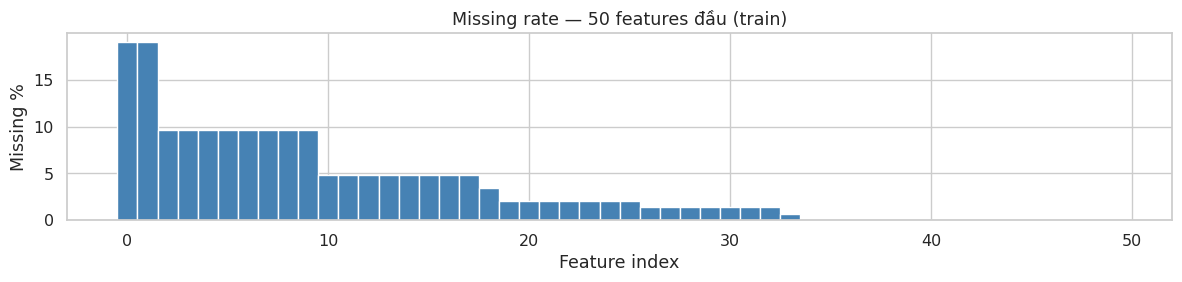

5315

In [46]:
# ============================================================
# 14.8 MISSING RATE SUMMARY (đọc lại từ disk — nhẹ)
# ============================================================

# Đọc chỉ feature columns để check missing
_check_cols = [c for c in FEATURE_COLS if c in
               pd.read_parquet(OUTPUT_DIR/'train_features.parquet', columns=[FEATURE_COLS[0]]).columns]

_miss_check = pd.read_parquet(
    OUTPUT_DIR / 'train_features.parquet',
    columns=FEATURE_COLS[:50]  # chỉ check 50 features đầu để nhanh
).isnull().mean().sort_values(ascending=False)

print('── Missing rate (50 features đầu) ──')
print(f'  Features có missing > 0: {(_miss_check > 0).sum()}')
print('  (NaN ở lag/rolling đầu chuỗi là bình thường)')

plt.figure(figsize=(12, 3))
plt.bar(range(len(_miss_check)), _miss_check.values * 100, color='steelblue', width=1)
plt.xlabel('Feature index')
plt.ylabel('Missing %')
plt.title('Missing rate — 50 features đầu (train)')
plt.tight_layout()
plt.show()

del _miss_check
gc.collect()


---
## 📋 Tóm Tắt Feature Engineering

| Nhóm | Chiến lược | Leakage-safe? |
|------|-----------|---------------|
| Frequency encoding | Fit trên train, map sang test | ✅ |
| Lag features | `groupby.shift(lag)` trong nhóm | ✅ |
| Rolling statistics | `shift(1)` → `rolling(w).agg()` | ✅ |
| Momentum | Hiệu/tỷ lệ của lag đã an toàn | ✅ |
| Volatility | z-score, CV từ rolling đã an toàn | ✅ |
| Group lifecycle | `cumcount`, `expanding` của lag_1 | ✅ |
| Time phase | `ts_index % P`, sin/cos | ✅ |
| Horizon interaction | horizon × lag/rolling | ✅ |
| Cross-sectional rank | rank percentile của lag_1 theo ts_index | ✅ |
| Raw transforms | log, spread (từ raw features) | ✅ |

### Quy trình sử dụng trong Training Loop
```python
# Chỉ cần 3 bước:
train_feat = pd.read_parquet('train_features.parquet')
test_feat  = pd.read_parquet('test_features.parquet')
FEATURE_COLS = json.load(open('feature_cols.json'))
```

### Bước tiếp theo → Modeling notebook
- Rolling Window CV (gap = max horizon = 25)
- LightGBM / CatBoost với `sample_weight = weight`  
- Weighted linear calibration per horizon  
- Ensemble nhiều seeds

---
<a id='model'></a>
# 🚀 PHẦN 3: Modeling — LightGBM


---
<a id='2'></a>
## 2. Metric & Calibration

In [47]:
# ============================================================
# 2. METRIC & CALIBRATION FUNCTIONS
# ============================================================

def weighted_rmse_score(y_true, y_pred, w) -> float:
    """
    Competition metric:
        score = sqrt(1 - clip(sum(w*(y-p)^2) / sum(w*y^2), 0, 1))

    Score = 1.0 → perfect prediction
    Score = 0.0 → predicting all zeros (baseline)
    Cao hơn = tốt hơn.
    """
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    w      = np.asarray(w,      dtype=np.float64)

    denom = np.sum(w * y_true ** 2)
    if denom <= 0:
        return 0.0
    ratio = np.sum(w * (y_true - y_pred) ** 2) / denom
    return float(np.sqrt(1.0 - np.clip(ratio, 0.0, 1.0)))


def zero_baseline_score(y_true, w) -> float:
    """Score khi predict tất cả bằng 0 (baseline tệ nhất)."""
    return weighted_rmse_score(y_true, np.zeros_like(y_true), w)


def mean_baseline_score(y_true, w) -> float:
    """Score khi predict bằng weighted mean (baseline đơn giản)."""
    wmean = np.average(y_true, weights=w)
    return weighted_rmse_score(y_true, np.full_like(y_true, wmean), w)


def weighted_linear_calibration(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    w: np.ndarray,
) -> Tuple[float, float]:
    """
    Tìm a, b tối ưu sao cho a*y_pred + b tối thiểu hoá weighted MSE.
    Giải hệ phương trình tuyến tính bằng weighted OLS:
      a = Cov_w(pred, true) / Var_w(pred)
      b = mean_w(true) - a * mean_w(pred)

    Calibration giúp sửa bias scale và offset của model.
    """
    w_sum = w.sum()
    if w_sum <= 0:
        return 1.0, 0.0

    p_mean = (w * y_pred).sum() / w_sum
    y_mean = (w * y_true).sum() / w_sum

    cov = (w * (y_pred - p_mean) * (y_true - y_mean)).sum()
    var = (w * (y_pred - p_mean) ** 2).sum()

    if var <= 1e-12:
        return 1.0, 0.0

    a = float(cov / var)
    b = float(y_mean - a * p_mean)
    return a, b


print('✅ Metric & calibration functions defined.')

# Sanity check metric
_y = np.array([1.0, 2.0, 3.0, 4.0])
_w = np.ones(4)
assert abs(weighted_rmse_score(_y, _y, _w) - 1.0) < 1e-9,  'Perfect pred must = 1.0'
assert abs(weighted_rmse_score(_y, np.zeros(4), _w)) < 1e-9, 'Zero pred must = 0.0'
print('   Sanity check passed ✅')

✅ Metric & calibration functions defined.
   Sanity check passed ✅


---
<a id='3'></a>
## 3. Load Features từ Disk

In [48]:
# ============================================================
# 3. BRIDGE: Load features cho Modeling
# ============================================================
# Phần 2 đã del train_feat/test_feat để giải phóng RAM.
# Load lại từ file parquet đã lưu ở cell 14.7.

print('Loading features cho modeling...')

import json as _json
with open(OUTPUT_DIR / 'feature_cols.json') as _f:
    FEATURE_COLS = _json.load(_f)

# Loại meta cols khỏi FEATURE_COLS nếu bị lọt vào
META_COLS    = {ID_COL, TIME_COL, TARGET_COL, WEIGHT_COL, '_split'} | set(GROUP_COLS)
FEATURE_COLS = [c for c in FEATURE_COLS if c not in META_COLS]

# Load — đọc toàn bộ (file đã được lọc cột ở bước lưu)
train_feat = pd.read_parquet(OUTPUT_DIR / 'train_features.parquet')
test_feat  = pd.read_parquet(OUTPUT_DIR / 'test_features.parquet')

print(f'  train_feat : {train_feat.shape} | RAM: {memory_mb(train_feat):.1f} MB')
print(f'  test_feat  : {test_feat.shape}  | RAM: {memory_mb(test_feat):.1f} MB')
print(f'  FEATURE_COLS: {len(FEATURE_COLS)} features')
print(f'  Horizons train: {sorted(train_feat["horizon"].unique())}')
print(f'  ts_index train: {train_feat[TIME_COL].min()} → {train_feat[TIME_COL].max()}')
print('✅ Sẵn sàng training.')


Loading features cho modeling...
  train_feat : (5337414, 208) | RAM: 4613.0 MB
  test_feat  : (1447107, 208)  | RAM: 1251.0 MB
  FEATURE_COLS: 199 features
  Horizons train: [np.int8(1), np.int8(3), np.int8(10), np.int8(25)]
  ts_index train: 1 → 3601
✅ Sẵn sàng training.


In [49]:
# ── Kiểm tra missing rate trên feature columns ───────────────
print('── Missing rate của feature columns ──')
feat_miss = train_feat[FEATURE_COLS].isna().mean() * 100
miss_summary = pd.DataFrame({
    'missing_pct': feat_miss,
    'missing_count': (train_feat[FEATURE_COLS].isna().sum()),
}).sort_values('missing_pct', ascending=False)

print(f'  Features không có missing    : {(feat_miss == 0).sum()}')
print(f'  Features có missing ≤ 5%     : {(feat_miss <= 5).sum()}')
print(f'  Features có missing > 30%    : {(feat_miss > 30).sum()}')
print('  (Lag/rolling NaN ở đầu chuỗi là bình thường — LightGBM xử lý tự động)')
display(miss_summary[miss_summary['missing_pct'] > 0].head(15))

── Missing rate của feature columns ──
  Features không có missing    : 92
  Features có missing ≤ 5%     : 181
  Features có missing > 30%    : 0
  (Lag/rolling NaN ở đầu chuỗi là bình thường — LightGBM xử lý tự động)


,missing_pct,missing_count
lag_28,19.04325,1016417
mom_7_28,19.04325,1016417
feature_at,12.47188,665676
feature_by,11.01919,588140
mom_3_14,9.60909,512877
lag_14,9.60909,512877
roll_std_28,9.60909,512877
roll_min_28,9.60909,512877
dev_from_roll_28,9.60909,512877
roll_range_28,9.60909,512877


---
<a id='4'></a>
## 4. Model Configuration (per-horizon)

Mỗi horizon có hyperparameters riêng vì:
- **Horizon 1** (short-term): nhiễu cao, cần regularization chặt
- **Horizon 25** (extra long-term): nhiều structure để học, cần model expressiveness cao hơn

In [50]:
# ============================================================
# 4. MODEL CONFIGURATION
# ============================================================

# ── Base parameters (dùng chung cho mọi horizon) ─────────────
BASE_PARAMS = {
    'objective'       : 'regression',
    'metric'          : 'rmse',

    # Subsampling — tạo diversity giữa các seed
    'feature_fraction': 0.6,   # dùng 60% features mỗi cây
    'bagging_fraction': 0.7,   # dùng 70% rows mỗi cây
    'bagging_freq'    : 5,     # resample mỗi 5 cây

    # Regularization nhẹ L1 (sparsity)
    'lambda_l1'       : 0.1,

    # Misc
    'verbosity'       : -1,
    'n_jobs'          : -1,
}

# ── Per-horizon hyperparameters ───────────────────────────────
# Tuning rationale:
#   - Horizon 1 : chuỗi ngắn hạn rất nhiễu → regularize mạnh (nhiều L2, ít lá)
#   - Horizon 25: tín hiệu dài hạn có structure → cho phép model phức tạp hơn
HORIZON_PARAMS = {
    1: {
        'learning_rate'     : 0.015,
        'n_estimators'      : 4000,
        'num_leaves'        : 70,
        'min_child_samples' : 250,
        'lambda_l2'         : 12.0,
        'early_stopping'    : 200,   # rounds không cải thiện → dừng
    },
    3: {
        'learning_rate'     : 0.015,
        'n_estimators'      : 4000,
        'num_leaves'        : 75,
        'min_child_samples' : 225,
        'lambda_l2'         : 11.0,
        'early_stopping'    : 190,
    },
    10: {
        'learning_rate'     : 0.015,
        'n_estimators'      : 4000,
        'num_leaves'        : 85,
        'min_child_samples' : 180,
        'lambda_l2'         : 9.0,
        'early_stopping'    : 170,
    },
    25: {
        'learning_rate'     : 0.015,
        'n_estimators'      : 4000,
        'num_leaves'        : 90,
        'min_child_samples' : 150,
        'lambda_l2'         : 8.0,
        'early_stopping'    : 160,
    },
}

# ── Print summary ─────────────────────────────────────────────
print('Per-horizon model configuration:')
print(f'{"Horizon":>8} {"Leaves":>8} {"MinChild":>10} {"L2":>8} {"EarlyStop":>12}')
print('-' * 50)
for h, p in HORIZON_PARAMS.items():
    print(f'{h:>8} {p["num_leaves"]:>8} {p["min_child_samples"]:>10} '
          f'{p["lambda_l2"]:>8.1f} {p["early_stopping"]:>12}')

print(f'\nBase params: feature_fraction={BASE_PARAMS["feature_fraction"]}, '
      f'bagging_fraction={BASE_PARAMS["bagging_fraction"]}')
print(f'Multi-seed ensemble: {len(SEEDS)} seeds = {SEEDS}')

Per-horizon model configuration:
 Horizon   Leaves   MinChild       L2    EarlyStop
--------------------------------------------------
       1       70        250     12.0          200
       3       75        225     11.0          190
      10       85        180      9.0          170
      25       90        150      8.0          160

Base params: feature_fraction=0.6, bagging_fraction=0.7
Multi-seed ensemble: 5 seeds = [42, 2024, 777, 1337, 999]


---
<a id='5'></a>
## 5. Weighted Linear Calibration

**Tại sao cần calibration?**  
LightGBM tối ưu RMSE, nhưng metric cuộc thi là **weighted** RMSE. Calibration tuyến tính `a*pred + b` sửa scale và offset của dự báo, thường cải thiện score 0.001–0.003.

In [51]:
# ============================================================
# 5. CALIBRATION DEMO
# ============================================================
# Hàm đã định nghĩa ở cell 2, demo tại đây để minh hoạ

print('Demo calibration trên dữ liệu giả:')

np.random.seed(42)
y_demo = np.random.randn(1000) * 10 + 5
p_demo = y_demo * 0.85 + 1.5 + np.random.randn(1000) * 2   # pred bị lệch scale + bias
w_demo = np.ones(1000)

score_before = weighted_rmse_score(y_demo, p_demo, w_demo)
a, b = weighted_linear_calibration(y_demo, p_demo, w_demo)
p_calib = a * p_demo + b
score_after = weighted_rmse_score(y_demo, p_calib, w_demo)

print(f'  a={a:.4f}, b={b:.4f}')
print(f'  Score trước calibration: {score_before:.5f}')
print(f'  Score sau  calibration : {score_after:.5f}')
print(f'  Cải thiện              : +{score_after - score_before:.5f}')
print('✅ Calibration function verified.')

Demo calibration trên dữ liệu giả:
  a=1.1223, b=-1.6036
  Score trước calibration: 0.97060
  Score sau  calibration : 0.97821
  Cải thiện              : +0.00761
✅ Calibration function verified.


---
<a id='6'></a>
## 6. Training Loop (per-horizon, multi-seed)

**Thiết kế**:
- **Temporal split**: `ts_index ≤ 3500` = train, `> 3500` = validation (mirrors competition structure)
- **Multi-seed ensemble**: 5 seeds × feature/row subsampling → giảm variance mà không cần thêm data  
- **Early stopping**: tránh overfit, dừng khi val metric không cải thiện sau N rounds
- **Calibration per horizon**: sửa scale/bias sau khi ensemble

In [52]:
# ============================================================
# 6. TRAINING LOOP
# ============================================================

# Lưu kết quả validation để tính aggregate score
val_store = {'y': [], 'p': [], 'w': []}
all_test_preds = []
horizon_scores = {}    # lưu score từng horizon để so sánh
all_importances = []   # lưu feature importance

for h in HORIZONS:
    print('=' * 70)
    print(f'  HORIZON = {h}')
    print('=' * 70)

    # ── 6.1 Slice data cho horizon này ──────────────────────────────────
    tr_h   = train_feat[train_feat['horizon'] == h].copy()
    te_h   = test_feat[test_feat['horizon']   == h].copy()

    print(f'  train rows: {len(tr_h):,}  |  test rows: {len(te_h):,}')

    # ── 6.2 Feature set: loại meta & target/weight ───────────────────────
    # FEATURE_COLS đã được clean ở cell 3, dùng trực tiếp
    feats = [c for c in FEATURE_COLS if c in tr_h.columns]
    print(f'  Features used: {len(feats)}')

    # ── 6.3 Temporal train/val split ─────────────────────────────────────
    # Không random split! Luôn dùng temporal để tránh leakage
    tr_mask  = tr_h[TIME_COL] <= VAL_THRESHOLD
    val_mask = tr_h[TIME_COL] >  VAL_THRESHOLD

    X_tr,  y_tr,  w_tr  = (tr_h.loc[tr_mask,  feats],
                            tr_h.loc[tr_mask,  TARGET_COL],
                            tr_h.loc[tr_mask,  WEIGHT_COL])
    X_val, y_val, w_val = (tr_h.loc[val_mask, feats],
                            tr_h.loc[val_mask, TARGET_COL],
                            tr_h.loc[val_mask, WEIGHT_COL])

    print(f'  Train rows: {len(X_tr):,}  (ts ≤ {VAL_THRESHOLD})')
    print(f'  Val   rows: {len(X_val):,}  (ts > {VAL_THRESHOLD})')

    # Kiểm tra val không rỗng
    if len(X_val) == 0:
        print(f'  ⚠️  Không có validation data cho horizon={h}. Bỏ qua calibration.')

    # ── 6.4 Baselines để so sánh ─────────────────────────────────────────
    if len(y_val) > 0:
        b_zero = zero_baseline_score(y_val.values, w_val.values)
        b_mean = mean_baseline_score(y_val.values, w_val.values)
        print(f'  Baselines  → zero={b_zero:.4f} | weighted_mean={b_mean:.4f}')

    # ── 6.5 Build config cho horizon này ─────────────────────────────────
    horizon_cfg   = HORIZON_PARAMS[h].copy()
    early_stop_n  = horizon_cfg.pop('early_stopping')
    params        = {**BASE_PARAMS, **horizon_cfg}

    print(f'  Config → leaves={params["num_leaves"]}, '
          f'min_child={params["min_child_samples"]}, '
          f'L2={params["lambda_l2"]}, '
          f'early_stop={early_stop_n}')

    # ── 6.6 Multi-seed ensemble ───────────────────────────────────────────
    h_val_pred  = np.zeros(len(X_val))
    h_test_pred = np.zeros(len(te_h))
    seed_best_iters = []

    for i, seed in enumerate(SEEDS, 1):
        print(f'  Seed {i}/{len(SEEDS)} (seed={seed})...', end=' ', flush=True)

        p = {**params, 'random_state': seed}
        model = lgb.LGBMRegressor(**p)

        model.fit(
            X_tr, y_tr,
            sample_weight    = w_tr,
            eval_set         = [(X_val, y_val)],
            eval_sample_weight = [w_val],
            callbacks        = [
                lgb.early_stopping(early_stop_n, verbose=False),
                lgb.log_evaluation(period=-1),   # tắt per-round log
            ],
        )

        best_iter = model.best_iteration_
        seed_best_iters.append(best_iter)

        # Tích luỹ prediction (chia trung bình sau)
        h_val_pred  += model.predict(X_val)           / len(SEEDS)
        h_test_pred += model.predict(te_h[feats])     / len(SEEDS)

        # Lưu feature importance (gain)
        imp = pd.DataFrame({
            'feature'  : feats,
            'importance': model.feature_importances_,
            'horizon'  : h,
            'seed'     : seed,
        })
        all_importances.append(imp)

        print(f'best_iter={best_iter} ✓')

    print(f'  Best iters across seeds: {seed_best_iters} '
          f'(mean={np.mean(seed_best_iters):.0f})')

    # ── 6.7 Raw ensemble score ────────────────────────────────────────────
    if len(y_val) > 0:
        score_raw = weighted_rmse_score(y_val.values, h_val_pred, w_val.values)
        print(f'  Raw ensemble score    : {score_raw:.5f}')

    # ── 6.8 Weighted linear calibration ──────────────────────────────────
    if APPLY_CALIB and len(y_val) > 0:
        a, b = weighted_linear_calibration(
            y_val.values, h_val_pred, w_val.values
        )
        h_val_pred  = a * h_val_pred  + b
        h_test_pred = a * h_test_pred + b

        score_calib = weighted_rmse_score(y_val.values, h_val_pred, w_val.values)
        print(f'  Calibration (a={a:.4f}, b={b:.4f})')
        print(f'  Calibrated score      : {score_calib:.5f}  '
              f'(delta={score_calib - score_raw:+.5f})')
        horizon_scores[h] = {'raw': score_raw, 'calibrated': score_calib}
    else:
        horizon_scores[h] = {'raw': score_raw if len(y_val) > 0 else np.nan,
                             'calibrated': np.nan}

    # ── 6.9 Accumulate cho aggregate score ───────────────────────────────
    if len(y_val) > 0:
        val_store['y'].extend(y_val.tolist())
        val_store['p'].extend(h_val_pred.tolist())
        val_store['w'].extend(w_val.tolist())

    all_test_preds.append(pd.DataFrame({
        'id'        : te_h[ID_COL].values,
        'prediction': h_test_pred,
    }))

    # ── 6.10 Giải phóng RAM ───────────────────────────────────────────────
    del tr_h, te_h, X_tr, X_val, y_tr, y_val, w_tr, w_val
    del model, h_val_pred, h_test_pred
    gc.collect()
    print()

  HORIZON = 1
  train rows: 1,394,653  |  test rows: 379,617
  Features used: 199
  Train rows: 1,128,631  (ts ≤ 3000)
  Val   rows: 266,022  (ts > 3000)
  Baselines  → zero=0.0000 | weighted_mean=0.0047
  Config → leaves=70, min_child=250, L2=12.0, early_stop=200
  Seed 1/5 (seed=42)... best_iter=383 ✓
  Seed 2/5 (seed=2024)... best_iter=543 ✓
  Seed 3/5 (seed=777)... best_iter=243 ✓
  Seed 4/5 (seed=1337)... best_iter=237 ✓
  Seed 5/5 (seed=999)... best_iter=293 ✓
  Best iters across seeds: [383, 543, 243, 237, 293] (mean=340)
  Raw ensemble score    : 0.05973
  Calibration (a=1.1665, b=-0.0000)
  Calibrated score      : 0.06039  (delta=+0.00066)

  HORIZON = 3
  train rows: 1,385,816  |  test rows: 376,558
  Features used: 199
  Train rows: 1,121,771  (ts ≤ 3000)
  Val   rows: 264,045  (ts > 3000)
  Baselines  → zero=0.0000 | weighted_mean=0.0086
  Config → leaves=75, min_child=225, L2=11.0, early_stop=190
  Seed 1/5 (seed=42)... best_iter=583 ✓
  Seed 2/5 (seed=2024)... best_iter=3

---
<a id='7'></a>
## 7. Feature Importance Analysis

── Top 30 features (global importance) ──


,feature,importance,rank
0,feature_s_log,4368.15000,1
1,lag_1,4007.00000,2
2,feature_al,2358.85000,3
3,h_x_lag_1,1844.00000,4
4,feature_s,1774.55000,5
5,mom_1_3,1700.60000,6
6,t_global_rank,1486.40000,7
7,sub_category_freq,1366.90000,8
8,feature_ce,1365.95000,9
9,feature_t_log,1301.05000,10


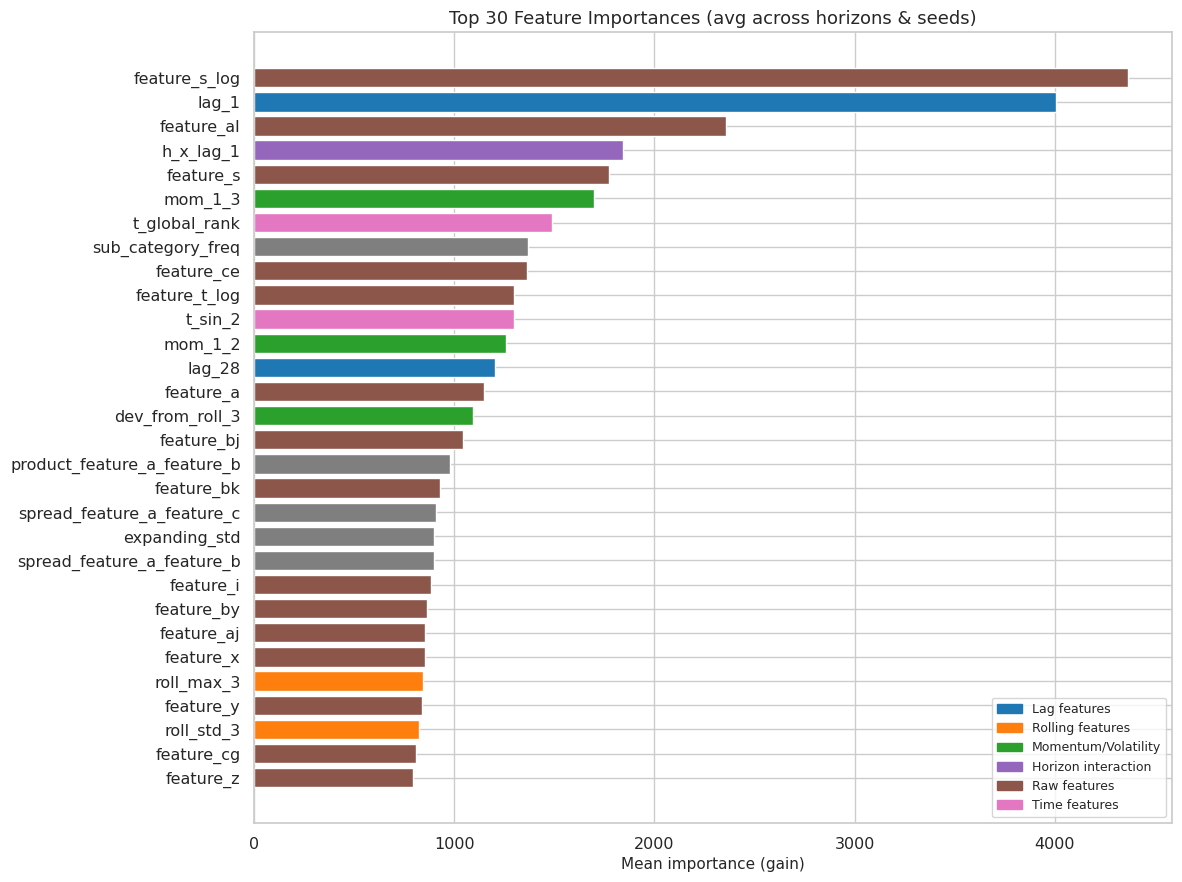

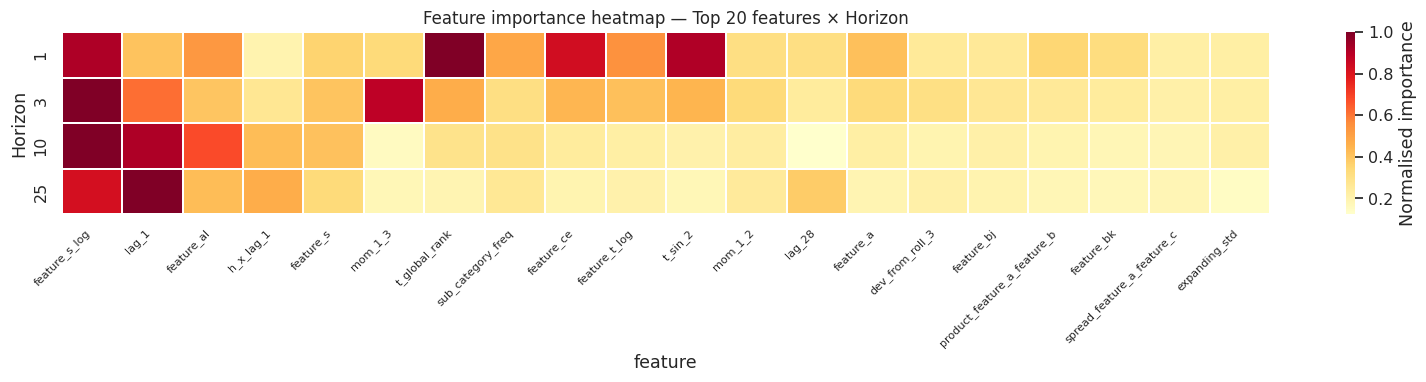


── Bottom 20 features (ít quan trọng nhất) ──
  → Cân nhắc loại bỏ nếu muốn tăng tốc độ training


,feature,importance,rank
179,t_cos_7,151.85000,180
180,feature_j,145.35000,181
181,h_x_cv_28,145.05000,182
182,feature_p,141.00000,183
183,feature_o,140.15000,184
184,t_cos_5,125.60000,185
185,feature_q,121.40000,186
186,t_mod_3,104.90000,187
187,t_mod_2,59.80000,188
188,t_cos_3,41.65000,189


In [53]:
# ============================================================
# 7. FEATURE IMPORTANCE ANALYSIS
# ============================================================

imp_df = pd.concat(all_importances, ignore_index=True)

# ── 7.1 Global importance (trung bình qua tất cả horizons & seeds) ──
global_imp = (
    imp_df
    .groupby('feature')['importance']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)
global_imp['rank'] = range(1, len(global_imp) + 1)

print('── Top 30 features (global importance) ──')
display(global_imp.head(30))

# ── 7.2 Bar chart top 30 ─────────────────────────────────────
top30 = global_imp.head(30)

# Tô màu theo nhóm feature
def feat_color(name):
    if name.startswith('lag_')         : return '#1f77b4'
    if name.startswith('roll_')        : return '#ff7f0e'
    if name.startswith('mom_') or name.startswith('dev_') or name.startswith('zscore_'): return '#2ca02c'
    if name.startswith('h_x_')        : return '#9467bd'
    if name.startswith('feature_')    : return '#8c564b'
    if name.startswith('t_')          : return '#e377c2'
    return '#7f7f7f'

colors = [feat_color(f) for f in top30['feature']]

fig, ax = plt.subplots(figsize=(12, 9))
bars = ax.barh(top30['feature'][::-1], top30['importance'][::-1], color=colors[::-1])
ax.set_xlabel('Mean importance (gain)', fontsize=11)
ax.set_title('Top 30 Feature Importances (avg across horizons & seeds)', fontsize=13)

# Legend
from matplotlib.patches import Patch
legend_elems = [
    Patch(color='#1f77b4', label='Lag features'),
    Patch(color='#ff7f0e', label='Rolling features'),
    Patch(color='#2ca02c', label='Momentum/Volatility'),
    Patch(color='#9467bd', label='Horizon interaction'),
    Patch(color='#8c564b', label='Raw features'),
    Patch(color='#e377c2', label='Time features'),
]
ax.legend(handles=legend_elems, loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

# ── 7.3 Importance heatmap theo horizon ──────────────────────
top20_feats = global_imp.head(20)['feature'].tolist()
pivot = (
    imp_df[imp_df['feature'].isin(top20_feats)]
    .groupby(['horizon', 'feature'])['importance']
    .mean()
    .unstack('feature')
    .reindex(columns=top20_feats)
)

# Normalize theo row (horizon) để dễ so sánh
pivot_norm = pivot.div(pivot.max(axis=1), axis=0)

plt.figure(figsize=(16, 4))
sns.heatmap(
    pivot_norm, annot=False, cmap='YlOrRd',
    linewidths=0.3, cbar_kws={'label': 'Normalised importance'}
)
plt.title('Feature importance heatmap — Top 20 features × Horizon', fontsize=12)
plt.ylabel('Horizon')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.show()

# ── 7.4 Bottom features (thấp nhất — có thể loại bỏ) ─────────
print('\n── Bottom 20 features (ít quan trọng nhất) ──')
print('  → Cân nhắc loại bỏ nếu muốn tăng tốc độ training')
display(global_imp.tail(20))

---
<a id='8'></a>
## 8. Final Score & Submission

  FINAL AGGREGATE LOCAL SCORE : 0.848497

── Per-horizon scores ──


,horizon,raw,calibrated
0,1,0.05973,0.06039
1,3,0.67288,0.67346
2,10,0.86110,0.86169
3,25,0.92170,0.92180


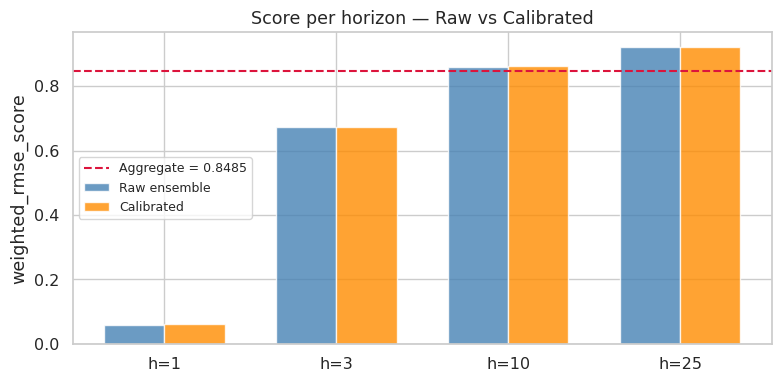


Note: Score được tính trên validation set (ts_index > 3500).
      Đây là proxy đáng tin cậy cho private LB — KHÔNG over-optimize public LB!


In [54]:
# ============================================================
# 8.1 FINAL AGGREGATE SCORE
# ============================================================

final_score = weighted_rmse_score(
    val_store['y'],
    val_store['p'],
    val_store['w'],
)

print('=' * 70)
print(f'  FINAL AGGREGATE LOCAL SCORE : {final_score:.6f}')
print('=' * 70)

# ── Per-horizon score summary ─────────────────────────────────
print('\n── Per-horizon scores ──')
h_score_df = pd.DataFrame(horizon_scores).T
h_score_df.index.name = 'horizon'
h_score_df = h_score_df.reset_index()
display(h_score_df)

# ── Bar chart per-horizon ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(HORIZONS))
w = 0.35

raw_vals   = [horizon_scores[h].get('raw',        np.nan) for h in HORIZONS]
calib_vals = [horizon_scores[h].get('calibrated', np.nan) for h in HORIZONS]

ax.bar(x - w/2, raw_vals,   w, label='Raw ensemble',  color='steelblue',  alpha=0.8)
ax.bar(x + w/2, calib_vals, w, label='Calibrated',    color='darkorange', alpha=0.8)
ax.axhline(final_score, color='crimson', linestyle='--', linewidth=1.5,
           label=f'Aggregate = {final_score:.4f}')

ax.set_xticks(x)
ax.set_xticklabels([f'h={h}' for h in HORIZONS])
ax.set_ylabel('weighted_rmse_score')
ax.set_title('Score per horizon — Raw vs Calibrated')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print('\nNote: Score được tính trên validation set (ts_index > 3500).')
print('      Đây là proxy đáng tin cậy cho private LB — KHÔNG over-optimize public LB!')

── Prediction diagnostics trên validation set ──
  N validation rows: 1,014,824
  y_true — mean: -0.1068 | std: 27.9771
  y_pred — mean: -0.2542 | std: 23.1820
  Residual mean  : 0.1474
  Residual std   : 13.8465


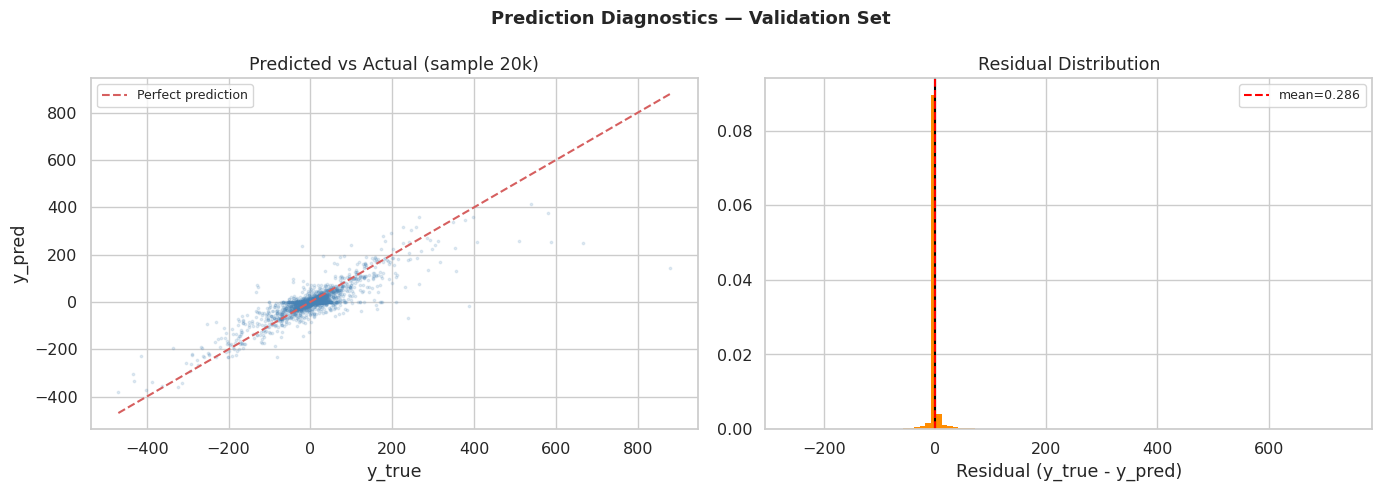

In [55]:
# ============================================================
# 8.2 PREDICTION DIAGNOSTICS
# ============================================================

print('── Prediction diagnostics trên validation set ──')

val_df = pd.DataFrame({
    'y_true': val_store['y'],
    'y_pred': val_store['p'],
    'weight': val_store['w'],
})

print(f'  N validation rows: {len(val_df):,}')
print(f'  y_true — mean: {val_df.y_true.mean():.4f} | std: {val_df.y_true.std():.4f}')
print(f'  y_pred — mean: {val_df.y_pred.mean():.4f} | std: {val_df.y_pred.std():.4f}')
print(f'  Residual mean  : {(val_df.y_true - val_df.y_pred).mean():.4f}')
print(f'  Residual std   : {(val_df.y_true - val_df.y_pred).std():.4f}')

# ── Scatter: predicted vs actual (sample) ────────────────────
sample_idx = np.random.choice(len(val_df), min(20_000, len(val_df)), replace=False)
sample_val = val_df.iloc[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter
axes[0].scatter(sample_val.y_true, sample_val.y_pred,
                alpha=0.15, s=3, color='steelblue')
lim_min = min(sample_val.y_true.min(), sample_val.y_pred.min())
lim_max = max(sample_val.y_true.max(), sample_val.y_pred.max())
axes[0].plot([lim_min, lim_max], [lim_min, lim_max],
             'r--', linewidth=1.5, label='Perfect prediction')
axes[0].set_xlabel('y_true')
axes[0].set_ylabel('y_pred')
axes[0].set_title('Predicted vs Actual (sample 20k)')
axes[0].legend(fontsize=9)

# Residual distribution
residuals = sample_val.y_true - sample_val.y_pred
axes[1].hist(residuals, bins=100, color='darkorange', edgecolor='none', density=True)
axes[1].axvline(0, color='black', linewidth=1.5)
axes[1].axvline(residuals.mean(), color='red', linestyle='--',
                linewidth=1.5, label=f'mean={residuals.mean():.3f}')
axes[1].set_xlabel('Residual (y_true - y_pred)')
axes[1].set_title('Residual Distribution')
axes[1].legend(fontsize=9)

plt.suptitle('Prediction Diagnostics — Validation Set', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# 8.3 TẠO & LƯU SUBMISSION
# ============================================================

submission = pd.concat(all_test_preds, ignore_index=True)

# Đảm bảo id là string & không có NaN
assert submission['prediction'].isna().sum() == 0, 'Có NaN trong predictions!'
assert submission['id'].duplicated().sum() == 0, 'Có duplicate id!'

submission.to_csv(OUTPUT_DIR / 'submission.csv', index=False)

print('✅ submission.csv saved!')
print(f'\n  Rows      : {len(submission):,}')
print(f'  Mean pred : {submission["prediction"].mean():.6f}')
print(f'  Std  pred : {submission["prediction"].std():.6f}')
print(f'  Min  pred : {submission["prediction"].min():.4f}')
print(f'  Max  pred : {submission["prediction"].max():.4f}')
print(f'\n  LOCAL SCORE: {final_score:.6f}')

# Preview
display(submission.head(10))

✅ submission.csv saved!

  Rows      : 1,447,107
  Mean pred : -0.114030
  Std  pred : 0.752010
  Min  pred : -172.2479
  Max  pred : 202.1515

  LOCAL SCORE: 0.848497


,id,prediction
0,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4175,-0.04661
1,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4176,-0.04736
2,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4177,-0.04738
3,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4178,-0.04423
4,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4179,-0.04876
5,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4180,-0.04933
6,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4182,-0.04869
7,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4183,-0.05062
8,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4184,-0.04189
9,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4185,-0.04950


---
<a id='9'></a>
## 9. Pre-Submission Leakage Checklist

Trước khi submit, kiểm tra tất cả các mục dưới đây:

In [57]:
# ============================================================
# 9. PRE-SUBMISSION LEAKAGE CHECKLIST
# ============================================================

checklist = [
    # (Mô tả, Status, Ghi chú)
    ('Không dùng shift(-N) / negative lag',
     True,
     'add_lag_features chỉ dùng shift(+k)'),

    ('Rolling window dùng shift(1) trước (không center=True)',
     True,
     'add_rolling_features: grouped.shift(1).rolling(w)'),

    ('FrequencyEncoder fit CHỈ trên train',
     True,
     'freq_enc.fit(train_raw) — không dùng test data'),

    ('Calibration fit trên validation, áp dụng cho test',
     APPLY_CALIB,
     'weighted_linear_calibration(y_val, val_pred, w_val)'),

    ('Cross-sectional rank tính theo ts_index (không temporal rank)',
     True,
     'add_crosssectional_rank: groupby(ts_index).rank(pct=True)'),

    ('Không dùng target để tính features trên test',
     True,
     'test target = NaN; lag/rolling từ train→test qua concat'),

    ('Không có external data chứa future information',
     True,
     'Chỉ dùng dữ liệu từ competition'),

    ('Temporal CV split (không random split)',
     True,
     f'Split tại ts_index = {VAL_THRESHOLD}'),

    ('Prediction không chứa NaN',
     submission['prediction'].isna().sum() == 0,
     f'NaN count: {submission["prediction"].isna().sum()}'),

    ('Prediction id không bị trùng',
     submission['id'].duplicated().sum() == 0,
     f'Duplicate id: {submission["id"].duplicated().sum()}'),

    ('Local score đã được tính trước khi submit',
     True,
     f'Local score = {final_score:.6f}'),
]

print('=' * 70)
print('  PRE-SUBMISSION CHECKLIST')
print('=' * 70)

all_pass = True
for desc, status, note in checklist:
    icon = '✅' if status else '❌'
    print(f'  {icon}  {desc}')
    print(f'       → {note}')
    if not status:
        all_pass = False

print('=' * 70)
if all_pass:
    print('  🎉 TẤT CẢ CHECKS ĐỀU PASS — AN TOÀN ĐỂ SUBMIT!')
else:
    print('  ⚠️  MỘT SỐ CHECKS FAILED — KIỂM TRA LẠI TRƯỚC KHI SUBMIT!')
print('=' * 70)

  PRE-SUBMISSION CHECKLIST
  ✅  Không dùng shift(-N) / negative lag
       → add_lag_features chỉ dùng shift(+k)
  ✅  Rolling window dùng shift(1) trước (không center=True)
       → add_rolling_features: grouped.shift(1).rolling(w)
  ✅  FrequencyEncoder fit CHỈ trên train
       → freq_enc.fit(train_raw) — không dùng test data
  ✅  Calibration fit trên validation, áp dụng cho test
       → weighted_linear_calibration(y_val, val_pred, w_val)
  ✅  Cross-sectional rank tính theo ts_index (không temporal rank)
       → add_crosssectional_rank: groupby(ts_index).rank(pct=True)
  ✅  Không dùng target để tính features trên test
       → test target = NaN; lag/rolling từ train→test qua concat
  ✅  Không có external data chứa future information
       → Chỉ dùng dữ liệu từ competition
  ✅  Temporal CV split (không random split)
       → Split tại ts_index = 3000
  ✅  Prediction không chứa NaN
       → NaN count: 0
  ✅  Prediction id không bị trùng
       → Duplicate id: 0
  ✅  Local score đã đư

In [58]:
# ============================================================
# 9. TỔNG KẾT & HƯỚNG CẢI THIỆN
# ============================================================

summary_md = f"""
## 📋 Kết Quả & Hướng Cải Thiện

### Kết quả hiện tại
| Metric | Giá trị |
|--------|---------|
| **Local CV score** | `{final_score:.6f}` |
| Validation split | `ts_index > {VAL_THRESHOLD}` |
| Model | LightGBM ({len(SEEDS)} seeds ensemble) |
| Features | {len(FEATURE_COLS)} features |
| Calibration | {'✅ Applied' if APPLY_CALIB else '❌ Not applied'} |

### Per-horizon scores
{''.join([f'- **Horizon {h}**: raw={horizon_scores[h]["raw"]:.5f} | calibrated={horizon_scores[h]["calibrated"]:.5f}' + chr(10) for h in HORIZONS])}

### Hướng cải thiện score

**Ngắn hạn (dễ làm):**
- 🔧 Loại bỏ bottom 20 features theo importance → giảm overfitting
- 🔧 Tăng `n_estimators` lên 6000 nếu còn budget training
- 🔧 Thử `feature_fraction=0.5` để tăng diversity giữa seeds

**Trung hạn:**
- 📊 Rolling window dài hơn (lag_60, roll_mean_60) nếu chuỗi đủ dài
- 📊 Target encoding với strict temporal fold (mean của nhóm tại t-1)
- 📊 Thêm CatBoost model rồi blend với LightGBM

**Dài hạn:**
- 🚀 Optuna hyperparameter tuning per horizon (100+ trials)
- 🚀 Stacking: LightGBM + CatBoost + XGBoost meta-learner
- 🚀 Time-series specific features: FFT coefficients, wavelet transforms

### ⚠️ Cảnh báo quan trọng
- Public LB chỉ dùng **25% test** — private LB mới là 75% còn lại
- Luôn ưu tiên **local CV score** hơn public LB khi ra quyết định
- Mọi thay đổi feature phải qua **leakage check** trước khi submit
"""

display(Markdown(summary_md))


## 📋 Kết Quả & Hướng Cải Thiện

### Kết quả hiện tại
| Metric | Giá trị |
|--------|---------|
| **Local CV score** | `0.848497` |
| Validation split | `ts_index > 3000` |
| Model | LightGBM (5 seeds ensemble) |
| Features | 199 features |
| Calibration | ✅ Applied |

### Per-horizon scores
- **Horizon 1**: raw=0.05973 | calibrated=0.06039
- **Horizon 3**: raw=0.67288 | calibrated=0.67346
- **Horizon 10**: raw=0.86110 | calibrated=0.86169
- **Horizon 25**: raw=0.92170 | calibrated=0.92180


### Hướng cải thiện score

**Ngắn hạn (dễ làm):**
- 🔧 Loại bỏ bottom 20 features theo importance → giảm overfitting
- 🔧 Tăng `n_estimators` lên 6000 nếu còn budget training
- 🔧 Thử `feature_fraction=0.5` để tăng diversity giữa seeds

**Trung hạn:**
- 📊 Rolling window dài hơn (lag_60, roll_mean_60) nếu chuỗi đủ dài
- 📊 Target encoding với strict temporal fold (mean của nhóm tại t-1)
- 📊 Thêm CatBoost model rồi blend với LightGBM

**Dài hạn:**
- 🚀 Optuna hyperparameter tuning per horizon (100+ trials)
- 🚀 Stacking: LightGBM + CatBoost + XGBoost meta-learner
- 🚀 Time-series specific features: FFT coefficients, wavelet transforms

### ⚠️ Cảnh báo quan trọng
- Public LB chỉ dùng **25% test** — private LB mới là 75% còn lại
- Luôn ưu tiên **local CV score** hơn public LB khi ra quyết định
- Mọi thay đổi feature phải qua **leakage check** trước khi submit
